# Initial Setup

Import packages


1.   pandas : dataset manipulation & descriptive analysis
2.   numpy : handling arrays operations
3.   matplotlib & seaborn : data visualization
4.   scipy & statsmodels : statistical analysis
5.   sklearn : machine learning



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import math

from scipy.stats import mannwhitneyu, chi2_contingency, chi2
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve

Settings to show all rows & columns permanently for the rest of this notebook

In [ ]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

# Upload Data

Connecting to github repository

In [ ]:
!git clone https://github.com/celynhs/HR-Analytics.git

fatal: destination path 'HR-Analytics' already exists and is not an empty directory.


Reading the datasets

In [ ]:
hr = pd.read_csv('/content/HR-Analytics/employee_attrition_hr_2026.csv')

# Data Cleaning

In [ ]:
hr.head()

,employee_id,age,gender,marital_status,education_level,department,job_role,job_level,monthly_income,stock_option_level,salary_hike_pct,years_at_company,total_working_years,years_since_promotion,num_prior_companies,work_mode,commute_minutes,overtime_hours_per_week,business_travel_days_per_year,training_hours,manager_support_score,burnout_score,engagement_score,work_life_balance_score,performance_rating,last_review_score,uses_ai_tools_at_work,perceived_ai_job_risk,attrition
0,1001,37,Male,Divorced,Masters,Engineering,Engineering Manager,3,7365,0,14.1,7.3,15.9,1.5,3,Remote,5,2.4,6,17,9.4,1.0,9.7,7.7,3,8.3,True,4.8,No
1,1002,24,Female,Married,Bachelors,Finance,Finance Manager,2,4746,2,7.9,3.0,4.0,2.5,3,Onsite,7,4.1,5,21,4.2,1.9,5.4,7.8,3,8.0,True,2.9,Yes
2,1003,24,Female,Single,Bachelors,Marketing,Marketing Specialist,1,2740,2,12.8,3.0,4.0,1.3,3,Hybrid,28,3.3,7,22,7.5,5.3,6.5,7.0,4,9.5,True,7.2,No
3,1004,44,Male,Single,Bachelors,Sales,Sales Manager,4,7334,1,12.8,9.2,12.5,0.5,0,Hybrid,19,12.0,21,21,8.7,4.3,7.3,3.5,4,7.9,False,5.2,No
4,1005,37,Female,Divorced,Bachelors,Sales,Sales Development Rep,3,9096,0,10.6,4.9,10.5,0.2,0,Hybrid,36,4.9,20,20,7.5,2.3,7.0,7.2,4,8.5,False,6.4,No


In [ ]:
hr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   employee_id                    5000 non-null   int64  
 1   age                            5000 non-null   int64  
 2   gender                         5000 non-null   object 
 3   marital_status                 5000 non-null   object 
 4   education_level                5000 non-null   object 
 5   department                     5000 non-null   object 
 6   job_role                       5000 non-null   object 
 7   job_level                      5000 non-null   int64  
 8   monthly_income                 5000 non-null   int64  
 9   stock_option_level             5000 non-null   int64  
 10  salary_hike_pct                5000 non-null   float64
 11  years_at_company               5000 non-null   float64
 12  total_working_years            5000 non-null   f

In [ ]:
hr.describe()

,employee_id,age,job_level,monthly_income,stock_option_level,salary_hike_pct,years_at_company,total_working_years,years_since_promotion,num_prior_companies,commute_minutes,overtime_hours_per_week,business_travel_days_per_year,training_hours,manager_support_score,burnout_score,engagement_score,work_life_balance_score,performance_rating,last_review_score,perceived_ai_job_risk
count,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3500.500000,37.119800,2.925200,6990.71980,1.089800,11.518200,6.724620,11.69926,1.971900,1.805200,31.160200,6.828220,10.819000,22.598800,6.613500,4.033360,6.507980,6.130360,3.615800,8.330920,4.856720
std,1443.520003,8.234161,1.201621,2701.89936,0.936542,3.408021,3.500219,4.99587,1.628239,1.345665,19.435073,4.470515,8.092227,11.006019,1.836603,1.540043,1.497677,1.288287,0.661421,1.149132,1.832426
min,1001.000000,21.000000,1.000000,1500.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.800000,1.000000
25%,2250.750000,31.000000,2.000000,4971.00000,0.000000,9.300000,4.275000,8.30000,0.800000,1.000000,14.000000,3.600000,5.000000,15.000000,5.400000,2.900000,5.500000,5.300000,3.000000,7.500000,3.600000
50%,3500.500000,37.000000,3.000000,6569.00000,1.000000,11.600000,6.800000,11.90000,1.600000,2.000000,33.000000,5.900000,7.000000,22.000000,6.700000,4.000000,6.500000,6.200000,4.000000,8.400000,4.900000
75%,4750.250000,43.000000,4.000000,8604.25000,2.000000,13.800000,9.200000,15.10000,2.800000,3.000000,46.000000,9.000000,18.000000,30.000000,7.900000,5.000000,7.600000,7.000000,4.000000,9.200000,6.100000
max,6000.000000,64.000000,5.000000,21609.00000,3.000000,22.600000,18.100000,30.40000,11.100000,8.000000,92.000000,34.900000,38.000000,67.000000,10.000000,10.000000,10.000000,9.900000,5.000000,10.000000,10.000000


In [ ]:
categorical_cols = hr.select_dtypes(include='object')
ordinal_cols = ['job_level', 'stock_option_level', 'performance_rating']
categorical_cols = [c for c in categorical_cols]
categorical_cols += ordinal_cols

categorical_cols

['gender',
 'marital_status',
 'education_level',
 'department',
 'job_role',
 'work_mode',
 'attrition',
 'job_level',
 'stock_option_level',
 'performance_rating']

In [ ]:
for i in categorical_cols:
  print(" "*20,i," "*20)
  print(hr[i].value_counts())
  print("-"*50)

                     gender                     
gender
Male                 2492
Female               2310
Non-binary            100
Prefer not to say      98
Name: count, dtype: int64
--------------------------------------------------
                     marital_status                     
marital_status
Married     2387
Single      2070
Divorced     543
Name: count, dtype: int64
--------------------------------------------------
                     education_level                     
education_level
Bachelors      2562
Masters        1534
High School     512
PhD             392
Name: count, dtype: int64
--------------------------------------------------
                     department                     
department
Engineering               1336
Sales                      835
Operations                 663
Customer Support           636
Marketing                  440
Finance                    436
Research & Development     410
Human Resources            244
Name: count, dtype: 

Based on the results above, it seems that there's no null value and every column is typed correctly. There seems to be no error as well after checking the groups/categories from each categorical and ordinal column. Next would be to do sanity checks on relevant columns to ensure the values makes sense.

In [ ]:
mgr = hr['job_role'].str.contains('Manager|Lead')

checks = {
    # Structural
    'Duplicate employee_id':            hr['employee_id'].duplicated(),
    'Duplicate rows (excl. ID)':        hr.drop(columns='employee_id').duplicated(),
    # Range
    'Score outside 1–10':               (hr[['manager_support_score','burnout_score','engagement_score',
                                             'work_life_balance_score','last_review_score',
                                             'perceived_ai_job_risk']].lt(1) |
                                         hr[['manager_support_score','burnout_score','engagement_score',
                                             'work_life_balance_score','last_review_score',
                                             'perceived_ai_job_risk']].gt(10)).any(axis=1),
    'Negative numeric value':           (hr.select_dtypes('number') < 0).any(axis=1),
    'Age outside 18–67':                ~hr['age'].between(18, 67),
    # Cross-field logic
    'Tenure > total working years':     hr['years_at_company'] > hr['total_working_years'],
    'Years since promotion > tenure':   hr['years_since_promotion'] > hr['years_at_company'],
    'Career start age < 16':            (hr['age'] - hr['total_working_years']) < 16,
    'Prior companies > years worked':   hr['num_prior_companies'] > hr['total_working_years'] + 1,
    '0 prior companies but worked elsewhere': (hr['num_prior_companies'] == 0) &
                                         (hr['total_working_years'] > hr['years_at_company'] + 1),
    'PhD under 26':                     (hr['education_level'] == 'PhD') & (hr['age'] < 26),
    'Masters under 23':                 (hr['education_level'] == 'Masters') & (hr['age'] < 23),
    'Manager/Lead at level 1–2':        mgr & (hr['job_level'] <= 2),
    'Non-manager at level 5':           ~mgr & (hr['job_level'] == 5),
    'Rating 2 but review score ≥ 9':    (hr['performance_rating'] == 2) & (hr['last_review_score'] >= 9),
}

validation_log = pd.DataFrame({
    'check': checks.keys(),
    'rows_flagged': [int(m.sum()) for m in checks.values()],
    'pct_of_rows': [round(m.mean() * 100, 2) for m in checks.values()],
})
validation_log['status'] = validation_log['rows_flagged'].map(lambda n: 'Pass' if n == 0 else 'Review')
display(validation_log)

# Keep the flags on the data so you can filter or exclude later
for name, mask in checks.items():
    hr['flag_' + name.lower().replace(' ', '_').replace('/', '_')] = mask

,check,rows_flagged,pct_of_rows,status
0,Duplicate employee_id,0,0.00,Pass
1,Duplicate rows (excl. ID),0,0.00,Pass
2,Score outside 1–10,0,0.00,Pass
3,Negative numeric value,0,0.00,Pass
4,Age outside 18–67,0,0.00,Pass
5,Tenure > total working years,59,1.18,Review
6,Years since promotion > tenure,0,0.00,Pass
7,Career start age < 16,0,0.00,Pass
8,Prior companies > years worked,40,0.80,Review
9,0 prior companies but worked elsewhere,604,12.08,Review


In [ ]:
any_flag = pd.concat(checks, axis=1).any(axis=1)
print(f"Rows with at least one flag: {any_flag.sum()} ({any_flag.mean():.1%})")

Rows with at least one flag: 1358 (27.2%)


**Data validation: findings**

I ran 15 sanity checks covering structure, valid ranges and logical consistency between columns.

**Passed (7 of 15 checks)**
- **Structure:** no duplicate employee IDs and no duplicate records.
- **Valid ranges:** all scores are within 1–10, no numeric column has negative values, and all ages (21–64) are within working age.
- **Basic career logic:** years since promotion never exceeds tenure, and every employee started working at age 16 or older.

**Flagged for review (8 of 15 checks):** 1,358 employees (27.2%) have at least one flag. They fall into three groups:

1. **Impossible values (59 employees, ~1.2%)**
   - *Tenure > total working years* (59): years at the company cannot exceed total career length. The gap is small (median 0.6 years, max 3.5), which points to rounding or data-entry error rather than random noise.

2. **Inconsistent work-history fields (604 employees, 12.1%)**
   - *0 prior companies but worked elsewhere*: these employees report no previous employers, yet their total working years exceed their tenure by more than a year. Either `num_prior_companies` or `total_working_years` is unreliable for this group.

3. **Unlikely but possible combinations (801 flags)**
   - *Education vs age:* 37 PhDs under 26 and 69 Masters graduates under 23. Rare but achievable (accelerated study), so these are not treated as errors.
   - *Job role vs level:* 396 Manager/Lead roles at levels 1–2 and 239 non-manager roles at level 5. This suggests job level was not assigned according to role. Job title and job level may each be valid, but they can't be used together to infer seniority.
   - *Performance rating vs review score:* 20 employees rated 2 ("below expectations") but scoring 9+ on their last review. The overall correlation between the two is only 0.28, so they measure different things or come from different review cycles.
   - *Prior companies > years worked* (40): for example, 3 previous employers in under 2 years of career. Not strictly impossible, but implausible at this rate.

In [ ]:
flag_cols = [col for col in hr.columns if "flag" in col]
issue_flags = [col for col in flag_cols if hr[col].any()]
issue_flags

['flag_tenure_>_total_working_years',
 'flag_prior_companies_>_years_worked',
 'flag_0_prior_companies_but_worked_elsewhere',
 'flag_phd_under_26',
 'flag_masters_under_23',
 'flag_manager_lead_at_level_1–2',
 'flag_non-manager_at_level_5',
 'flag_rating_2_but_review_score_≥_9']

In [ ]:
column_to_check = 'flag_rating_2_but_review_score_≥_9' # change this to see specific flag columns
hr[hr[column_to_check]==True]

,employee_id,age,gender,marital_status,education_level,department,job_role,job_level,monthly_income,stock_option_level,salary_hike_pct,years_at_company,total_working_years,years_since_promotion,num_prior_companies,work_mode,commute_minutes,overtime_hours_per_week,business_travel_days_per_year,training_hours,manager_support_score,burnout_score,engagement_score,work_life_balance_score,performance_rating,last_review_score,uses_ai_tools_at_work,perceived_ai_job_risk,attrition,flag_duplicate_employee_id,flag_duplicate_rows_(excl._id),flag_score_outside_1–10,flag_negative_numeric_value,flag_age_outside_18–67,flag_tenure_>_total_working_years,flag_years_since_promotion_>_tenure,flag_career_start_age_<_16,flag_prior_companies_>_years_worked,flag_0_prior_companies_but_worked_elsewhere,flag_phd_under_26,flag_masters_under_23,flag_manager_lead_at_level_1–2,flag_non-manager_at_level_5,flag_rating_2_but_review_score_≥_9
554,1555,35,Male,Single,Bachelors,Finance,Financial Analyst,2,4710,1,12.5,4.8,9.8,1.8,2,Hybrid,38,6.9,2,0,3.7,6.2,5.0,5.2,2,9.0,False,6.3,Yes,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
604,1605,33,Male,Single,Masters,Customer Support,Support Team Lead,3,4823,0,18.3,6.5,13.0,1.3,3,Hybrid,28,11.0,4,2,5.3,6.2,3.7,5.6,2,9.7,True,5.0,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1092,2093,33,Male,Single,Bachelors,Sales,Account Executive,3,5453,0,7.4,3.0,12.1,3.0,3,Onsite,18,7.9,27,15,5.7,4.5,3.9,7.6,2,9.5,False,4.0,Yes,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1101,2102,36,Female,Married,High School,Operations,Program Manager,3,5840,0,13.4,7.6,16.0,0.3,4,Onsite,19,0.9,19,26,5.7,3.4,6.0,7.4,2,9.0,False,4.3,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1349,2350,35,Male,Married,Bachelors,Sales,Sales Manager,4,5696,1,8.9,7.6,15.0,3.1,4,Hybrid,47,3.8,21,9,5.0,4.3,5.3,6.4,2,9.0,False,7.0,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2301,3302,44,Male,Single,PhD,Customer Support,Support Team Lead,3,7166,0,9.3,5.5,14.5,1.2,2,Hybrid,45,7.9,8,39,6.5,5.3,4.7,7.1,2,9.3,False,7.2,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2619,3620,43,Male,Married,Bachelors,Operations,Operations Analyst,5,7524,2,11.3,6.5,8.8,0.6,0,Onsite,34,11.7,18,22,3.4,6.4,4.3,5.8,2,9.1,True,6.6,Yes,False,False,False,False,False,False,False,False,False,True,False,False,False,True,True
2917,3918,44,Male,Single,Masters,Customer Support,Support Specialist,4,6229,1,10.7,8.7,15.4,0.3,3,Hybrid,71,4.4,7,17,7.7,5.2,6.2,6.0,2,9.4,True,4.6,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2996,3997,42,Male,Married,High School,Finance,Financial Analyst,3,5063,1,12.1,11.1,21.9,0.0,5,Onsite,32,2.8,2,21,6.0,3.6,4.8,7.5,2,9.5,False,6.7,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3300,4301,51,Male,Married,Masters,Engineering,Engineering Manager,3,7676,1,8.2,8.9,17.5,1.9,3,Onsite,48,7.0,5,42,2.3,7.4,3.4,4.7,2,9.5,False,4.3,No,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True


In [ ]:
# Drop the flags that found nothing
clean_flags = [col for col in flag_cols if col not in issue_flags]

hr = hr.drop(columns=clean_flags)

# One summary column: does this row have any issue?
hr['flag_any_issue'] = hr[issue_flags].any(axis=1)

# Show how many rows each remaining flag caught
display(hr[issue_flags].sum().sort_values(ascending=False).to_frame('rows_flagged'))

,rows_flagged
flag_0_prior_companies_but_worked_elsewhere,604
flag_manager_lead_at_level_1–2,396
flag_non-manager_at_level_5,239
flag_masters_under_23,69
flag_tenure_>_total_working_years,59
flag_prior_companies_>_years_worked,40
flag_phd_under_26,37
flag_rating_2_but_review_score_≥_9,20


**Data validation: actions and considerations**

**Actions taken**
1. **Impossible values (59 employees):** excluded from analyses that use `years_at_company` or `total_working_years`, but kept for all other analyses. Their attrition rate (15.3%) is slightly lower than the rest of the dataset (17.9%), but with only 59 rows (1.2% of the data), excluding them has little effect on overall results. Values were not corrected, since there is no reliable way to know which of the two figures is wrong.
2. **Flag columns kept in the dataset:** each issue has its own `flag_` column plus `flag_any_issue`, so results can be re-run with or without flagged rows as a robustness check.

**Considerations (no change to the data)**
- **Removing all flagged rows is not appropriate.** It would remove 27% of the data, mostly for combinations that are possible rather than wrong.
- **Work history (644 employees):** `num_prior_companies` is questionable in two ways: 604 employees report no previous employers despite having worked elsewhere, and 40 report more employers than their years of work would allow. It will be treated with caution: not used as a key driver in conclusions, and the model will be compared with and without it.
- **Job role vs level (635 employees):** `job_level` will be the measure of seniority and `job_role` will describe the type of work. No conclusions will be drawn from combining the two, for example "managers are less likely to leave".
- **Education vs age (106 employees):** kept as they are. These combinations are uncommon but plausible.
- **Rating vs review score (20 employees):** both columns kept but analysed separately, since they don't consistently agree. `performance_rating` will be the main performance measure, as it's the standard field used in HR reporting.
- **Robustness check:** key findings (e.g. attrition drivers in the model) will be re-run excluding `flag_any_issue` rows. If the conclusions hold, the flagged data isn't driving the results.

**Performing normality test on numerical columns**

In [ ]:
num_cols = hr.select_dtypes(include='number').columns.drop('employee_id')
ordinal_cols = ['job_level', 'stock_option_level', 'performance_rating']
cont_cols = [c for c in num_cols if c not in ordinal_cols]
cont_cols

['age',
 'monthly_income',
 'salary_hike_pct',
 'years_at_company',
 'total_working_years',
 'years_since_promotion',
 'num_prior_companies',
 'commute_minutes',
 'overtime_hours_per_week',
 'business_travel_days_per_year',
 'training_hours',
 'manager_support_score',
 'burnout_score',
 'engagement_score',
 'work_life_balance_score',
 'last_review_score',
 'perceived_ai_job_risk']

In [ ]:
rows = []
for col in cont_cols:
    x = hr[col].dropna()
    sw_stat, sw_p = stats.shapiro(x)        # Shapiro-Wilk
    dp_stat, dp_p = stats.normaltest(x)     # D'Agostino-Pearson (skew + kurtosis)
    rows.append({
        'column': col,
        'skewness': round(x.skew(), 2),
        'kurtosis': round(x.kurt(), 2),     # excess kurtosis: 0 = normal
        'shapiro_p': sw_p,
        'dagostino_p': dp_p,
        'normal (p > 0.05)': 'Yes' if dp_p > 0.05 else 'No'
    })

normality = pd.DataFrame(rows).sort_values('skewness', key=abs, ascending=False)
normality

,column,skewness,kurtosis,shapiro_p,dagostino_p,normal (p > 0.05)
5,years_since_promotion,1.35,2.52,2.443731e-49,2.903695e-263,No
8,overtime_hours_per_week,1.31,2.52,5.783159e-47,9.891452e-255,No
9,business_travel_days_per_year,1.00,-0.26,6.849715e-57,4.724583e-134,No
1,monthly_income,0.83,0.76,6.461578e-36,1.290783e-112,No
6,num_prior_companies,0.72,0.35,3.366140e-47,8.887893e-81,No
15,last_review_score,-0.42,-0.32,1.861339e-32,6.334126e-37,No
12,burnout_score,0.36,0.12,5.411038e-19,6.114895e-23,No
14,work_life_balance_score,-0.31,0.33,5.138227e-14,1.712850e-21,No
11,manager_support_score,-0.23,-0.29,2.490935e-19,1.740294e-15,No
0,age,0.17,-0.33,3.601910e-17,3.661000e-13,No


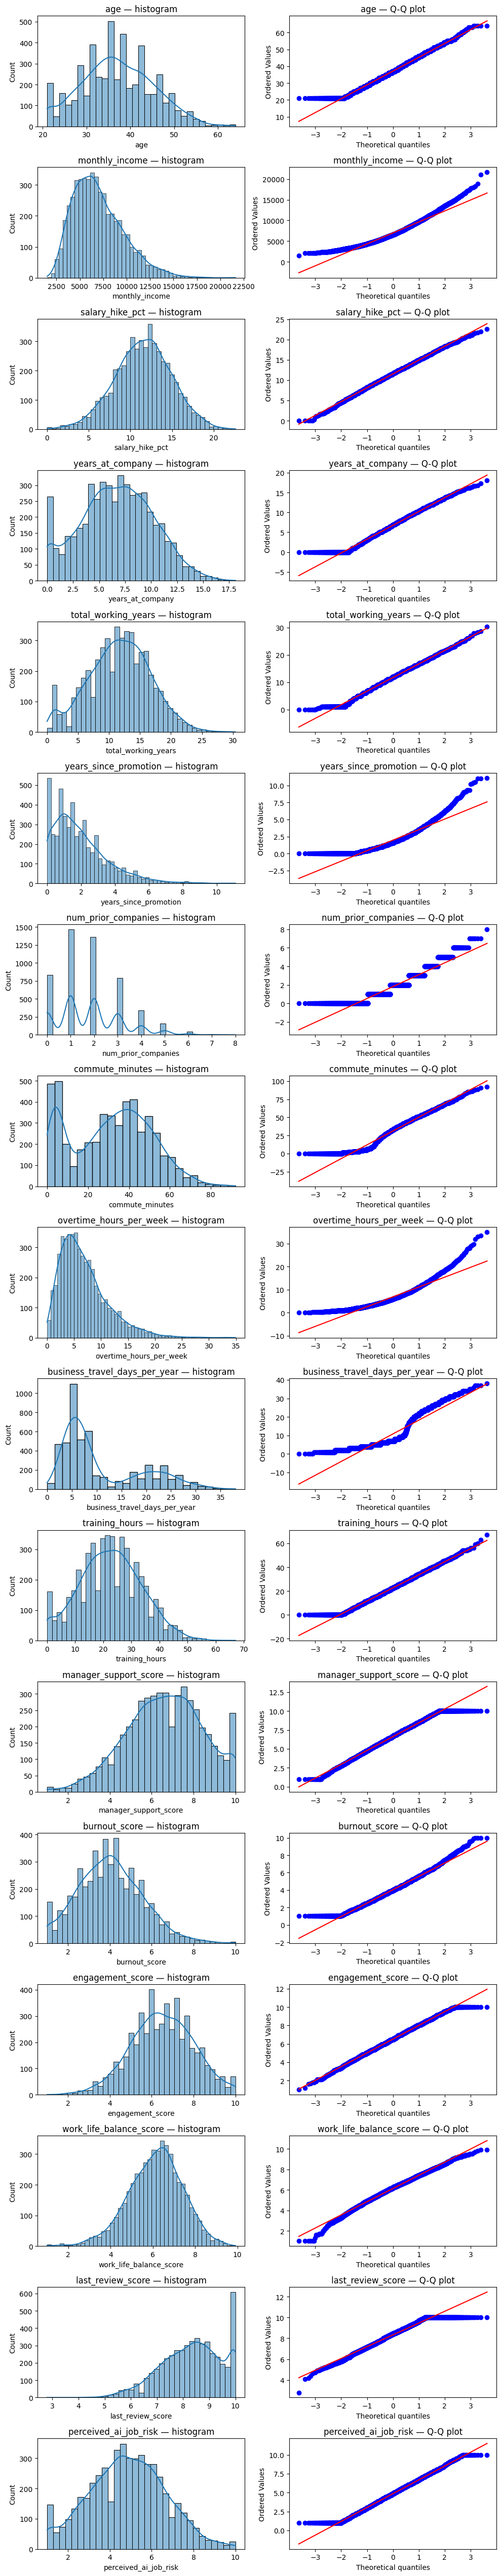

In [ ]:
n = len(cont_cols)
fig, axes = plt.subplots(n, 2, figsize=(10, 3 * n))

for i, col in enumerate(cont_cols):
    sns.histplot(hr[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} — histogram')
    stats.probplot(hr[col], dist='norm', plot=axes[i, 1])
    axes[i, 1].set_title(f'{col} — Q-Q plot')

plt.tight_layout()
plt.show()

**Normality check: findings**

All 17 continuous columns failed both normality tests (Shapiro-Wilk and D'Agostino-Pearson, p < 0.05). With 5,000 rows, these tests flag even very small departures from normality, so I also used skewness, kurtosis and Q-Q plots to judge how far each column departs in practice.

**Clearly right-skewed (skewness ≥ 0.7)**
- `years_since_promotion` (skew 1.35, kurtosis 2.52) and `overtime_hours_per_week` (1.31, 2.52): most employees cluster at low values, with a long tail of people with long promotion gaps or heavy overtime. These tails are relevant to attrition, so they are kept, not removed as outliers.
- `business_travel_days_per_year` (1.00): bounded at 0, and the gap between the median (7 days) and upper quartile (18 days) suggests two groups of travellers.
- `monthly_income` (0.83): typical salary pattern, with a few high earners pulling the mean above the median.
- `num_prior_companies` (0.72): a count variable with 9 possible values, so it was never expected to be normal.

**Mildly skewed (skewness 0.3–0.5)**
- `last_review_score` (−0.42), `burnout_score` (0.36), `work_life_balance_score` (−0.31).

**Approximately symmetric (|skewness| < 0.3)**
- `age`, `years_at_company`, `total_working_years`, `salary_hike_pct`, `training_hours`, `manager_support_score`, `engagement_score`, `perceived_ai_job_risk`, `commute_minutes`.
- `commute_minutes` is symmetric but flatter than normal (kurtosis −0.85), so values are spread evenly rather than clustered around the average.

**Implications for the analysis**
1. **Comparing leavers vs stayers:** use the Mann-Whitney U test for all continuous columns, and report medians alongside means. Using one non-parametric test throughout keeps the method consistent, since no column passed the normality tests.
2. **Correlations:** use Spearman rather than Pearson, as it does not assume normality and is less affected by the skewed tails.
3. **Modelling:** logistic regression does not require normally distributed predictors. `overtime_hours_per_week`, `years_since_promotion` and `monthly_income` will be tested with a `log1p` transform to reduce the influence of their long tails, and the transformed and untransformed versions compared.
4. **Ordinal columns** (`job_level`, `stock_option_level`, `performance_rating`) were excluded from this check and will be analysed as categories (chi-square tests).

# Analysis

## Analysis Objectives

**Business question:** What drives employees to leave, which groups are most at risk, and what would reducing attrition be worth?

This analysis uses a dataset of 5,000 employees (895 leavers, 17.9% attrition) to answer eight objectives:

1. **Attrition profile:** Which groups leave most (by department, job role, job level, work mode and performance), and are the differences statistically meaningful?
2. **Wellbeing drivers:** How much do burnout, engagement, manager support, work-life balance and overtime explain exits?
3. **Pay and career progression:** Do people leave because of pay or because of stalled careers (salary increases, promotion timing, stock options, pay relative to peers)?
4. **Work arrangements and AI:** Do work mode, commute and business travel affect attrition? Does perceived AI job risk raise the chance of leaving, and does that differ for employees who use AI tools?
5. **Attrition risk model:** Can a predictive model identify higher-risk employees and groups early enough for HR to act?
6. **Interpret the drivers:** Which factors matter most, and which can the company actually change (e.g. manager support, overtime, promotion timing) versus which it cannot (e.g. age, marital status)?
7. **Business impact:** What does attrition cost, and what would targeted interventions save?
8. **Fairness check:** Does the model work equally well across gender and age groups?

## Assumption

**Attrition measure and time period**
- The dataset has no dates, so attrition is measured as the share of employees flagged as leavers (895 of 5,000, 17.9%). This is treated as attrition over a single observation period, assumed to be 12 months. Annual or monthly turnover trends cannot be calculated.
- Each row is one unique employee (no duplicate IDs), and all findings compare employees at one point in time.

**Data preparation**
- The 59 employees whose tenure exceeds their total working years (impossible values) are excluded from any analysis that uses `years_at_company` or `total_working_years`, including the risk model (4,941 employees). Their values were not corrected, as there is no reliable way to know which figure is wrong.
- `num_prior_companies`, `total_working_years`, `job_role` and `job_level` are treated with caution because of inconsistencies found in the sanity checks, and are not used in the risk model. `job_level` is used as the measure of seniority where needed.
- Flagged rows are kept in the main analysis, and key results are re-run without them as robustness checks.

**Statistical approach**
- Results are considered statistically significant at p < 0.05.
- None of the continuous variables are normally distributed, so non-parametric tests are used (Mann-Whitney U for comparing leavers and stayers, Spearman for correlations). Chi-square tests are used for categorical variables.
- Effect sizes (Cramér's V, rank-biserial correlation, odds ratios) are reported alongside p-values, because with 5,000 employees even very small differences can be statistically significant.
- Odds ratios from logistic regression are reported per standard deviation (to compare factors) and per unit (to interpret in business terms).
- All relationships are associations, not proven causes, since the data is a single snapshot.

**Risk model**
- The final model is a logistic regression using wellbeing, pay and career, work arrangement, AI, department and performance factors.
- Personal characteristics (age, gender, marital status, education) are excluded from the model so that risk scores are not based on personal attributes; their effect on the model's fairness is checked separately (Objective 8).
- Employees are flagged as at risk when their predicted probability of leaving is 25% or higher. This threshold balances catching leavers with a manageable follow-up group and can be adjusted to HR capacity.
- Risk tiers use fixed probability cut-offs: Low (<10%), Moderate (10–25%), High (25–40%) and Very high (≥40%).
- The classification of factors as directly changeable, influenceable or not changeable (Objective 6) is a judgement-based framework.

**Cost estimates**
- Salaries are treated as AUD, as the dataset has no currency. Annual salary = monthly income × 12.
- Replacing a leaver is assumed to cost 50% of their annual salary (base case), with 30% (low) and 100% (high) scenarios tested. These are based on secondary, mostly US practitioner estimates.
- Intervention savings assume that changing a driver changes attrition risk by the amount the model predicts. A 50%-effect scenario is included as a more cautious estimate.

## Attrition profile - Which groups leave most, and are the differences statistically meaningful?

**Set up the target and helper function**

In [ ]:
hr['left'] = (hr['attrition'] == 'Yes').astype(int)
overall_rate = hr['left'].mean()
print(f"Overall attrition rate: {overall_rate:.1%} ({hr['left'].sum()} of {len(hr)} employees)")

def attrition_profile(df, col):
    """Attrition rate per group, with 95% CI, chi-square test and effect size."""
    # Rate per group
    g = df.groupby(col)['left'].agg(headcount='count', leavers='sum')
    g['attrition_rate'] = g['leavers'] / g['headcount']

    # 95% confidence interval (Wilson method, reliable for proportions)
    lo, hi = proportion_confint(g['leavers'], g['headcount'], alpha=0.05, method='wilson')
    g['ci_low'], g['ci_high'] = lo, hi
    g['vs_overall_pp'] = (g['attrition_rate'] - df['left'].mean()) * 100   # percentage points

    # Chi-square test of independence
    ct = pd.crosstab(df[col], df['left'])
    chi2_stat, p, dof, expected = chi2_contingency(ct)

    # Standardised residual: which groups drive the result (|value| > 2 = notably high/low)
    g['std_residual'] = ((ct[1] - expected[:, 1]) / np.sqrt(expected[:, 1])).values

    # Cramér's V: effect size (0.1 small, 0.3 medium, 0.5 large)
    n, k = ct.values.sum(), min(ct.shape) - 1
    cramers_v = np.sqrt(chi2_stat / (n * k))

    test = {'variable': col, 'chi2': round(chi2_stat, 2), 'dof': dof, 'p_value': p,
            'cramers_v': round(cramers_v, 3),
            'min_expected': round(expected.min(), 1),   # should be ≥ 5 for a valid test
            'significant': 'Yes' if p < 0.05 else 'No'}
    return g, test

Overall attrition rate: 17.9% (895 of 5000 employees)


**Run the tests & generate results table for each profile variable**

In [ ]:
profile_vars = ['department', 'job_role', 'job_level', 'work_mode', 'performance_rating']
ordinal_vars = ['job_level', 'performance_rating']   # keep natural order, not sorted by rate

profiles, tests = {}, []
for col in profile_vars:
    g, t = attrition_profile(hr, col)
    profiles[col] = g if col in ordinal_vars else g.sort_values('attrition_rate', ascending=False)
    tests.append(t)

chi_summary = pd.DataFrame(tests).sort_values('cramers_v', ascending=False)
display(chi_summary)

,variable,chi2,dof,p_value,cramers_v,min_expected,significant
4,performance_rating,97.77,3,4.690476e-21,0.140,28.1,Yes
1,job_role,56.24,24,2.127670e-04,0.106,12.4,Yes
0,department,32.36,7,3.487088e-05,0.080,43.7,Yes
3,work_mode,21.74,2,1.902931e-05,0.066,182.8,Yes
2,job_level,10.50,4,3.277204e-02,0.046,107.6,Yes


Based on the result it seems that attrition differs significantly across different groups in all the profile variables.

This means that attrition is associated with employe profiles such as performance rating, job role, department, work mode and job level. Although the association is statistically significant, the cramers value indicates that the association is weak, so on its own these variables explain only a small part of attrition.

The association is also ranked from the strongest, with performance rating being the profile variable which has the strongest link to attrition, while job level is the weakest.

In [ ]:
'''the table calculates Headcount (no. of employee),
leavers (no. of employee leaving) and attrition rate (leavers/headcount) per group.

It calculates the confidence interval (lower and higher limit) which shows
the range the 'true' rate probably falls in.

In addition, table has vs_overall_pp which is the gap between the
overall attrition rate (17.9%) and that group's attrition rate

standardized residual is also calculated indicating the variation in attrition
'''
for col in profile_vars:
    print(f"\n=== Attrition by {col} ===")
    display(profiles[col].style.format({
        'attrition_rate': '{:.1%}', 'ci_low': '{:.1%}', 'ci_high': '{:.1%}',
        'vs_overall_pp': '{:+.1f}', 'std_residual': '{:+.2f}'
    }))


=== Attrition by department ===


,headcount,leavers,attrition_rate,ci_low,ci_high,vs_overall_pp,std_residual
department,,,,,,,
Customer Support,636,153,24.1%,20.9%,27.5%,+6.2,+3.67
Sales,835,167,20.0%,17.4%,22.8%,+2.1,+1.43
Marketing,440,83,18.9%,15.5%,22.8%,+1.0,+0.48
Finance,436,79,18.1%,14.8%,22.0%,+0.2,+0.11
Human Resources,244,44,18.0%,13.7%,23.3%,+0.1,+0.05
Operations,663,114,17.2%,14.5%,20.3%,-0.7,-0.43
Research & Development,410,61,14.9%,11.8%,18.6%,-3.0,-1.45
Engineering,1336,194,14.5%,12.7%,16.5%,-3.4,-2.92



=== Attrition by job_role ===


,headcount,leavers,attrition_rate,ci_low,ci_high,vs_overall_pp,std_residual
job_role,,,,,,,
Support Team Lead,204,53,26.0%,20.4%,32.4%,+8.1,+2.73
Support Specialist,218,55,25.2%,19.9%,31.4%,+7.3,+2.56
Content Strategist,138,33,23.9%,17.6%,31.7%,+6.0,+1.67
Account Executive,277,66,23.8%,19.2%,29.2%,+5.9,+2.33
Recruiter,69,16,23.2%,14.8%,34.4%,+5.3,+1.04
Customer Success Manager,214,45,21.0%,16.1%,27.0%,+3.1,+1.08
Finance Manager,139,29,20.9%,14.9%,28.4%,+3.0,+0.83
Sales Development Rep,259,52,20.1%,15.7%,25.4%,+2.2,+0.83
Growth Manager,156,31,19.9%,14.4%,26.8%,+2.0,+0.58



=== Attrition by job_level ===


,headcount,leavers,attrition_rate,ci_low,ci_high,vs_overall_pp,std_residual
job_level,,,,,,,
1,601,125,20.8%,17.7%,24.2%,+2.9,+1.68
2,1378,268,19.4%,17.4%,21.6%,+1.5,+1.36
3,1444,239,16.6%,14.7%,18.6%,-1.3,-1.21
4,948,167,17.6%,15.3%,20.2%,-0.3,-0.21
5,629,96,15.3%,12.7%,18.3%,-2.6,-1.56



=== Attrition by work_mode ===


,headcount,leavers,attrition_rate,ci_low,ci_high,vs_overall_pp,std_residual
work_mode,,,,,,,
Onsite,1742,369,21.2%,19.3%,23.2%,+3.3,+3.24
Hybrid,2237,376,16.8%,15.3%,18.4%,-1.1,-1.22
Remote,1021,150,14.7%,12.7%,17.0%,-3.2,-2.42



=== Attrition by performance_rating ===


,headcount,leavers,attrition_rate,ci_low,ci_high,vs_overall_pp,std_residual
performance_rating,,,,,,,
2,157,45,28.7%,22.2%,36.2%,+10.8,+3.19
3,1952,456,23.4%,21.5%,25.3%,+5.5,+5.70
4,2546,368,14.5%,13.1%,15.9%,-3.4,-4.11
5,345,26,7.5%,5.2%,10.8%,-10.4,-4.55


**Create the chart**

*Red bars are significantly above the overall rate, blue significantly below, and grey not different (the confidence interval crosses the dashed line)*

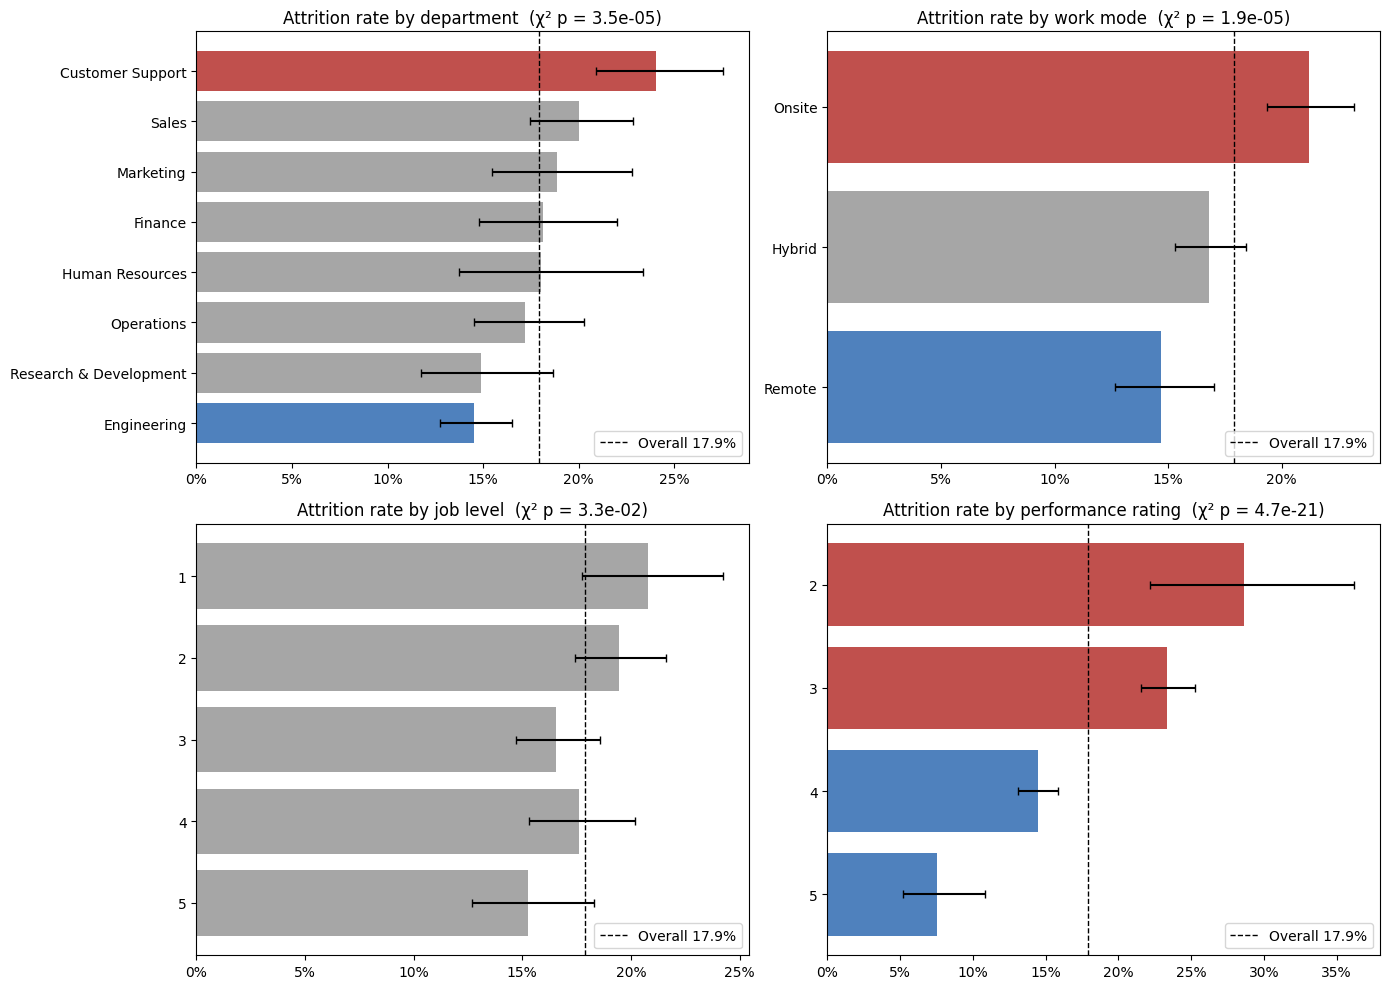

In [ ]:
plot_vars = ['department', 'work_mode', 'job_level', 'performance_rating']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, plot_vars):
    d = profiles[col] if col in ordinal_vars else profiles[col].sort_values('attrition_rate')
    labels = d.index.astype(str)
    err = [d['attrition_rate'] - d['ci_low'], d['ci_high'] - d['attrition_rate']]
    colors = ['#C0504D' if lo > overall_rate else '#4F81BD' if hi < overall_rate else '#A6A6A6'
              for lo, hi in zip(d['ci_low'], d['ci_high'])]

    ax.barh(labels, d['attrition_rate'], xerr=err, color=colors, capsize=3)
    ax.axvline(overall_rate, color='black', linestyle='--', linewidth=1,
               label=f'Overall {overall_rate:.1%}')
    p = chi_summary.set_index('variable').loc[col, 'p_value']
    ax.set_title(f"Attrition rate by {col.replace('_', ' ')}  (χ² p = {p:.1e})")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    if col in ordinal_vars:
        ax.invert_yaxis()   # level 1 / rating 2 at the top
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

Based on the chart above, we can see that:

- Customer Support Department, Employees working onsite, and employees with <= 3 performance rating has the highest attrition rate (significantly higher than the average)
- Engineering Department, Remote workers and employees with high performance rating has low attrition rate (significantly lower than the average)


**Is job role just a department effect?**

*Roles belong to departments (ex: Support Specialists are all in Customer Support), so a role can look risky only because of its department. This cell compares roles within each department.*

In [ ]:
role_within_dept = []
for dept, sub in hr.groupby('department'):
    ct = pd.crosstab(sub['job_role'], sub['left'])
    chi2_stat, p, dof, _ = chi2_contingency(ct)
    rates = sub.groupby('job_role')['left'].mean()
    role_within_dept.append({'department': dept, 'p_value': round(p, 3),
                             'highest_role': rates.idxmax(), 'highest_rate': rates.max(),
                             'lowest_role': rates.idxmin(), 'lowest_rate': rates.min()})

display(pd.DataFrame(role_within_dept).style.format({'highest_rate': '{:.1%}', 'lowest_rate': '{:.1%}'}))

,department,p_value,highest_role,highest_rate,lowest_role,lowest_rate
0,Customer Support,0.438000,Support Team Lead,26.0%,Customer Success Manager,21.0%
1,Engineering,0.471000,QA Engineer,16.2%,Software Engineer,12.3%
2,Finance,0.296000,Finance Manager,20.9%,Accountant,14.3%
3,Human Resources,0.392000,Recruiter,23.2%,HR Business Partner,14.8%
4,Marketing,0.059000,Content Strategist,23.9%,Marketing Specialist,13.0%
5,Operations,0.879000,Operations Manager,18.2%,Operations Analyst,16.4%
6,Research & Development,0.112000,Research Scientist,19.0%,R&D Manager,10.0%
7,Sales,0.083000,Account Executive,23.8%,Sales Manager,16.4%


**Findings:** inside every department, the roles don’t differ significantly (all p > 0.05). So “Support Team Leads leave most” is really “Customer Support leaves most”.

**Robustness check (comparing dataset with flagged rows vs without)**

In [ ]:
clean = hr[~hr['flag_any_issue']]
robust = []
for col in profile_vars:
    _, t_all = attrition_profile(hr, col)
    _, t_clean = attrition_profile(clean, col)
    robust.append({'variable': col,
                   'p_all': t_all['p_value'], 'cramers_v_all': t_all['cramers_v'],
                   'p_clean': t_clean['p_value'], 'cramers_v_clean': t_clean['cramers_v'],
                   'still_significant': 'Yes' if t_clean['p_value'] < 0.05 else 'No'})

print(f"Clean subset: {len(clean)} employees ({len(hr) - len(clean)} flagged rows removed)")
display(pd.DataFrame(robust))

Clean subset: 3642 employees (1358 flagged rows removed)


,variable,p_all,cramers_v_all,p_clean,cramers_v_clean,still_significant
0,department,3.487088e-05,0.080,3.567691e-03,0.076,Yes
1,job_role,2.127670e-04,0.106,1.259177e-02,0.108,Yes
2,job_level,3.277204e-02,0.046,1.139241e-01,0.045,No
3,work_mode,1.902931e-05,0.066,3.000151e-03,0.056,Yes
4,performance_rating,4.690476e-21,0.140,1.483559e-15,0.141,Yes


**Finding:**
performance, department, work mode and role all stay significant. Job level doesn’t (p goes from 0.033 to 0.11), so it isn’t a reliable finding, which fits the role/level problems found earlier.

To conclude, performance, department and work mode are genuinely linked to attrition, job role only matters through department, job level has no reliable effect, and every effect is small on its own, which is why the modelling step later combines them.

**Conclusion - Objective 1:**


- **Performance has the strongest link:** Attrition drops steadily from 28.7% (rating 2) to 7.5% (rating 5). Rating 3, the second-largest group at 1,952 people, sits at 23.4%. That’s the group to watch: solid performers leaving at above-average rates.
- **Department:** only two departments differ significantly from average: Customer Support is high (24.1%) and Engineering is low (14.5%). The other six are within normal variation.
- **Work mode:** onsite staff leave more (21.2%) than hybrid (16.8%) and remote (14.7%).
- **Job role is mostly a department effect:** analysis above shows that within every department, roles don’t differ significantly from each other (all p > 0.05). Support roles look high-risk because they’re in Customer Support department, not because of the role itself.
- **Job level is weak and unreliable:** The trend (20.8% at level 1 down to 15.3% at level 5) is barely significant and disappears without flagged rows. Given the role/level mismatch found earlier, report it as “no reliable evidence that seniority affects attrition”.
- **All effect sizes are small (V below 0.15):** Each factor on its own explains little, which is normal for attrition and is why these factors will be combined during the modelling step.

## Wellbeing drivers - How much do burnout, engagement, manager support, work-life balance and overtime explain exits?

**Initial Setup**

In [ ]:
# Note: Burnout and overtime are “bad when high”; while
# engagement, manager support and work-life balance are “good when high”.

wellbeing = ['burnout_score', 'engagement_score', 'manager_support_score',
             'work_life_balance_score', 'overtime_hours_per_week']

labels = {'burnout_score': 'Burnout', 'engagement_score': 'Engagement',
          'manager_support_score': 'Manager support', 'work_life_balance_score': 'Work-life balance',
          'overtime_hours_per_week': 'Overtime (hrs/week)'}

# Make sure the 0/1 target from B1 exists
hr['left'] = (hr['attrition'] == 'Yes').astype(int)

**Do leavers and stayers differ?**

In [ ]:
leavers = hr[hr['left'] == 1]
stayers = hr[hr['left'] == 0]

rows = []
for col in wellbeing:
    u, p = mannwhitneyu(leavers[col], stayers[col], alternative='two-sided')
    rank_biserial = 2 * u / (len(leavers) * len(stayers)) - 1   # effect size, −1 to +1
    rows.append({
        'variable': labels[col],
        'median_leavers': leavers[col].median(),
        'median_stayers': stayers[col].median(),
        'mean_leavers': round(leavers[col].mean(), 2),
        'mean_stayers': round(stayers[col].mean(), 2),
        'p_value': p,
        'rank_biserial': round(rank_biserial, 3),
    })

mw_results = pd.DataFrame(rows).sort_values('rank_biserial', key=abs, ascending=False)
display(mw_results)

,variable,median_leavers,median_stayers,mean_leavers,mean_stayers,p_value,rank_biserial
0,Burnout,5.0,3.8,5.06,3.81,7.448356e-99,0.449
1,Engagement,5.6,6.7,5.54,6.72,2.005837e-94,-0.439
2,Manager support,5.7,6.9,5.69,6.81,1.790174e-59,-0.346
3,Work-life balance,5.6,6.3,5.57,6.25,5.070179e-40,-0.282
4,Overtime (hrs/week),7.9,5.5,8.77,6.40,2.369410e-38,0.276


**Finding:**

Leavers report much worse wellbeing on all five measures

The tests show leavers differ significantly from stayers on every wellbeing measure (all p < 0.001). The differences are substantial: leavers have higher burnout (median 5.0 vs 3.8) and lower engagement (5.6 vs 6.7), followed by lower manager support (5.7 vs 6.9), lower work-life balance (5.6 vs 6.3) and more overtime (7.9 vs 5.5 hours per week).


The effect size (magnitude of difference) are also considerably larger than the effect of profile factors like department and performance rating, making wellbeing the strongest attrition signal analysed so far.

**How does attrition rise across score levels?**

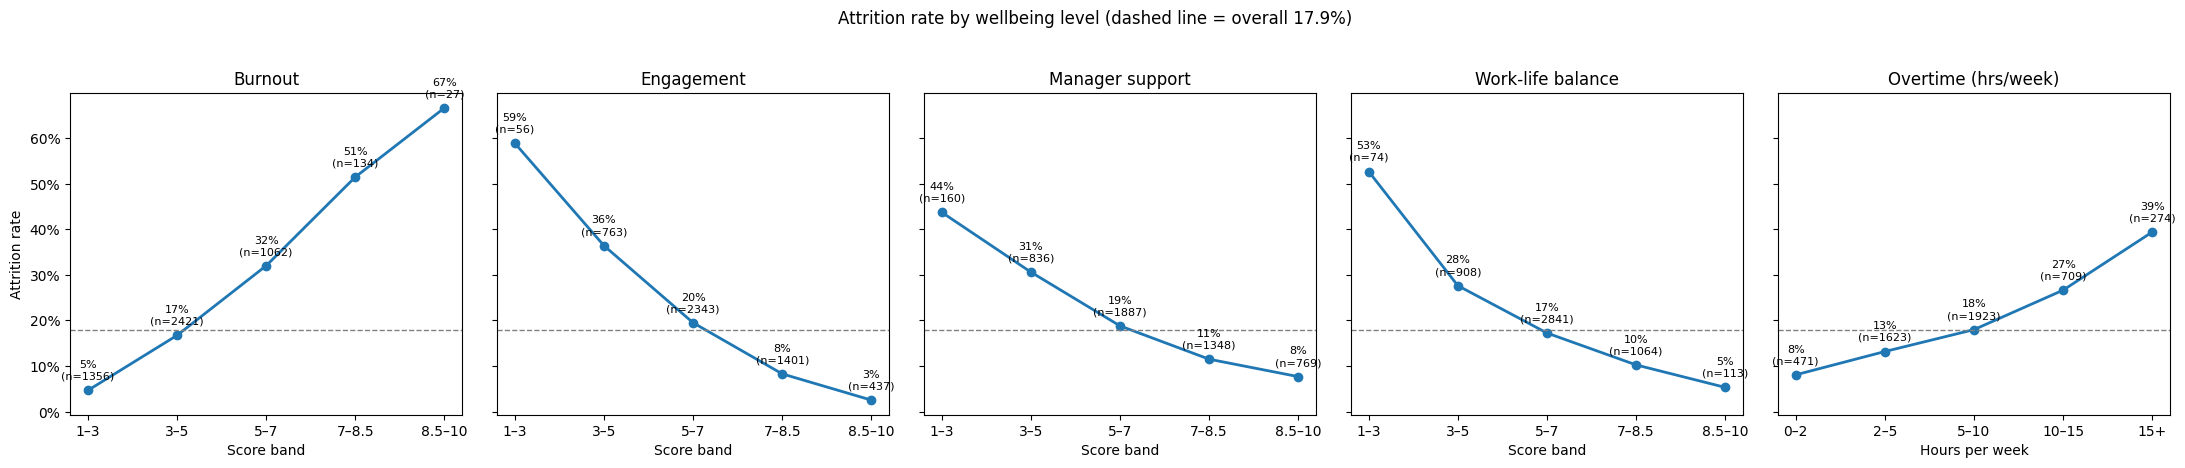


Burnout


,headcount,attrition_rate
burnout_score,,
1–3,1356,4.6%
3–5,2421,16.7%
5–7,1062,32.0%
7–8.5,134,51.5%
8.5–10,27,66.7%



Engagement


,headcount,attrition_rate
engagement_score,,
1–3,56,58.9%
3–5,763,36.4%
5–7,2343,19.5%
7–8.5,1401,8.3%
8.5–10,437,2.5%



Manager support


,headcount,attrition_rate
manager_support_score,,
1–3,160,43.8%
3–5,836,30.6%
5–7,1887,18.8%
7–8.5,1348,11.5%
8.5–10,769,7.7%



Work-life balance


,headcount,attrition_rate
work_life_balance_score,,
1–3,74,52.7%
3–5,908,27.6%
5–7,2841,17.2%
7–8.5,1064,10.2%
8.5–10,113,5.3%



Overtime (hrs/week)


,headcount,attrition_rate
overtime_hours_per_week,,
0–2,471,8.1%
2–5,1623,13.2%
5–10,1923,18.0%
10–15,709,26.7%
15+,274,39.4%


In [ ]:
score_bins = [0, 3, 5, 7, 8.5, 10]
score_labels = ['1–3', '3–5', '5–7', '7–8.5', '8.5–10']
ot_bins = [-0.1, 2, 5, 10, 15, 40]
ot_labels = ['0–2', '2–5', '5–10', '10–15', '15+']

band_tables = {}
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)

for ax, col in zip(axes, wellbeing):
    if col == 'overtime_hours_per_week':
        bands = pd.cut(hr[col], bins=ot_bins, labels=ot_labels)
    else:
        bands = pd.cut(hr[col], bins=score_bins, labels=score_labels)

    t = hr.groupby(bands, observed=True)['left'].agg(headcount='count', attrition_rate='mean')
    band_tables[col] = t

    ax.plot(t.index.astype(str), t['attrition_rate'], marker='o', linewidth=2)
    for x, (rate, n) in enumerate(zip(t['attrition_rate'], t['headcount'])):
        ax.annotate(f'{rate:.0%}\n(n={n})', (x, rate), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=8)
    ax.axhline(hr['left'].mean(), color='grey', linestyle='--', linewidth=1)
    ax.set_title(labels[col])
    ax.set_xlabel('Hours per week' if col == 'overtime_hours_per_week' else 'Score band')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

axes[0].set_ylabel('Attrition rate')
plt.suptitle('Attrition rate by wellbeing level (dashed line = overall 17.9%)', y=1.03)
plt.tight_layout()
plt.show()

for col, t in band_tables.items():
    print(f'\n{labels[col]}')
    display(t.style.format({'attrition_rate': '{:.1%}'}))

**Finding:**

Attrition rises steadily as wellbeing worsens.

Every measure shows a consistent dose-response pattern. Employees with low burnout (score 1–3) leave at 4.6%, about a quarter of the company rate, while those scoring 7+ leave more than half the time. Highly engaged employees (8.5–10) leave at 2.5%, compared with 36.4% for those scoring 3–5. Attrition also rises from 7.7% to 43.8% as manager support falls from the top to the bottom band, and from 8.1% to 39.4% as overtime increases from under 2 to over 15 hours per week.

Because the pattern is gradual rather than limited to extreme scores, improvements at any level are likely to reduce attrition, not just for the most at-risk employees.

**How related are the five factors to each other?**

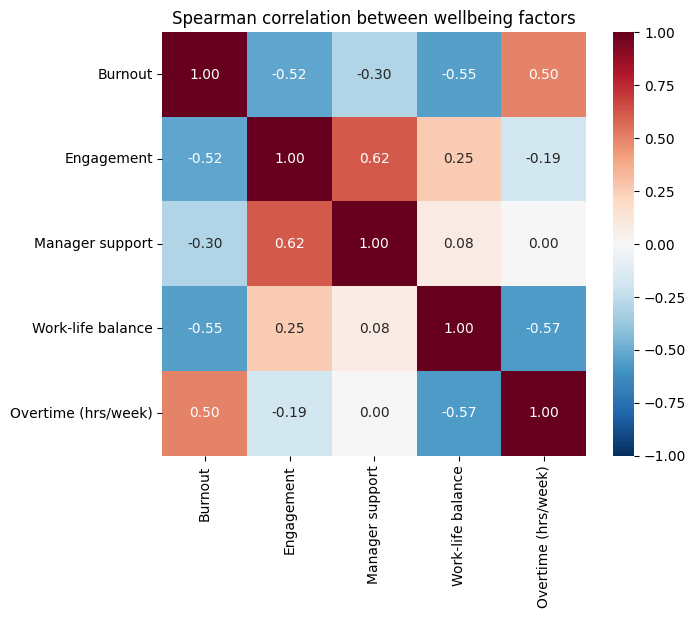

,variable,VIF
0,Burnout,2.28
1,Engagement,2.16
2,Manager support,1.72
3,Work-life balance,1.90
4,Overtime (hrs/week),1.89


In [ ]:
# Spearman correlation (rank-based, suitable for non-normal data)
corr = hr[wellbeing].corr(method='spearman').rename(index=labels, columns=labels)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Spearman correlation between wellbeing factors')
plt.show()

# Variance Inflation Factor (VIF): how much each factor overlaps with all the others
X_vif = sm.add_constant(hr[wellbeing])
vif = pd.DataFrame({
    'variable': [labels[c] for c in wellbeing],
    'VIF': [round(variance_inflation_factor(X_vif.values, i + 1), 2) for i in range(len(wellbeing))]
})
display(vif)

**Finding:**

The wellbeing factors are related but measure different things.

- Burnout is moderately correlated with overtime (corr = 0.50), engagement (corr = −0.52) and work-life balance (corr = −0.55).

- Overtime is correlated with work-life balance (corr= −0.57).
- Manager support is the most independent factor (corr = 0.00 with overtime).
- All Variance Inflation Factors are between 1.7 and 2.3, well below the threshold of 5, so the factors can be analysed together in one model without multicollinearity problems.

**How much do the factors explain together?**

In [ ]:
# Standardise so odds ratios are comparable: "effect of a 1 standard-deviation increase"
Z = (hr[wellbeing] - hr[wellbeing].mean()) / hr[wellbeing].std()
X = sm.add_constant(Z)
y = hr['left']

logit_model = sm.Logit(y, X).fit(disp=0)

or_table = pd.DataFrame({
    'odds_ratio': np.exp(logit_model.params),
    'ci_low': np.exp(logit_model.conf_int()[0]),
    'ci_high': np.exp(logit_model.conf_int()[1]),
    'p_value': logit_model.pvalues,
}).drop('const')
or_table.index = [labels[c] for c in or_table.index]
or_table['effect'] = np.where(or_table['odds_ratio'] > 1, 'raises exit risk', 'lowers exit risk')
or_table['pct_change_in_odds'] = ((or_table['odds_ratio'] - 1) * 100).round(1)
display(or_table.round(3))

auc_all = roc_auc_score(y, logit_model.predict(X))
print(f"McFadden pseudo R²: {logit_model.prsquared:.3f}")
print(f"Likelihood-ratio test p-value: {logit_model.llr_pvalue:.1e}")
print(f"AUC (all five factors): {auc_all:.3f}")

# Each factor on its own, for comparison
single = []
for col in wellbeing:
    m = sm.Logit(y, sm.add_constant(Z[[col]])).fit(disp=0)
    single.append({'variable': labels[col],
                   'odds_ratio_alone': round(np.exp(m.params[col]), 3),
                   'pseudo_R2_alone': round(m.prsquared, 3),
                   'AUC_alone': round(roc_auc_score(y, m.predict(sm.add_constant(Z[[col]]))), 3)})
display(pd.DataFrame(single).sort_values('pseudo_R2_alone', ascending=False))

,odds_ratio,ci_low,ci_high,p_value,effect,pct_change_in_odds
Burnout,1.546,1.374,1.739,0.000,raises exit risk,54.6
Engagement,0.665,0.592,0.747,0.000,lowers exit risk,-33.5
Manager support,0.746,0.673,0.826,0.000,lowers exit risk,-25.4
Work-life balance,0.934,0.839,1.040,0.213,lowers exit risk,-6.6
Overtime (hrs/week),1.176,1.063,1.301,0.002,raises exit risk,17.6


McFadden pseudo R²: 0.143
Likelihood-ratio test p-value: 5.5e-143
AUC (all five factors): 0.763


,variable,odds_ratio_alone,pseudo_R2_alone,AUC_alone
0,Burnout,2.322,0.103,0.725
1,Engagement,0.424,0.101,0.720
2,Manager support,0.535,0.059,0.673
3,Work-life balance,0.592,0.043,0.641
4,Overtime (hrs/week),1.599,0.040,0.638


**Finding:**

Burnout, engagement and manager support are the independent drivers.

A logistic regression including all five standardised factors shows that, holding the others constant:
- **Burnout** has the largest effect: each one-standard-deviation increase (about 1.5 points) raises the odds of leaving by 55% (OR 1.55, 95% CI 1.37–1.74).
- **Engagement** is the strongest protective factor: each SD increase lowers the odds by 33% (OR 0.67, 0.59–0.75).
- **Manager support** lowers the odds by 25% per SD (OR 0.75, 0.67–0.83).
- **Overtime** has a smaller independent effect (OR 1.18, 1.06–1.30).
- **Work-life balance** has no independent effect (OR 0.93, p = 0.21). It is strongly linked to attrition on its own (OR 0.59), but this is already captured by burnout and overtime.

Together the five factors give a McFadden pseudo R² of 0.143 and an AUC of 0.763: a meaningful but partial explanation. Burnout alone (AUC 0.725) or engagement alone (AUC 0.720) achieves most of this predictive power.

**Does overtime lead to exits through burnout?**

In [ ]:
z = lambda s: (s - s.mean()) / s.std()
hr['ot_z'] = z(hr['overtime_hours_per_week'])
hr['burnout_z'] = z(hr['burnout_score'])

# Path a: overtime → burnout (linear regression)
path_a = sm.OLS(hr['burnout_z'], sm.add_constant(hr[['ot_z']])).fit()
# Total effect: overtime → leaving
total = sm.Logit(hr['left'], sm.add_constant(hr[['ot_z']])).fit(disp=0)
# Direct effect: overtime → leaving, holding burnout constant (also gives path b)
direct = sm.Logit(hr['left'], sm.add_constant(hr[['ot_z', 'burnout_z']])).fit(disp=0)

a = path_a.params['ot_z']
b = direct.params['burnout_z']
print(f"Path a  (overtime → burnout):        β = {a:.3f}, p = {path_a.pvalues['ot_z']:.1e}")
print(f"Total   (overtime → leaving):        OR = {np.exp(total.params['ot_z']):.3f}, p = {total.pvalues['ot_z']:.1e}")
print(f"Direct  (overtime → leaving | burnout): OR = {np.exp(direct.params['ot_z']):.3f}, p = {direct.pvalues['ot_z']:.2f}")
print(f"Path b  (burnout → leaving | overtime): OR = {np.exp(b):.3f}")
print(f"Share of overtime's effect removed once burnout is included: "
      f"{1 - direct.params['ot_z'] / total.params['ot_z']:.0%}")

# Bootstrap confidence interval for the indirect effect (a × b)
rng = np.random.default_rng(42)
indirect = []
for _ in range(500):
    s = hr.sample(len(hr), replace=True, random_state=rng.integers(1e9))
    a_s = sm.OLS(s['burnout_z'], sm.add_constant(s[['ot_z']])).fit().params['ot_z']
    b_s = sm.Logit(s['left'], sm.add_constant(s[['ot_z', 'burnout_z']])).fit(disp=0).params['burnout_z']
    indirect.append(a_s * b_s)
lo, hi = np.percentile(indirect, [2.5, 97.5])
print(f"Indirect effect a×b = {a * b:.3f}, 95% bootstrap CI [{lo:.3f}, {hi:.3f}]")

# Attrition by overtime × burnout, to see the pattern directly
hr['ot_band'] = pd.cut(hr['overtime_hours_per_week'], [-0.1, 5, 10, 40], labels=['≤5 h', '5–10 h', '>10 h'])
hr['burnout_band'] = pd.cut(hr['burnout_score'], [0, 3, 5, 10], labels=['Low (≤3)', 'Medium (3–5)', 'High (>5)'])
grid = pd.crosstab(hr['ot_band'], hr['burnout_band'], values=hr['left'], aggfunc='mean')
counts = pd.crosstab(hr['ot_band'], hr['burnout_band'])
display(grid.style.format('{:.1%}').background_gradient(cmap='Reds', axis=None))
display(counts)

Path a  (overtime → burnout):        β = 0.561, p = 0.0e+00
Total   (overtime → leaving):        OR = 1.599, p = 1.3e-42
Direct  (overtime → leaving | burnout): OR = 1.045, p = 0.30
Path b  (burnout → leaving | overtime): OR = 2.257
Share of overtime's effect removed once burnout is included: 91%
Indirect effect a×b = 0.456, 95% bootstrap CI [0.405, 0.515]


burnout_band,Low (≤3),Medium (3–5),High (>5)
ot_band,,,
≤5 h,4.2%,15.5%,29.7%
5–10 h,5.5%,16.9%,32.1%
>10 h,6.1%,19.7%,39.0%


burnout_band,Low (≤3),Medium (3–5),High (>5)
ot_band,,,
≤5 h,889,1003,202
5–10 h,418,1053,452
>10 h,49,365,569


**Finding:**

Overtime affects attrition mainly through burnout.

A mediation analysis tested whether overtime leads to exits by increasing burnout. Overtime strongly predicts burnout (β = 0.56), and on its own raises the odds of leaving by 60% per SD (OR 1.60, p < 0.001). Once burnout is included, overtime's effect falls to OR 1.05 and is no longer significant (p = 0.30): about 91% of its effect runs through burnout. The bootstrapped indirect effect is significant (0.46, 95% CI 0.40–0.52).

The overtime × burnout breakdown confirms this: employees with low burnout leave at 4–6% regardless of overtime, while high-burnout employees leave at 30–39%. Overtime appears to be harmful when it leads to burnout, rather than in itself.

**Robustness check (comparing dataset with flagged rows vs without)**

In [ ]:
clean = hr[~hr['flag_any_issue']]
Zc = (clean[wellbeing] - clean[wellbeing].mean()) / clean[wellbeing].std()
m_clean = sm.Logit(clean['left'], sm.add_constant(Zc)).fit(disp=0)

robust = pd.DataFrame({
    'OR_all': np.exp(logit_model.params),
    'p_all': logit_model.pvalues,
    'OR_clean': np.exp(m_clean.params),
    'p_clean': m_clean.pvalues,
}).drop('const')
robust.index = [labels[c] for c in robust.index]
display(robust.round(4))
print(f"AUC on clean subset: {roc_auc_score(clean['left'], m_clean.predict(sm.add_constant(Zc))):.3f} "
      f"({len(clean)} employees)")

,OR_all,p_all,OR_clean,p_clean
Burnout,1.5457,0.0000,1.5859,0.0000
Engagement,0.6651,0.0000,0.6851,0.0000
Manager support,0.7457,0.0000,0.7464,0.0000
Work-life balance,0.9340,0.2134,0.9383,0.3226
Overtime (hrs/week),1.1761,0.0016,1.1824,0.0055


AUC on clean subset: 0.760 (3642 employees)


The results are almost identical. Burnout OR 1.59, engagement 0.69, manager support 0.75, overtime 1.18 (all significant) except for work-life balance (p = 0.32); AUC 0.760 which is approximately the same as flagged-rows-included dataset.

**Conclusion - Objective 1:**

Wellbeing is the strongest attrition signal in the dataset. Together, burnout, engagement, manager support, work-life balance and overtime explain a meaningful share of exits (pseudo R² 0.143, AUC 0.763), and their effects are much larger than those of employee profile factors (e.g. department, work mode or job level).

Three factors drive attrition independently: **burnout** (raises risk), and **engagement** and **manager support** (lower risk). Overtime matters mainly because it increases burnout, and work-life balance adds no information beyond burnout and overtime.

**Business implications**
1. **Monitor burnout and engagement as early-warning indicators.** These two scores alone identify at-risk employees almost as well as all five combined.
2. **Manage workload by its effect on burnout, not hours alone.** Employees with high overtime but low burnout rarely leave; reducing overtime is most valuable where burnout is already rising.
3. **Invest in manager support.** It reduces exit risk independently of workload and is the factor least related to the others, so it offers a separate lever, such as manager training or regular check-ins.

**Limitations**
- The data is a single snapshot, so these are associations, not proven causes. The mediation result is consistent with "overtime → burnout → exit" but cannot prove that order.
- The wellbeing scores are self-reported, and people planning to leave may rate their experience more negatively.
- Onsite staff (burnout 4.41) and Customer Support and Sales (4.37–4.39) report higher burnout than average (4.03), which may explain part of the employee profile group differences. This will be tested in the full model.

## Pay and career progression - Do people leave because of pay or stalled careers?

*Pay is compared within job level. Since job_level (not job_role) is chosen as the measure of seniority instead of the role themselves, a “fair pay” measure (compa-ratio) is built against each level’s median salary.*

*In this part of analysis, 59 rows are excluded (the one where years_at_company > total_working_years).*



**Initial setup - create comparative ratio**

In [ ]:
# Pay relative to peers: income ÷ median income for the same job level
hr['compa_ratio'] = hr['monthly_income'] / hr.groupby('job_level')['monthly_income'].transform('median')

pay_career = ['monthly_income', 'compa_ratio', 'salary_hike_pct',
              'stock_option_level', 'years_since_promotion', 'training_hours']

labels_pc = {'monthly_income': 'Monthly income', 'compa_ratio': 'Compa-ratio (pay vs level median)',
             'salary_hike_pct': 'Salary increase %', 'stock_option_level': 'Stock option level',
             'years_since_promotion': 'Years since promotion', 'training_hours': 'Training hours'}

hr['left'] = (hr['attrition'] == 'Yes').astype(int)
display(hr['compa_ratio'].describe().round(2))

,compa_ratio
count,5000.00
mean,1.03
std,0.24
min,0.40
25%,0.85
50%,1.00
75%,1.18
max,2.06


**Do leavers and stayers differ?**

In [ ]:
leavers, stayers = hr[hr['left'] == 1], hr[hr['left'] == 0]

rows = []
for col in pay_career:
    u, p = mannwhitneyu(leavers[col], stayers[col], alternative='two-sided')
    rows.append({'variable': labels_pc[col],
                 'median_leavers': round(leavers[col].median(), 2),
                 'median_stayers': round(stayers[col].median(), 2),
                 'p_value': p,
                 'rank_biserial': round(2 * u / (len(leavers) * len(stayers)) - 1, 3)})
pc_results = pd.DataFrame(rows).sort_values('rank_biserial', key=abs, ascending=False)
display(pc_results)

# Stock option level only has 4 values (0–3), so treat it as a category: chi-square test
ct = pd.crosstab(hr['stock_option_level'], hr['left'])
chi2_stat, p_stock, dof, _ = chi2_contingency(ct)
print(f"\nStock options: χ²({dof}) = {chi2_stat:.2f}, p = {p_stock:.3f}")
display(hr.groupby('stock_option_level')['left'].agg(headcount='count', attrition_rate='mean')
          .style.format({'attrition_rate': '{:.1%}'}))

,variable,median_leavers,median_stayers,p_value,rank_biserial
2,Salary increase %,10.50,11.8,9.187184e-23,-0.209
4,Years since promotion,2.00,1.5,7.216325e-14,0.159
0,Monthly income,6262.00,6617.0,2.386221e-05,-0.090
1,Compa-ratio (pay vs level median),0.98,1.0,1.580070e-03,-0.067
3,Stock option level,1.00,1.0,5.009115e-02,-0.040
5,Training hours,23.00,22.0,3.678610e-01,0.019



Stock options: χ²(3) = 5.66, p = 0.129


,headcount,attrition_rate
stock_option_level,,
0,1528,19.8%
1,1955,17.0%
2,1057,17.3%
3,460,16.7%


**Finding:**

Leavers received smaller raises and waited longer for promotion, but were not paid much less.

- Mann-Whitney U tests show leavers received smaller salary increases (median 10.5% vs 11.8%; effect size = −0.21) and had gone longer since their last promotion (2.0 vs 1.5 years; effect size = +0.16), both variables (salary increase & promotion time) are statistically significant (p < 0.001).

- In contrast, pay level made little difference: leavers earned slightly less per month (median 6,262 vs 6,617; effect size = −0.09), and compared with peers at the same job level they were paid only 2% less (compa-ratio 0.98 vs 1.00; effect size = −0.07). Training hours (p = 0.37) and stock option level (p = 0.13) showed no significant difference on their own.

All pay and career effects are smaller than the wellbeing effects *(look at previous analysis result)*.

**Attrition across pay and career levels (+chart)**

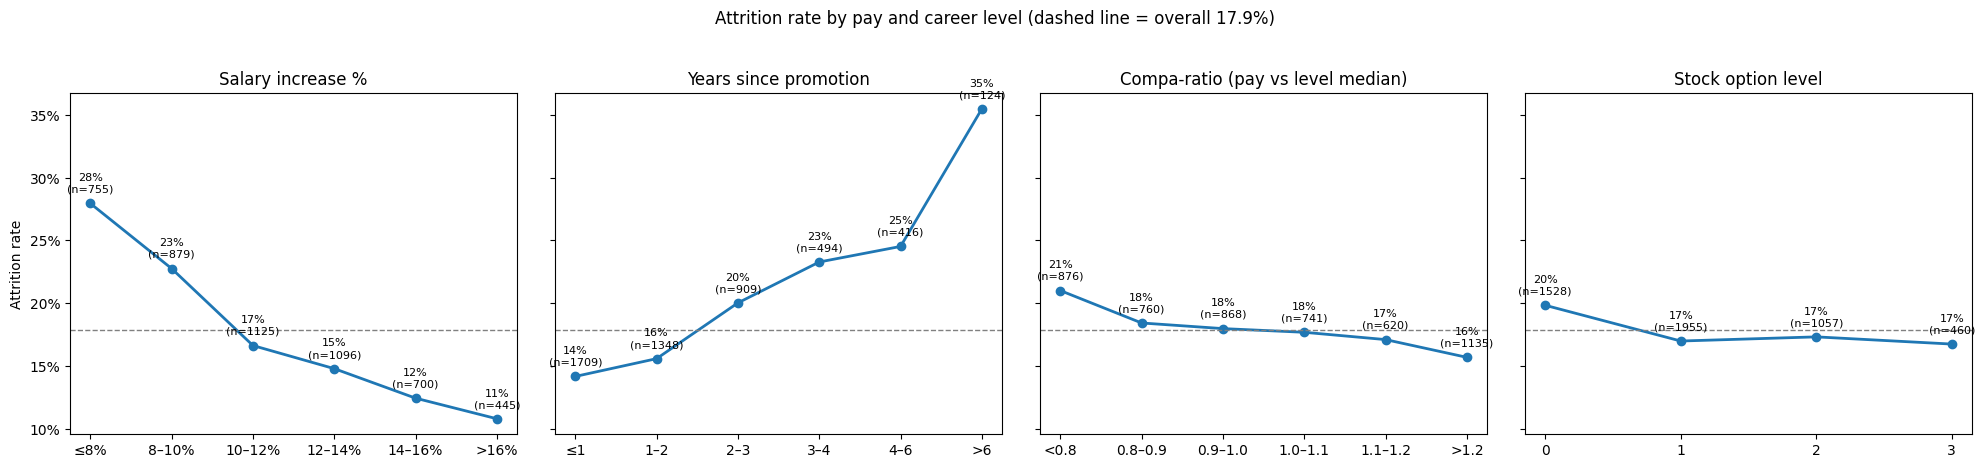


Salary increase %


,headcount,attrition_rate
salary_hike_pct,,
≤8%,755,27.9%
8–10%,879,22.8%
10–12%,1125,16.6%
12–14%,1096,14.8%
14–16%,700,12.4%
>16%,445,10.8%



Years since promotion


,headcount,attrition_rate
years_since_promotion,,
≤1,1709,14.2%
1–2,1348,15.6%
2–3,909,20.0%
3–4,494,23.3%
4–6,416,24.5%
>6,124,35.5%



Compa-ratio (pay vs level median)


,headcount,attrition_rate
compa_ratio,,
<0.8,876,21.0%
0.8–0.9,760,18.4%
0.9–1.0,868,18.0%
1.0–1.1,741,17.7%
1.1–1.2,620,17.1%
>1.2,1135,15.7%



Stock option level


,headcount,attrition_rate
stock_option_level,,
0,1528,19.8%
1,1955,17.0%
2,1057,17.3%
3,460,16.7%


In [ ]:
band_specs = {
    'salary_hike_pct':       ([-0.1, 8, 10, 12, 14, 16, 30], ['≤8%', '8–10%', '10–12%', '12–14%', '14–16%', '>16%']),
    'years_since_promotion': ([-0.1, 1, 2, 3, 4, 6, 20],     ['≤1', '1–2', '2–3', '3–4', '4–6', '>6']),
    'compa_ratio':           ([0, 0.8, 0.9, 1.0, 1.1, 1.2, 5], ['<0.8', '0.8–0.9', '0.9–1.0', '1.0–1.1', '1.1–1.2', '>1.2']),
    'stock_option_level':    ([-0.5, 0.5, 1.5, 2.5, 3.5],    ['0', '1', '2', '3']),
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
pc_bands = {}
for ax, (col, (bins, labs)) in zip(axes, band_specs.items()):
    bands = pd.cut(hr[col], bins=bins, labels=labs)
    t = hr.groupby(bands, observed=True)['left'].agg(headcount='count', attrition_rate='mean')
    pc_bands[col] = t
    ax.plot(t.index.astype(str), t['attrition_rate'], marker='o', linewidth=2)
    for x, (rate, n) in enumerate(zip(t['attrition_rate'], t['headcount'])):
        ax.annotate(f'{rate:.0%}\n(n={n})', (x, rate), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=8)
    ax.axhline(hr['left'].mean(), color='grey', linestyle='--', linewidth=1)
    ax.set_title(labels_pc[col])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].set_ylabel('Attrition rate')
plt.suptitle('Attrition rate by pay and career level (dashed line = overall 17.9%)', y=1.03)
plt.tight_layout()
plt.show()

for col, t in pc_bands.items():
    print(f'\n{labels_pc[col]}')
    display(t.style.format({'attrition_rate': '{:.1%}'}))

**Finding:**

Attrition rises steadily as raises shrink and promotions stall.

Attrition falls consistently as salary increases grow: from 27.9% for employees with increases of 8% or less to 10.8% for those above 16%. It rises steadily with time since promotion: from only 14.2% attrition for employees promoted within the last year to 23.3% at 3–4 years and then 35.5% beyond 6 years (124 employees).

Pay relative to peers shows only a gentle slope (21.0% for compa-ratio below 0.8 vs 15.7% above 1.2), and stock options are nearly flat (19.8% with none vs 16.7–17.3% with some).

**Do raises and promotions follow performance?**

In [ ]:
# 1. How closely are salary increases tied to performance?
rho, p_rho = spearmanr(hr['performance_rating'], hr['salary_hike_pct'])
print(f"Spearman correlation, performance vs salary increase: ρ = {rho:.3f} (p = {p_rho:.1e})")
display(hr.groupby('performance_rating')['salary_hike_pct'].median().to_frame('median_increase_%'))

# 2. Attrition by performance × salary increase
hr['hike_band'] = pd.cut(hr['salary_hike_pct'], [-0.1, 10, 13, 30], labels=['Low (≤10%)', 'Mid (10–13%)', 'High (>13%)'])
display(pd.crosstab(hr['performance_rating'], hr['hike_band'], values=hr['left'], aggfunc='mean')
          .style.format('{:.1%}').background_gradient(cmap='Reds', axis=None))
display(pd.crosstab(hr['performance_rating'], hr['hike_band']))
print('-'*60)
# 3. Attrition by performance × stalled promotion (more than 3 years since last promotion)
hr['promotion_stalled'] = np.where(hr['years_since_promotion'] > 3, 'Stalled (>3 yrs)', 'Recent (≤3 yrs)')
display(pd.crosstab(hr['performance_rating'], hr['promotion_stalled'], values=hr['left'], aggfunc='mean')
          .style.format('{:.1%}').background_gradient(cmap='Reds', axis=None))
display(pd.crosstab(hr['performance_rating'], hr['promotion_stalled']))

Spearman correlation, performance vs salary increase: ρ = 0.085 (p = 1.6e-09)


,median_increase_%
performance_rating,
2,10.8
3,11.2
4,11.8
5,12.2


hike_band,Low (≤10%),Mid (10–13%),High (>13%)
performance_rating,,,
2,33.8%,30.8%,17.5%
3,31.5%,21.1%,16.4%
4,20.4%,12.6%,11.0%
5,13.0%,3.9%,7.2%


hike_band,Low (≤10%),Mid (10–13%),High (>13%)
performance_rating,,,
2,65,52,40
3,683,701,568
4,794,859,893
5,92,128,125


------------------------------------------------------------


promotion_stalled,Recent (≤3 yrs),Stalled (>3 yrs)
performance_rating,,
2,28.1%,30.6%
3,21.0%,31.4%
4,12.8%,21.0%
5,6.6%,12.1%


promotion_stalled,Recent (≤3 yrs),Stalled (>3 yrs)
performance_rating,,
2,121,36
3,1516,436
4,2042,504
5,287,58


**Findings:**

Raises are weakly linked to performance, and under-rewarded good performers leave.

- Salary increases barely reflect performance (corr = 0.085): the median salary increase is 10.8% for employees rated 2 and only 12.2% for those rated 5. This matters for retention.

- Among employees rated 4 which is the largest performance group (2,546 people), those with a low raise (≤10%) leave at 20.4% rate, almost double the 11.0% of those with a high raise (>13%).
- Promotion delays show the same pattern. Rating-4 employees with no promotion for over 3 years leave at 21.0%, compared with 12.8% for those promoted more recently. The result of rating-5 employees are consistent with this result, where attrition rise from 6.6% to 12.1% based on whether they're recently promoted or not (though the headcount is much lower so it should be treated as indicative).

This points to **regretted attrition** which means the company is losing solid performers whose rewards do not reflect their contribution.

**How much do pay and career explain, beyond wellbeing?**

*does variables like pay and career explain anything extra? This matters because a stalled career could be linked to burnout or low engagement. If pay and career added nothing beyond wellbeing, they’d just be another view of the same problem.*

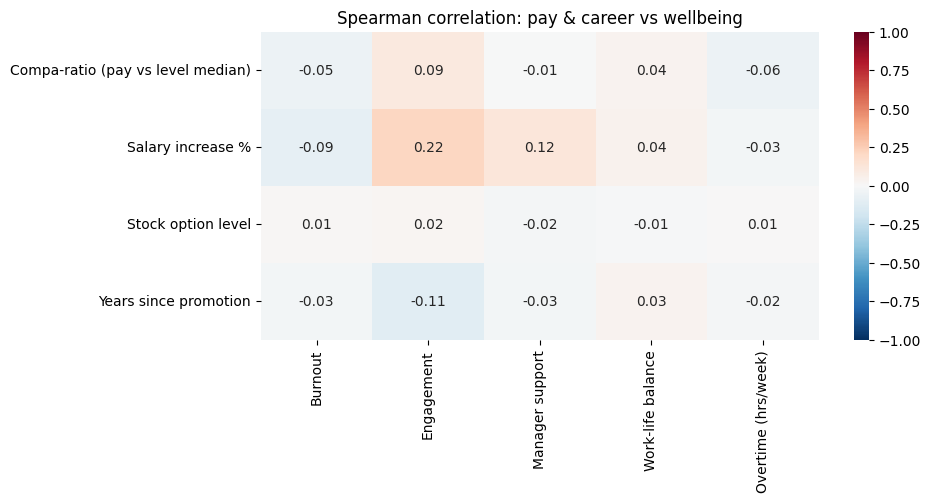

Largest absolute correlation: 0.218
Pairs with |ρ| ≥ 0.1: 3 of 20


In [ ]:
pay_model_vars = ['compa_ratio', 'salary_hike_pct', 'stock_option_level', 'years_since_promotion']
wellbeing = ['burnout_score', 'engagement_score', 'manager_support_score',
             'work_life_balance_score', 'overtime_hours_per_week']

# Spearman correlation: each pay/career variable against each wellbeing variable
rho = pd.DataFrame(index=pay_model_vars, columns=wellbeing, dtype=float)
pval = rho.copy()
for p in pay_model_vars:
    for w in wellbeing:
        rho.loc[p, w], pval.loc[p, w] = spearmanr(hr[p], hr[w])

plt.figure(figsize=(9, 4))
sns.heatmap(rho.rename(index=labels_pc, columns=labels), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Spearman correlation: pay & career vs wellbeing')
plt.show()

print(f"Largest absolute correlation: {rho.abs().max().max():.3f}")
print(f"Pairs with |ρ| ≥ 0.1: {(rho.abs() >= 0.1).sum().sum()} of {rho.size}")

In [ ]:
pay_model_vars = ['compa_ratio', 'salary_hike_pct', 'stock_option_level', 'years_since_promotion']
wellbeing = ['burnout_score', 'engagement_score', 'manager_support_score',
             'work_life_balance_score', 'overtime_hours_per_week']

def fit_logit(df, cols):
    Z = (df[cols] - df[cols].mean()) / df[cols].std()
    X = sm.add_constant(Z)
    m = sm.Logit(df['left'], X).fit(disp=0)
    return m, roc_auc_score(df['left'], m.predict(X))

m_pay, auc_pay = fit_logit(hr, pay_model_vars)
m_wb, auc_wb = fit_logit(hr, wellbeing)
m_both, auc_both = fit_logit(hr, wellbeing + pay_model_vars)

summary = pd.DataFrame({
    'model': ['Pay & career only', 'Wellbeing only', 'Wellbeing + pay & career'],
    'pseudo_R2': [m_pay.prsquared, m_wb.prsquared, m_both.prsquared],
    'AUC': [auc_pay, auc_wb, auc_both]}).round(3)
display(summary)

# Likelihood-ratio test: does adding pay & career significantly improve the wellbeing model?
lr_stat = 2 * (m_both.llf - m_wb.llf)
lr_p = chi2.sf(lr_stat, df=len(pay_model_vars))
print(f"Likelihood-ratio test: χ²({len(pay_model_vars)}) = {lr_stat:.1f}, p = {lr_p:.1e}")

def or_table(m, df):
    """Odds ratios per 1 SD, plus what 1 SD equals and the effect per 1 original unit."""
    cols = m.params.index.drop('const')
    sd = df[cols].std()                     # what "1 unit" in the model equals in real terms
    or_sd = np.exp(m.params[cols])

    t = pd.DataFrame({
        'SD': sd, #standard deviation
        'odds_ratio (per SD)': or_sd,
        'ci_low': np.exp(m.conf_int().loc[cols, 0]),
        'ci_high': np.exp(m.conf_int().loc[cols, 1]),
        'p_value': m.pvalues[cols],
    })
    t['pct_change_per_SD'] = (t['odds_ratio (per SD)'] - 1) * 100
    t['odds_ratio (per unit)'] = or_sd ** (1 / sd)
    t['pct_change_per_unit'] = (t['odds_ratio (per unit)'] - 1) * 100
    return t.round({'SD': 2, 'odds_ratio (per SD)': 3, 'ci_low': 3, 'ci_high': 3,
                    'p_value': 4, 'pct_change_per_SD': 1, 'odds_ratio (per unit)': 3,
                    'pct_change_per_unit': 1})

print("\nPay & career only:");          display(or_table(m_pay, hr))
print("\nWellbeing + pay & career:");   display(or_table(m_both, hr))

,model,pseudo_R2,AUC
0,Pay & career only,0.027,0.620
1,Wellbeing only,0.143,0.763
2,Wellbeing + pay & career,0.160,0.778


Likelihood-ratio test: χ²(4) = 78.9, p = 2.9e-16

Pay & career only:


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
compa_ratio,0.24,0.886,0.822,0.955,0.0015,-11.4,0.605,-39.5
salary_hike_pct,3.41,0.743,0.684,0.807,0.0000,-25.7,0.916,-8.4
stock_option_level,0.94,0.912,0.847,0.983,0.0160,-8.8,0.907,-9.3
years_since_promotion,1.63,1.153,1.068,1.245,0.0003,15.3,1.092,9.2



Wellbeing + pay & career:


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
burnout_score,1.54,1.634,1.450,1.842,0.0000,63.4,1.376,37.6
engagement_score,1.50,0.750,0.664,0.846,0.0000,-25.0,0.825,-17.5
manager_support_score,1.84,0.706,0.636,0.783,0.0000,-29.4,0.827,-17.3
work_life_balance_score,1.29,0.923,0.828,1.029,0.1469,-7.7,0.940,-6.0
overtime_hours_per_week,4.47,1.172,1.059,1.298,0.0022,17.2,1.036,3.6
compa_ratio,0.24,0.938,0.865,1.017,0.1215,-6.2,0.766,-23.4
salary_hike_pct,3.41,0.861,0.786,0.942,0.0012,-13.9,0.957,-4.3
stock_option_level,0.94,0.888,0.819,0.963,0.0040,-11.2,0.881,-11.9
years_since_promotion,1.63,1.274,1.171,1.386,0.0000,27.4,1.160,16.0


**Finding:**

Pay and career explain a smaller but distinct share of attrition.

On their own, compa-ratio, salary increase, stock options and years since promotion explain little (pseudo R² 0.027, AUC 0.620). However, adding them to the wellbeing model significantly improves it (likelihood-ratio test χ²(4) = 78.9, p < 0.001), raising pseudo R² from 0.143 to 0.160 and AUC from 0.763 to 0.778.

Pay and career factors are only weakly related to the wellbeing scores (17 of 20 Spearman correlations are below 0.1), and the strongest is between salary increase and engagement (corr = 0.22). They therefore capture a largely separate reason for leaving. The small overlap with engagement explains why the effect of salary increase weakens once wellbeing is taken into account (OR 0.74 → 0.86), while the effect of years since promotion becomes stronger (OR 1.15 → 1.27).

Holding wellbeing constant:
- Each additional year without promotion raises the odds of leaving by 16% (OR per unit 1.16).
- Each percentage-point higher salary-increase lowers the odds by 4% (OR per unit 0.96).
- Each additional stock option level lowers the odds by ~11-12% (OR per unit 0.88).
- Pay relative to peers has no independent effect (p = 0.12).

**Is “years since promotion” just a tenure effect?**

*people who’ve been at the company longer naturally have more time to go without a promotion. If long-serving employees were simply more likely to leave, “years since promotion” might only be a stand-in for tenure. The analysis below holds tenure constant to check*

In [ ]:
# Uses years_at_company, so exclude the 59 impossible-tenure rows (sanity check decision)
hr_history = hr[~hr['flag_tenure_>_total_working_years']]

rho_t, _ = spearmanr(hr_history['years_since_promotion'], hr_history['years_at_company'])
print(f"Correlation, years since promotion vs tenure: ρ = {rho_t:.2f}  ({len(hr_history)} employees)")

m_tenure, _ = fit_logit(hr_history, ['years_since_promotion', 'years_at_company'])
display(or_table(m_tenure, hr_history))

Correlation, years since promotion vs tenure: ρ = 0.21  (4941 employees)


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
years_since_promotion,1.63,1.362,1.270,1.461,0.0,36.2,1.209,20.9
years_at_company,3.51,0.829,0.766,0.897,0.0,-17.1,0.948,-5.2


**Finding:**

The effect of promotion delays is not explained by tenure.

Years since promotion is only weakly related to tenure (corr = 0.21). Holding tenure constant (excluding the 59 employees with impossible tenure values), each additional 1.6 years without promotion still raises the odds of leaving by 36% (OR per SD 1.36), while longer tenure itself is protective (OR 0.83). It is the wait for promotion, not time at the company, that is linked to leaving.


**Robustness check (comparing dataset with flagged rows vs without)**

In [ ]:
clean = hr[~hr['flag_any_issue']].copy()
# Recalculate compa-ratio within the clean subset
clean['compa_ratio'] = clean['monthly_income'] / clean.groupby('job_level')['monthly_income'].transform('median')

m_clean, auc_clean = fit_logit(clean, wellbeing + pay_model_vars)
robust = pd.DataFrame({'OR_all': np.exp(m_both.params), 'p_all': m_both.pvalues,
                       'OR_clean': np.exp(m_clean.params), 'p_clean': m_clean.pvalues}).drop('const')
display(robust.loc[pay_model_vars].round(4))
print(f"AUC on clean subset: {auc_clean:.3f} ({len(clean)} employees)")

,OR_all,p_all,OR_clean,p_clean
compa_ratio,0.9378,0.1215,0.9369,0.1751
salary_hike_pct,0.8607,0.0012,0.8841,0.0222
stock_option_level,0.8878,0.0040,0.8936,0.0189
years_since_promotion,1.2742,0.0000,1.2393,0.0000


AUC on clean subset: 0.771 (3642 employees)


Based on the robustness check above, all results hold when the 1,358 flagged employees are excluded, including those with role/level mismatches that affect the compa-ratio (AUC 0.771; promotion OR 1.24, salary increase OR 0.88, stock options OR 0.89).

**Conclusion - Objective 3:**

- Employees are more likely to leave when their **careers stall**. small salary increases and long gaps since promotion, not low pay itself. Pay relative to peers has no independent effect once other factors are considered, and training hours show no link to attrition.

- Pay and career progression explain less than wellbeing factors, but they capture a separate reason for leaving. Adding them to the wellbeing model significantly improves it (AUC 0.763 → 0.778, p < 0.05). The two areas are almost unrelated, so they call for different actions.

**Business implications**
1. **Review employees approaching 3 years without promotion.** Attrition rises noticeably beyond this point, especially among good performers (rating 4: 12.8% → 21.0%). A promotion, a stretch role or a clear career-path conversation could address this.
2. **Link salary increases more closely to performance.** Increases currently barely differ between ratings (10.8% vs 12.2%), and well-rated employees on low raises leave at nearly twice the rate of those on high raises. Differentiating raises would focus spending where it protects valuable staff.
3. **Prioritise raises and progression over across-the-board pay adjustments.** Pay relative to peers does not independently predict exits, so broad market corrections are less likely to reduce attrition than targeted increases and promotions.
4. **Stock options offer a modest retention lever.** Each additional level is associated with 11% lower odds of leaving, after accounting for other factors.

**Limitations**
- The data is a single snapshot, so these are associations rather than proven causes. For example, employees already planning to leave may receive smaller raises, rather than small raises causing exits.
- The compa-ratio is calculated against job-level medians. Job level is unreliable for some employees (role/level mismatches), although results hold when they are excluded.
- No currency or market salary data is available, so pay can only be compared within the company, not against the external market.

Note: In the combined model, performance rating stopped being significant once wellbeing and pay were included (OR = 0.96, p = 0.37). The strong performance link from the first part of analysis seems to work through these factors: low performers report higher burnout (5.0 at rating 2 vs 3.2 at rating 5) and lower engagement. This is worth exploring building the full model.

## Work arrangements and AI - Do work mode, commute and travel affect attrition? And does perceived AI job risk raise the chance of leaving, and does that differ for people who use AI tools?

**Initial setup**

In [ ]:
hr['left'] = (hr['attrition'] == 'Yes').astype(int)
hr['uses_ai'] = hr['uses_ai_tools_at_work'].astype(int)   # True/False → 1/0

wellbeing = ['burnout_score', 'engagement_score', 'manager_support_score',
             'work_life_balance_score', 'overtime_hours_per_week']

def fit_model(df, continuous=[], categorical=[], ref=None):
    """
    Logistic regression with continuous variables standardised (per 1 SD)
    and categorical variables as 0/1 dummy columns compared with a reference group.
    hybrid work mode is chosen as the reference group
    """
    parts = []
    if continuous:
        parts.append((df[continuous] - df[continuous].mean()) / df[continuous].std())
    for col in categorical:
        d = pd.get_dummies(df[col], prefix=col, dtype=int)
        drop = f"{col}_{ref[col]}" if ref and col in ref else d.columns[0]
        parts.append(d.drop(columns=drop))
    X = sm.add_constant(pd.concat(parts, axis=1))
    m = sm.Logit(df['left'], X).fit(disp=0)
    return m, roc_auc_score(df['left'], m.predict(X))

def or_table_mixed(m, df, continuous=[]):
    """Odds ratios per 1 SD, plus what 1 SD equals and the effect per 1 original unit.
    Dummy variables (e.g. work_mode_Onsite) are compared with the reference group:
    they have no SD, and their 'per SD' and 'per unit' odds ratios are the same."""
    cols = m.params.index.drop('const')
    or_sd = np.exp(m.params[cols])
    sd = pd.Series([df[c].std() if c in continuous else np.nan for c in cols], index=cols)

    t = pd.DataFrame({
        'SD': sd, #standard deviation (blank for dummy variables)
        'odds_ratio (per SD)': or_sd,
        'ci_low': np.exp(m.conf_int().loc[cols, 0]),
        'ci_high': np.exp(m.conf_int().loc[cols, 1]),
        'p_value': m.pvalues[cols],
    })
    t['pct_change_per_SD'] = (t['odds_ratio (per SD)'] - 1) * 100
    t['odds_ratio (per unit)'] = [or_sd[c] ** (1 / sd[c]) if c in continuous else or_sd[c] for c in cols]
    t['pct_change_per_unit'] = (t['odds_ratio (per unit)'] - 1) * 100
    return t.round({'SD': 2, 'odds_ratio (per SD)': 3, 'ci_low': 3, 'ci_high': 3,
                    'p_value': 4, 'pct_change_per_SD': 1, 'odds_ratio (per unit)': 3,
                    'pct_change_per_unit': 1})

**Work mode — does the effect survive once wellbeing is considered?**

In [ ]:
# 1. Attrition and wellbeing by work mode
wm_profile = hr.groupby('work_mode').agg(
    headcount=('left', 'count'), attrition_rate=('left', 'mean'),
    burnout=('burnout_score', 'mean'), work_life_balance=('work_life_balance_score', 'mean'),
    overtime=('overtime_hours_per_week', 'mean'))
display(wm_profile.style.format({'attrition_rate': '{:.1%}', 'burnout': '{:.2f}',
                                 'work_life_balance': '{:.2f}', 'overtime': '{:.1f}'}))

# 2. Three models: work mode alone → + wellbeing → + wellbeing + department
ref = {'work_mode': 'Hybrid', 'department': 'Engineering'}
m_wm1, _ = fit_model(hr, categorical=['work_mode'], ref=ref)
m_wm2, _ = fit_model(hr, continuous=wellbeing, categorical=['work_mode'], ref=ref)
m_wm3, _ = fit_model(hr, continuous=wellbeing, categorical=['work_mode', 'department'], ref=ref)

wm_compare = pd.DataFrame({
    'OR alone': np.exp(m_wm1.params[['work_mode_Onsite', 'work_mode_Remote']]),
    'p alone': m_wm1.pvalues[['work_mode_Onsite', 'work_mode_Remote']],
    'OR + wellbeing': np.exp(m_wm2.params[['work_mode_Onsite', 'work_mode_Remote']]),
    'p + wellbeing': m_wm2.pvalues[['work_mode_Onsite', 'work_mode_Remote']],
    'OR + wellbeing + dept': np.exp(m_wm3.params[['work_mode_Onsite', 'work_mode_Remote']]),
    'p + wellbeing + dept': m_wm3.pvalues[['work_mode_Onsite', 'work_mode_Remote']],
}).round(4)
print("Odds ratios compared with hybrid employees:")
display(wm_compare)

,headcount,attrition_rate,burnout,work_life_balance,overtime
work_mode,,,,,
Hybrid,2237,16.8%,3.99,6.05,6.8
Onsite,1742,21.2%,4.41,5.92,6.9
Remote,1021,14.7%,3.48,6.66,6.7


Odds ratios compared with hybrid employees:


,OR alone,p alone,OR + wellbeing,p + wellbeing,OR + wellbeing + dept,p + wellbeing + dept
work_mode_Onsite,1.3302,0.0005,1.1894,0.0523,1.1921,0.0499
work_mode_Remote,0.8524,0.1280,1.0077,0.9470,0.9879,0.9165


**Finding:**

Work-mode differences are mostly explained by wellbeing.

Onsite employees leave more often than hybrid employees (21.2% vs 16.8%), corresponding to 33% higher odds of leaving (OR 1.33, p < 0.001). Remote employees leave slightly less often (14.7%, 15% lower odds), but this difference is not statistically significant (p = 0.13). However, onsite employees also report the highest burnout (mean 4.41, vs 3.99 for hybrid and 3.48 for remote employees).

When employees with similar wellbeing are compared, the difference between remote and hybrid employees disappears completely (OR 1.01, p = 0.95), and the onsite difference shrinks from 33% to 19% higher odds, which is only borderline significant (p = 0.052; p = 0.050 when department is also held constant).

Work mode therefore appears to be linked to attrition largely through wellbeing: onsite employees report more burnout, and burnout is a strong driver of exits. A small direct effect of working onsite cannot be ruled out, but most of the gap reflects differences in wellbeing.

**Commute - does longer commutes lead to more exits?**

In [ ]:
# 1. Leavers vs stayers: everyone, then excluding remote staff
def mw_compare(df, col):
    L, S = df[df['left'] == 1][col], df[df['left'] == 0][col]
    u, p = mannwhitneyu(L, S, alternative='two-sided')
    return {'median_leavers': L.median(), 'median_stayers': S.median(),
            'p_value': p, 'rank_biserial': round(2 * u / (len(L) * len(S)) - 1, 3)}

non_remote = hr[hr['work_mode'] != 'Remote']
print("="*30, "Leavers Stayers Commute Comparison (overall vs hybrid/onsite)","="*30)
display(pd.DataFrame({'All employees': mw_compare(hr, 'commute_minutes'),
                      'Onsite & hybrid only': mw_compare(non_remote, 'commute_minutes')}).T)

print("="*30, "Commute descriptive statistics by work mode","="*30)
display(hr.groupby('work_mode')['commute_minutes'].describe().round(1))

print("="*30, "Attrition by Commute Band (onsite & hybrid only)","="*30)
# 2. Attrition by commute band (onsite & hybrid only)
commute_bands = pd.cut(non_remote['commute_minutes'], [-1, 15, 30, 45, 60, 120],
                       labels=['≤15', '15–30', '30–45', '45–60', '>60'])
display(non_remote.groupby(commute_bands, observed=True)['left']
        .agg(headcount='count', attrition_rate='mean').style.format({'attrition_rate': '{:.1%}'}))
print("="*30, "Commute Model holding work mode constant","="*30)
# 3. Commute holding work mode constant
m_com, _ = fit_model(hr, continuous=['commute_minutes'], categorical=['work_mode'], ref=ref)
display(or_table_mixed(m_com, hr, continuous=['commute_minutes']))

============================== Leavers Stayers Commute Comparison (overall vs hybrid/onsite) ==============================


,median_leavers,median_stayers,p_value,rank_biserial
All employees,35.0,32.0,0.000842,0.071
Onsite & hybrid only,39.0,38.0,0.080125,0.041


============================== Commute descriptive statistics by work mode ==============================


,count,mean,std,min,25%,50%,75%,max
work_mode,,,,,,,,
Hybrid,2237.0,37.9,15.5,3.0,27.0,38.0,48.0,92.0
Onsite,1742.0,38.3,15.4,3.0,28.0,38.0,49.0,85.0
Remote,1021.0,4.2,2.8,0.0,2.0,4.0,6.0,14.0


============================== Attrition by Commute Band (onsite & hybrid only) ==============================


,headcount,attrition_rate
commute_minutes,,
≤15,298,16.1%
15–30,967,17.5%
30–45,1462,19.5%
45–60,963,19.1%
>60,289,20.4%


============================== Commute Model holding work mode constant ==============================


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
commute_minutes,19.44,1.087,0.983,1.201,0.1035,8.7,1.004,0.4
work_mode_Onsite,NaN,1.328,1.132,1.558,0.0005,32.8,1.328,32.8
work_mode_Remote,NaN,0.986,0.752,1.293,0.9187,-1.4,0.986,-1.4


**Finding:**

Commute time has no independent effect.

Leavers have slightly longer commutes overall (35 vs 32 minutes, Mann-Whitney p < 0.001), but the effect is negligible (rank-biserial r = +0.07). This small gap reflects work mode where remote employees commute very little (median 4 minutes) and leave less often.

Among onsite and hybrid employees only, the difference is not significant (39 vs 38 minutes, p = 0.08), and commute time does not predict attrition once work mode is held constant (OR 1.09 per 19 minutes, about +0.4% odds per minute, p = 0.10).

**Business travel - does travel relates to exits**

*The analysis tests whether travel relates to exits overall, by band, within each department, and holding department constant. The within-department step matters because Sales and Operations travel about 22 days a year versus 6 elsewhere. Without it, travel and department are mixed together.*

In [ ]:
# 1. Leavers vs stayers
print("="*30, "Leavers vs Stayers Travel Comparison","="*30)
display(pd.DataFrame({'All employees': mw_compare(hr, 'business_travel_days_per_year')}).T)

# 2. Attrition by travel band
print("="*30, "Attrition by Travel Band","="*30)
travel_bands = pd.cut(hr['business_travel_days_per_year'], [-1, 5, 10, 20, 30, 60],
                      labels=['0–5', '5–10', '10–20', '20–30', '>30'])
display(hr.groupby(travel_bands, observed=True)['left']
        .agg(headcount='count', attrition_rate='mean').style.format({'attrition_rate': '{:.1%}'}))

# 3. Travel is concentrated in Sales and Operations, so test within each department
print("="*30, "Median Travel by Department","="*30)
display(hr.groupby('department')['business_travel_days_per_year'].median().to_frame('median_travel_days'))
within = []
for dept, g in hr.groupby('department'):
    r = mw_compare(g, 'business_travel_days_per_year')
    within.append({
        'department': dept,
        'leavers': int(g['left'].sum()),
        'stayers': int((g['left'] == 0).sum()),
        'median_leavers': r['median_leavers'],
        'median_stayers': r['median_stayers'],
        'p_value': round(r['p_value'], 3),
        'rank_biserial': r['rank_biserial'],
        'direction': ('leavers travel more' if r['rank_biserial'] > 0 else 'leavers travel less')
                     if r['p_value'] < 0.05 else 'no significant difference',
    })
print("="*30, "Statistical Test by Department","="*30)
display(pd.DataFrame(within))

# 4. Travel holding department constant
print("="*30, "Travel Model Holding Department Constant","="*30)
m_tr, _ = fit_model(hr, continuous=['business_travel_days_per_year'], categorical=['department'], ref=ref)
display(or_table_mixed(m_tr, hr, continuous=['business_travel_days_per_year']).head(1))

============================== Leavers vs Stayers Travel Comparison ==============================


,median_leavers,median_stayers,p_value,rank_biserial
All employees,7.0,7.0,0.621913,0.01


============================== Attrition by Travel Band ==============================


,headcount,attrition_rate
business_travel_days_per_year,,
0–5,1568,17.9%
5–10,1802,17.4%
10–20,704,18.5%
20–30,851,18.7%
>30,75,14.7%


============================== Median Travel by Department ==============================


,median_travel_days
department,
Customer Support,6.0
Engineering,6.0
Finance,6.0
Human Resources,6.0
Marketing,6.0
Operations,22.0
Research & Development,6.0
Sales,22.0


============================== Statistical Test by Department ==============================


,department,leavers,stayers,median_leavers,median_stayers,p_value,rank_biserial,direction
0,Customer Support,153,483,6.0,6.0,0.323,-0.053,no significant difference
1,Engineering,194,1142,6.0,6.0,0.331,0.043,no significant difference
2,Finance,79,357,6.0,6.0,0.902,0.009,no significant difference
3,Human Resources,44,200,6.0,6.0,0.455,-0.071,no significant difference
4,Marketing,83,357,6.0,6.0,0.971,-0.003,no significant difference
5,Operations,114,549,22.0,22.0,0.946,-0.004,no significant difference
6,Research & Development,61,349,6.0,6.0,0.880,-0.012,no significant difference
7,Sales,167,668,21.0,22.0,0.024,-0.113,leavers travel less


============================== Travel Model Holding Department Constant ==============================


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
business_travel_days_per_year,8.09,0.865,0.723,1.034,0.1104,-13.5,0.982,-1.8


**Finding:**

Business travel is not linked to attrition.

Leavers and stayers travel the same amount (median 7 days per year for both; p = 0.62, rank-biserial r = 0.01), and attrition is flat across travel levels (14.7%–18.7%). Travel is concentrated in Sales and Operations (median 22 days vs 6 elsewhere), so it was also tested within each department.

Within departments, only Sales shows a significant difference, and in the opposite direction to what might be expected: Sales leavers travelled slightly *less* than stayers (median 21 vs 22 days; p = 0.024, rank-biserial r = −0.11, a small effect). With 1 significant result out of 8 department tests, this is consistent with chance, and a one-day difference is too small to be practically meaningful. Travel also shows no effect once department is held constant (OR 0.86 per SD, p = 0.11).

**Perceived AI job risk - do employees who feel their job is threatened by AI are more likely to leave**

*This analysis also checks a possible confounder: if some departments both feel more AI risk and have higher attrition for other reasons, the AI-risk effect could just be a department effect*

============================== Leavers vs Stayers AI Perceived Risk Comparison ==============================


,median_leavers,median_stayers,p_value,rank_biserial
All employees,5.3,4.8,7.2e-11,0.139


============================== Attrition rate by perceived AI risk band ==============================


,headcount,attrition_rate
perceived_ai_job_risk,,
1–3,847,13.2%
3–4.5,1336,15.6%
4.5–6,1517,18.8%
6–7.5,940,20.5%
7.5–10,360,26.7%


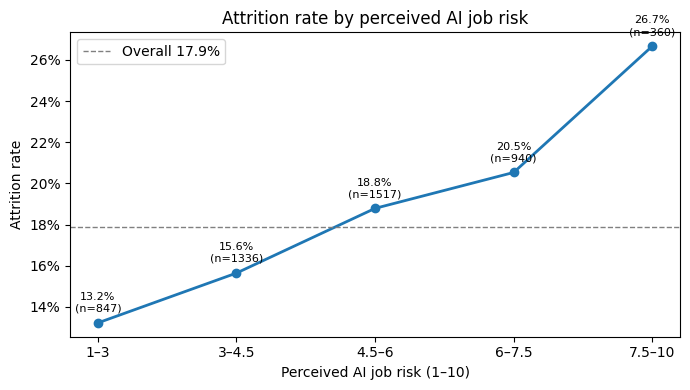

============================== Perceived AI risk and attrition by department ==============================


,mean_perceived_ai_risk,attrition_rate,headcount
department,,,
Customer Support,6.30,24.1%,636
Marketing,5.49,18.9%,440
Finance,5.47,18.1%,436
Sales,5.19,20.0%,835
Operations,4.93,17.2%,663
Human Resources,4.73,18.0%,244
Engineering,3.90,14.5%,1336
Research & Development,3.69,14.9%,410


============================== Odds ratio for perceived AI risk across models ==============================
1 SD of perceived AI risk = 1.83 points (1 unit = 1 point on the 1–10 scale)


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
Alone,1.83,1.286,1.195,1.383,0.0000,28.6,1.147,14.7
+ department,1.83,1.225,1.129,1.330,0.0000,22.5,1.117,11.7
+ wellbeing,1.83,1.228,1.134,1.331,0.0000,22.8,1.119,11.9
+ wellbeing + department,1.83,1.205,1.101,1.318,0.0001,20.5,1.107,10.7


In [ ]:
# Helper (also defined in Cell 2; repeated so this cell runs on its own)
def mw_compare(df, col):
    L, S = df[df['left'] == 1][col], df[df['left'] == 0][col]
    u, p = mannwhitneyu(L, S, alternative='two-sided')
    return {'median_leavers': L.median(), 'median_stayers': S.median(),
            'p_value': p, 'rank_biserial': round(2 * u / (len(L) * len(S)) - 1, 3)}

# ── 1. Leavers vs stayers ─────────────────────────────────────────────
print("="*30, "Leavers vs Stayers AI Perceived Risk Comparison","="*30)
ai_mw = pd.DataFrame({'All employees': mw_compare(hr, 'perceived_ai_job_risk')}).T
ai_mw['p_value'] = ai_mw['p_value'].map(lambda p: f'{p:.1e}')
display(ai_mw)

# ── 2. Attrition by AI-risk band ──────────────────────────────────────
print("="*30, "Attrition rate by perceived AI risk band","="*30)
risk_bands = pd.cut(hr['perceived_ai_job_risk'], [0, 3, 4.5, 6, 7.5, 10],
                    labels=['1–3', '3–4.5', '4.5–6', '6–7.5', '7.5–10'])
ai_band_table = hr.groupby(risk_bands, observed=True)['left'].agg(headcount='count', attrition_rate='mean')
display(ai_band_table.style.format({'attrition_rate': '{:.1%}'}))

plt.figure(figsize=(7, 4))
plt.plot(ai_band_table.index.astype(str), ai_band_table['attrition_rate'], marker='o', linewidth=2)
for x, (rate, n) in enumerate(zip(ai_band_table['attrition_rate'], ai_band_table['headcount'])):
    plt.annotate(f'{rate:.1%}\n(n={n})', (x, rate), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
plt.axhline(hr['left'].mean(), color='grey', linestyle='--', linewidth=1, label=f"Overall {hr['left'].mean():.1%}")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.xlabel('Perceived AI job risk (1–10)'); plt.ylabel('Attrition rate')
plt.title('Attrition rate by perceived AI job risk'); plt.legend()
plt.tight_layout(); plt.show()

# ── 3. Perceived AI risk by department (possible confounder) ──────────
print("="*30, "Perceived AI risk and attrition by department","="*30)
ai_dept = hr.groupby('department').agg(mean_perceived_ai_risk=('perceived_ai_job_risk', 'mean'),
                                       attrition_rate=('left', 'mean'),
                                       headcount=('left', 'count')
                                      ).sort_values('mean_perceived_ai_risk', ascending=False)
display(ai_dept.style.format({'mean_perceived_ai_risk': '{:.2f}', 'attrition_rate': '{:.1%}'}))

# ── 4. Does the effect hold after controlling for department and wellbeing? ──
print("="*30, "Odds ratio for perceived AI risk across models","="*30)
ai_models = {
    'Alone': fit_model(hr, continuous=['perceived_ai_job_risk'])[0],
    '+ department': fit_model(hr, continuous=['perceived_ai_job_risk'], categorical=['department'], ref=ref)[0],
    '+ wellbeing': fit_model(hr, continuous=['perceived_ai_job_risk'] + wellbeing)[0],
    '+ wellbeing + department': fit_model(hr, continuous=['perceived_ai_job_risk'] + wellbeing,
                                          categorical=['department'], ref=ref)[0],
}
sd_ai = hr['perceived_ai_job_risk'].std()

ai_compare = pd.DataFrame({
    name: {'SD': sd_ai,
           'odds_ratio (per SD)': np.exp(m.params['perceived_ai_job_risk']),
           'ci_low': np.exp(m.conf_int().loc['perceived_ai_job_risk', 0]),
           'ci_high': np.exp(m.conf_int().loc['perceived_ai_job_risk', 1]),
           'p_value': m.pvalues['perceived_ai_job_risk']}
    for name, m in ai_models.items()}).T

ai_compare['pct_change_per_SD'] = (ai_compare['odds_ratio (per SD)'] - 1) * 100
ai_compare['odds_ratio (per unit)'] = ai_compare['odds_ratio (per SD)'] ** (1 / sd_ai)
ai_compare['pct_change_per_unit'] = (ai_compare['odds_ratio (per unit)'] - 1) * 100

ai_compare = ai_compare.round({'SD': 2, 'odds_ratio (per SD)': 3, 'ci_low': 3, 'ci_high': 3,
                               'p_value': 4, 'pct_change_per_SD': 1, 'odds_ratio (per unit)': 3,
                               'pct_change_per_unit': 1})
print(f"1 SD of perceived AI risk = {sd_ai:.2f} points (1 unit = 1 point on the 1–10 scale)")
display(ai_compare)

**Finding:**

Employees who feel their job is at risk from AI are more likely to leave.

Leavers report higher perceived AI job risk than stayers (median 5.3 vs 4.8, p < 0.001, rank-biserial r = +0.14). Attrition rises steadily with perceived risk, from 13.2% for employees scoring 1–3 to 26.7% for those scoring above 7.5.

Perceived risk varies by department (highest in Customer Support at 6.3, lowest in Engineering and R&D at 3.7–3.9), but this explains only part of the effect. Comparing employees in the same department with similar wellbeing, higher perceived AI risk remains significantly associated with higher odds of leaving (OR per SD 1.20, p < 0.001), equivalent to about 11% higher odds for each additional point. The confidence interval lies entirely above 1, so even the most conservative estimate indicates higher risk of leaving.

This is the most robust finding in this section as most of the effect remains and  is statistically significant even comparing people in the same department with the same wellbeing level.

**AI tool use — does it change the AI-risk effect?**

In [ ]:
# 1. Do AI-tool users leave at a different rate?
print("="*30, "Do AI-tool users leave at a different rate?","="*30)
ct = pd.crosstab(hr['uses_ai'], hr['left'])
chi2_stat, p_ai, dof, _ = chi2_contingency(ct)
display(hr.groupby('uses_ai').agg(headcount=('left', 'count'), attrition_rate=('left', 'mean'),
                                  mean_ai_risk=('perceived_ai_job_risk', 'mean'))
          .style.format({'attrition_rate': '{:.1%}', 'mean_ai_risk': '{:.2f}'}))
print(f"Chi-square: χ²({dof}) = {chi2_stat:.2f}, p = {p_ai:.3f}")

# 2. Attrition by AI risk × AI tool use
print("="*30, "Attrition by AI risk × AI tool use","="*30)
hr['ai_risk_band'] = pd.cut(hr['perceived_ai_job_risk'], [0, 3.5, 6, 10], labels=['Low (≤3.5)', 'Mid (3.5–6)', 'High (>6)'])
display(pd.crosstab(hr['ai_risk_band'], hr['uses_ai'].map({0: 'No AI tools', 1: 'Uses AI tools'}),
                    values=hr['left'], aggfunc='mean').style.format('{:.1%}').background_gradient(cmap='Reds', axis=None))

# 3. Formal interaction test
print("="*30, "Formal interaction test","="*30)
hr['ai_risk_standardized'] = (hr['perceived_ai_job_risk'] - hr['perceived_ai_job_risk'].mean()) / hr['perceived_ai_job_risk'].std() #Z-score of ai perceived risk score
hr['risk_x_ai'] = hr['ai_risk_standardized'] * hr['uses_ai']

m_main = sm.Logit(hr['left'], sm.add_constant(hr[['ai_risk_standardized', 'uses_ai']])).fit(disp=0)
m_inter = sm.Logit(hr['left'], sm.add_constant(hr[['ai_risk_standardized', 'uses_ai', 'risk_x_ai']])).fit(disp=0)

inter_table = pd.DataFrame({'odds_ratio': np.exp(m_inter.params), 'p_value': m_inter.pvalues}).drop('const').round(4)
display(inter_table)
lr_stat = 2 * (m_inter.llf - m_main.llf)
print(f"Interaction LR test: χ²(1) = {lr_stat:.3f}, p = {chi2.sf(lr_stat, 1):.2f}")

print("="*30, "who uses AI tools?","="*30)
# Context: who uses AI tools?
display(hr.groupby('department')['uses_ai'].mean().sort_values().to_frame('share_using_ai').style.format('{:.0%}'))

============================== Do AI-tool users leave at a different rate? ==============================


,headcount,attrition_rate,mean_ai_risk
uses_ai,,,
0,2135,18.6%,5.07
1,2865,17.3%,4.70


Chi-square: χ²(1) = 1.31, p = 0.253
============================== Attrition by AI risk × AI tool use ==============================


uses_ai,No AI tools,Uses AI tools
ai_risk_band,,
Low (≤3.5),14.2%,13.5%
Mid (3.5–6),18.4%,17.1%
High (>6),22.0%,22.4%


============================== Formal interaction test ==============================


,odds_ratio,p_value
ai_risk_standardized,1.2800,0.0000
uses_ai,0.9615,0.6069
risk_x_ai,1.0046,0.9515


Interaction LR test: χ²(1) = 0.004, p = 0.95
============================== who uses AI tools? ==============================


,share_using_ai
department,
Sales,43%
Customer Support,46%
Finance,48%
Human Resources,48%
Operations,51%
Marketing,62%
Research & Development,66%
Engineering,76%


**Finding:**

Using AI tools does not change attrition or reduce the effect of AI anxiety.

Employees who use AI tools leave at a similar rate to those who don't (17.3% vs 18.6%, p = 0.25), though they report slightly lower perceived AI risk (4.70 vs 5.07). An interaction test shows the effect of perceived AI risk is the same for both groups (interaction OR 1.00, p = 0.95): high-risk employees leave at about 22% whether or not they use AI tools. Using AI tools does not appear to protect employees from the effect of feeling threatened by AI.

**Robustness check (comparing dataset with flagged rows vs without)**

Robust test is done by putting all the work arrangement + AI factors into the wellbeing model at once. This tests whether together they add anything (LR test), and re-runs it without flagged rows.

In [ ]:
b4_cont = wellbeing + ['commute_minutes', 'business_travel_days_per_year', 'perceived_ai_job_risk']
b4_cat = ['work_mode']

m_wb_only, auc_wb_only = fit_model(hr, continuous=wellbeing)
m_b4, auc_b4 = fit_model(hr, continuous=b4_cont + ['uses_ai'], categorical=b4_cat, ref=ref)

lr_stat = 2 * (m_b4.llf - m_wb_only.llf)
added = len(m_b4.params) - len(m_wb_only.params)
print(f"Wellbeing only AUC: {auc_wb_only:.3f} | + work arrangements & AI AUC: {auc_b4:.3f}")
print(f"LR test: χ²({added}) = {lr_stat:.1f}, p = {chi2.sf(lr_stat, added):.1e}")
display(or_table_mixed(m_b4, hr, continuous=b4_cont).drop(index=wellbeing))

# Robustness: same model without flagged rows
clean = hr[~hr['flag_any_issue']]
m_b4_clean, auc_b4_clean = fit_model(clean, continuous=b4_cont + ['uses_ai'], categorical=b4_cat, ref=ref)
robust = pd.DataFrame({'OR_all': np.exp(m_b4.params), 'p_all': m_b4.pvalues,
                       'OR_clean': np.exp(m_b4_clean.params), 'p_clean': m_b4_clean.pvalues}
                      ).drop(index=['const'] + wellbeing).round(4)
display(robust)
print(f"AUC on clean subset: {auc_b4_clean:.3f} ({len(clean)} employees)")

Wellbeing only AUC: 0.763 | + work arrangements & AI AUC: 0.769
LR test: χ²(6) = 33.0, p = 1.1e-05


,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit
commute_minutes,19.44,0.991,0.885,1.110,0.8767,-0.9,1.000,-0.0
business_travel_days_per_year,8.09,0.941,0.869,1.020,0.1377,-5.9,0.993,-0.7
perceived_ai_job_risk,1.83,1.239,1.143,1.344,0.0000,23.9,1.124,12.4
uses_ai,NaN,1.005,0.928,1.088,0.9044,0.5,1.005,0.5
work_mode_Onsite,NaN,1.211,1.016,1.444,0.0327,21.1,1.211,21.1
work_mode_Remote,NaN,0.955,0.711,1.282,0.7576,-4.5,0.955,-4.5


,OR_all,p_all,OR_clean,p_clean
commute_minutes,0.9911,0.8767,0.9716,0.6667
business_travel_days_per_year,0.9415,0.1377,0.9005,0.0288
perceived_ai_job_risk,1.2391,0.0000,1.2511,0.0000
uses_ai,1.0049,0.9044,1.0162,0.7323
work_mode_Onsite,1.2114,0.0327,1.1843,0.1057
work_mode_Remote,0.9547,0.7576,0.9035,0.5609


AUC on clean subset: 0.767 (3642 employees)


Based on the robustness check,all the work arrangement + AI factors together add a little to the wellbeing model: AUC 0.763 → 0.769; LR χ²(6) = 33.0, p < 0.001.

AI risk effect is stable. Onsite and travel flip between significant and not depending on the subset, which means neither is a reliable finding.

**Conclusion - Objective 4:**

- Of the work-arrangement factors, only work mode shows a meaningful link with attrition, and it works mainly through wellbeing: onsite employees report more burnout, and once wellbeing is considered, the work-mode effect is small and not robust. Commute time and business travel have no independent effect.

- **Perceived AI job risk is a genuine and distinct driver of attrition.** Employees who feel their role is threatened by AI are more likely to leave, even when compared with colleagues in the same department with similar wellbeing (about +11% odds per point). Using AI tools does not change attrition and does not reduce this effect.

- Together, work arrangements and AI add a small but significant amount to the wellbeing model (AUC 0.763 → 0.769; LR p < 0.001), almost entirely through perceived AI risk.

**Business implications**
1. **Address AI-related job anxiety directly**, especially in Customer Support (highest perceived risk and highest attrition). Clear communication about how AI will change roles, and reskilling paths, are more likely to help than simply rolling out AI tools, since tool use alone does not reduce the effect.
2. **Focus on burnout among onsite staff rather than work mode itself.** The higher attrition of onsite employees is largely explained by their higher burnout, so reducing burnout is likely to matter more than changing work arrangements.
3. **Commute and travel policies are unlikely to reduce attrition** in this organisation, so they are a lower priority for retention efforts.

**Limitations**
- The data is a single snapshot, so these are associations, not proven causes. Employees already planning to leave may also feel more pessimistic about AI, rather than AI anxiety causing exits.
- Perceived AI risk is self-reported and measures feelings, not actual exposure to automation.
- Commute values for remote employees likely reflect occasional office visits, so commute is only meaningful for onsite and hybrid staff.

## Attrition risk model - Can we identify higher-risk groups early enough to act?

**Initial Setup & Data Splitting**

*Note that:*

*the 59 impossible-tenure rows are excluded, because years_at_company is used as a predictor.*

*Features like num_prior_companies, total_working_years, job_role, job_level will be left out because they’re unreliable (sanity check)*

*Features left out for fairness: gender, age, marital status and education. Risk scores shouldn’t be based on personal characteristics.*

*To predict the risk of each employee, the model will use factors such as wellbeing, pay and career, work arrangements, AI risk, department, and performance.*



In [ ]:
hr['left'] = (hr['attrition'] == 'Yes').astype(int)
hr['uses_ai'] = hr['uses_ai_tools_at_work'].astype(int)

# Exclude the 59 impossible-tenure rows (years_at_company is used as a feature)
model_df = hr[~(hr['years_at_company'] > hr['total_working_years'])].copy()

num_features = ['burnout_score', 'engagement_score', 'manager_support_score', 'work_life_balance_score',
                'overtime_hours_per_week', 'years_since_promotion', 'salary_hike_pct', 'stock_option_level',
                'perceived_ai_job_risk', 'years_at_company', 'performance_rating', 'commute_minutes',
                'business_travel_days_per_year', 'training_hours', 'monthly_income', 'uses_ai']
cat_features = ['department', 'work_mode']

X = model_df[num_features + cat_features]
y = model_df['left']

# 75% to build the model, 25% held back to test it on unseen employees
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

split_summary = pd.DataFrame({
    'employees': [len(y), len(y_train), len(y_test)],
    'leavers': [y.sum(), y_train.sum(), y_test.sum()],
    'attrition_rate': [y.mean(), y_train.mean(), y_test.mean()]},
    index=['All modelling data', 'Training set (75%)', 'Test set (25%)'])
display(split_summary.style.format({'attrition_rate': '{:.1%}'}))

,employees,leavers,attrition_rate
All modelling data,4941,886,17.9%
Training set (75%),3705,664,17.9%
Test set (25%),1236,222,18.0%


Above is the splitting result where we keep the attrition rate same in both sets

**Compare three models (Log-regression, Random Forest, Gradient Boosting)**

In [ ]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)])

models = {
    'Logistic regression': Pipeline([('pre', preprocess), ('clf', LogisticRegression(max_iter=2000))]),
    'Random forest': Pipeline([('pre', preprocess),
                               ('clf', RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                                              random_state=42, n_jobs=-1))]),
    'Gradient boosting': Pipeline([('pre', preprocess),
                                   ('clf', HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                                          max_iter=300, random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for name, model in models.items():
    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
    model.fit(X_train, y_train)
    p_test = model.predict_proba(X_test)[:, 1]
    results.append({'model': name,
                    'CV AUC (mean)': cv_scores['test_roc_auc'].mean(),
                    'CV AUC (std)': cv_scores['test_roc_auc'].std(),
                    'CV PR-AUC': cv_scores['test_average_precision'].mean(),
                    'Test AUC': roc_auc_score(y_test, p_test),
                    'Test PR-AUC': average_precision_score(y_test, p_test),
                    'Test Brier score': brier_score_loss(y_test, p_test)})

model_comparison = pd.DataFrame(results).set_index('model').round(4)
display(model_comparison)
print(f"PR-AUC of random guessing (= attrition rate in test set): {y_test.mean():.3f}")

,CV AUC (mean),CV AUC (std),CV PR-AUC,Test AUC,Test PR-AUC,Test Brier score
model,,,,,,
Logistic regression,0.7734,0.0134,0.4384,0.7690,0.4239,0.1272
Random forest,0.7729,0.0196,0.4337,0.7605,0.4036,0.1279
Gradient boosting,0.7537,0.0190,0.4107,0.7620,0.3984,0.1292


PR-AUC of random guessing (= attrition rate in test set): 0.180


**Finding:**

A simple logistic regression identifies at-risk employees as well as the more complex models.

Three models were compared using 5-fold cross-validation and a held-out test set of 1,236 employees. Logistic regression performed best on every test metric (highest test AUC 0.769, highest PR-AUC 0.424, and lowest Brier score 0.1272) and was the most stable across cross-validation folds (CV AUC 0.773 ± 0.013). Random forest (test AUC 0.761) and gradient boosting (test AUC 0.760) added no improvement.

The PR-AUC of 0.424 is well above the 0.180 expected from random guessing, confirming the model identifies leavers far better than chance. Because the more complex models offer no gain, logistic regression is used as the final model: it is also the easiest to explain and audit.

**Why accuracy is misleading, and choosing a threshold**

*82% of employees stay, so a “model” that predicts nobody leaves is already 82% accurate while catching zero leavers. Accuracy rewards ignoring the minority group, which is exactly the group HR cares about.*

*Which is why to evaluate the model we're gonna use more useful measures like precision, recall and F1*

In [ ]:
final_model = models['Logistic regression']
p_test = final_model.predict_proba(X_test)[:, 1]

# 1. The accuracy trap
print("="*30, "Accuracy & Correctly Identified Leavers Comparison","="*30)
naive_acc = 1 - y_test.mean()
model_acc_50 = ((p_test >= 0.5).astype(int) == y_test).mean()
recall_50 = recall_score(y_test, (p_test >= 0.5).astype(int))
display(pd.DataFrame({'accuracy': [naive_acc, model_acc_50],
                      'leavers correctly identified (recall)': [0.0, recall_50]},
                     index=['Predict "nobody leaves"', 'Model, threshold 0.50'])
        .style.format('{:.1%}'))

# 2. Precision and recall at different thresholds
print("="*30, "Precision, recall, and F1 at different thresholds","="*30)
rows = []
'''t is threshold which is the minimum value that an employee will be flagged on by their risk
example: t = 0.25 means the model will flag everyone with a predicted risk of 25% or more
lower threshold means flagging more people to catch more leavers but get more false alarm
while higher threshold means flagging fewer to get less false alarms but will miss more leavers'''
for t in [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (p_test >= t).astype(int)
    rows.append({'threshold': t, 'employees_flagged': pred.sum(), 'share_flagged': pred.mean(),
                 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred)})
threshold_table = pd.DataFrame(rows).set_index('threshold')
display(threshold_table.style.format({'share_flagged': '{:.1%}', 'precision': '{:.1%}',
                                      'recall': '{:.1%}', 'F1': '{:.3f}'}))

# 3. Confusion matrix at the chosen threshold
print("="*30, "Confusion matrix at the chosen threshold (t = 0.25)","="*30)
chosen_t = 0.25 # Feel free to change this value
cm = confusion_matrix(y_test, (p_test >= chosen_t).astype(int))
display(pd.DataFrame(cm, index=['Actually stayed', 'Actually left'],
                     columns=['Predicted stay', 'Predicted leave (flagged)']))

============================== Accuracy & Correctly Identified Leavers Comparison ==============================


,accuracy,leavers correctly identified (recall)
"Predict ""nobody leaves""",82.0%,0.0%
"Model, threshold 0.50",82.0%,14.4%


============================== Precision, recall, and F1 at different thresholds ==============================


,employees_flagged,share_flagged,precision,recall,F1
threshold,,,,,
0.150000,534,43.2%,32.8%,78.8%,0.463
0.200000,387,31.3%,36.4%,63.5%,0.463
0.250000,276,22.3%,40.9%,50.9%,0.454
0.300000,208,16.8%,43.8%,41.0%,0.423
0.400000,119,9.6%,48.7%,26.1%,0.340
0.500000,65,5.3%,49.2%,14.4%,0.223


============================== Confusion matrix at the chosen threshold (t = 0.25) ==============================


,Predicted stay,Predicted leave (flagged)
Actually stayed,851,163
Actually left,109,113


**Finding:**

Accuracy is misleading. a 25% risk threshold balances catching leavers with manageable follow-up

Because 82% of employees stay, predicting that nobody leaves is already 82.0% accurate while catching no leavers. The model at the default 50% threshold has the same accuracy (82.0%) but identifies only 14.4% of leavers, so accuracy alone hides how the model performs.

Lowering the threshold trades precision for recall. At 25%, the model flags 22.3% of employees; 40.9% of those flagged actually left (precision), and half of all leavers are caught (recall 50.9%). In the test set, this means 113 of 276 flagged employees left, while 109 leavers were missed. A lower threshold (15%) would catch 78.8% of leavers but flag 43.2% of the workforce, so the right threshold depends on how many employees HR can realistically follow up with.

**How well the model is in ranking risk (lift and gains)**

,employees,leavers,attrition_rate,mean_predicted,cumulative_share_of_leavers,lift
decile,,,,,,
1,124,60,48.4%,54.9%,27.0%,2.69
2,124,41,33.1%,32.5%,45.5%,1.84
3,123,36,29.3%,23.4%,61.7%,1.63
4,124,28,22.6%,18.3%,74.3%,1.26
5,123,20,16.3%,14.3%,83.3%,0.91
6,124,9,7.3%,11.3%,87.4%,0.40
7,123,11,8.9%,8.9%,92.3%,0.50
8,124,6,4.8%,6.4%,95.0%,0.27
9,123,8,6.5%,4.4%,98.6%,0.36


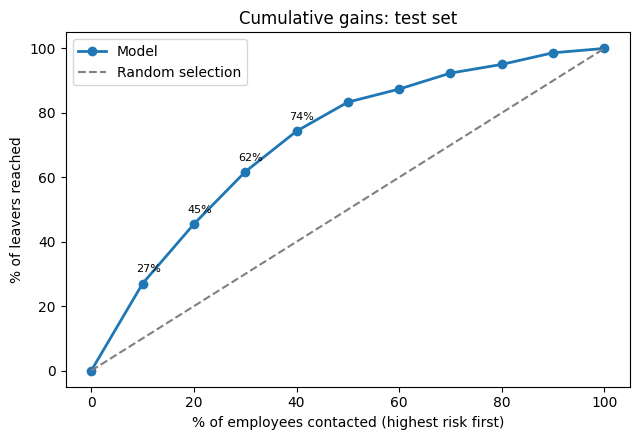

In [ ]:
'''In this analysis, firstly we rank test employees from highest predicted risk to lowest
then we split them into 10 equal groups. lastly we calculate the actual leavers
including its attrition rate, and ratio out of all leavers'''

gains = pd.DataFrame({'p': p_test, 'left': y_test.values})
gains['decile'] = pd.qcut(gains['p'].rank(method='first', ascending=False), 10, labels=range(1, 11))
decile_table = gains.groupby('decile', observed=True).agg(employees=('left', 'size'), leavers=('left', 'sum'),
                                                          attrition_rate=('left', 'mean'),
                                                          mean_predicted=('p', 'mean'))
decile_table['cumulative_share_of_leavers'] = decile_table['leavers'].cumsum() / decile_table['leavers'].sum()
decile_table['lift'] = decile_table['attrition_rate'] / y_test.mean()
display(decile_table.style.format({'attrition_rate': '{:.1%}', 'mean_predicted': '{:.1%}',
                                   'cumulative_share_of_leavers': '{:.1%}', 'lift': '{:.2f}'}))

# Cumulative gains chart
x = np.arange(0, 11) * 10
y_gain = np.r_[0, decile_table['cumulative_share_of_leavers'].values * 100]
plt.figure(figsize=(6.5, 4.5))
plt.plot(x, y_gain, marker='o', linewidth=2, label='Model')
plt.plot([0, 100], [0, 100], linestyle='--', color='grey', label='Random selection')
for xi, yi in zip(x[1:5], y_gain[1:5]):
    plt.annotate(f'{yi:.0f}%', (xi, yi), textcoords='offset points', xytext=(-5, 8), fontsize=8)
plt.xlabel('% of employees contacted (highest risk first)')
plt.ylabel('% of leavers reached')
plt.title('Cumulative gains: test set')
plt.legend()
plt.tight_layout()
plt.show()

**Finding:**

Focusing on the highest-risk fifth of employees reaches almost half of future leavers

Ranking test employees by predicted risk shows strong concentration. The top 10% had a 48.4% attrition rate, 2.7 times the average (lift 2.69), and contained 27.0% of all leavers. The top 20% contained 45.5% of leavers, the top 30% contained 61.7%, and the top 40% contained 74.3%.

At the other end, the lower-risk half of employees contained only 16.7% of leavers, and the lowest-risk 10% had an attrition rate of just 2.4%. This means retention efforts can be targeted: HR could reach nearly half of likely leavers by focusing on one in five employees (the top 20% riskiest employees).

**Are the predicted probabilities trustworthy? (calibration)**

,mean_predicted_risk,actual_attrition_rate
0,2.3%,2.4%
1,4.4%,6.5%
2,6.4%,4.9%
3,8.9%,8.9%
4,11.3%,7.3%
5,14.3%,16.1%
6,18.3%,22.8%
7,23.4%,29.0%
8,32.5%,33.3%
9,54.9%,48.4%


Brier score: 0.1272


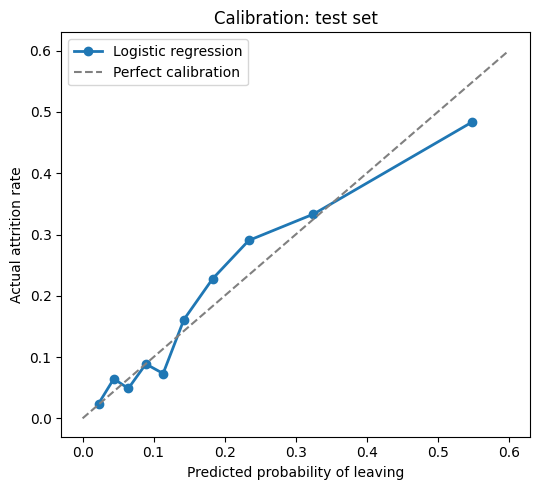

In [ ]:
prob_true, prob_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
calib_table = pd.DataFrame({'mean_predicted_risk': prob_pred, 'actual_attrition_rate': prob_true})
display(calib_table.style.format('{:.1%}'))
print(f"Brier score: {brier_score_loss(y_test, p_test):.4f}")

plt.figure(figsize=(5.5, 5))
plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label='Logistic regression')
plt.plot([0, 0.6], [0, 0.6], linestyle='--', color='grey', label='Perfect calibration')
plt.xlabel('Predicted probability of leaving')
plt.ylabel('Actual attrition rate')
plt.title('Calibration: test set')
plt.legend()
plt.tight_layout()
plt.show()

**Finding:**

The predicted probabilities are reliable and can be read as real risk levels.

Predicted risk closely matches actual attrition across the range, from 2.3% predicted vs 2.4% actual in the lowest-risk group to 32.5% vs 33.3% in the second-highest. The model slightly overestimates risk only for the highest-risk group (54.9% predicted vs 48.4% actual). With a Brier score of 0.1272, the probabilities are accurate enough to define risk tiers and to estimate costs.

**Risk tiers on the test set**

In [ ]:
'''The cut-off to create tiers is based on practical judgement where
low tier (<10%) is for employee with predicted risk well under the company's average
moderate tier (10-25%) is for employee w. predicted risk around the company average
high tier (25-40%) is for employee w. risk well above the average
and very high tier is for employee w. predicted risk more than double the company average '''

tier_bins = [0, 0.10, 0.25, 0.40, 1.0]
tier_labels = ['Low (<10%)', 'Moderate (10–25%)', 'High (25–40%)', 'Very high (≥40%)']

test_tiers = pd.DataFrame({'p': p_test, 'left': y_test.values})
test_tiers['tier'] = pd.cut(test_tiers['p'], tier_bins, labels=tier_labels)
tier_test_table = test_tiers.groupby('tier', observed=True).agg(employees=('left', 'size'),
                                                                leavers=('left', 'sum'),
                                                                actual_attrition=('left', 'mean'))
tier_test_table['share_of_employees'] = tier_test_table['employees'] / len(test_tiers)
tier_test_table['share_of_leavers'] = tier_test_table['leavers'] / tier_test_table['leavers'].sum()
display(tier_test_table.style.format({'actual_attrition': '{:.1%}', 'share_of_employees': '{:.1%}',
                                      'share_of_leavers': '{:.1%}'}))

,employees,leavers,actual_attrition,share_of_employees,share_of_leavers
tier,,,,,
Low (<10%),486,26,5.3%,39.3%,11.7%
Moderate (10–25%),474,83,17.5%,38.3%,37.4%
High (25–40%),157,55,35.0%,12.7%,24.8%
Very high (≥40%),119,58,48.7%,9.6%,26.1%


**Finding:**

Four risk tiers clearly separate low- and high-risk employees.

On the test set, actual attrition rises steadily across the four tiers: 5.3% in the Low tier (39.3% of employees), 17.5% in Moderate (38.3% of employees), 35.0% in High (12.7%) and 48.7% in Very high (9.6%). The High and Very high tiers together cover 22.3% of employees but contain about half of all leavers (24.8% + 26.1% = 50.9%).

**Who is in the high-risk tiers?**

In [ ]:
# Out-of-fold predictions: each employee is scored by a model that did NOT see them during training
model_df['risk_score'] = cross_val_predict(final_model, X, y, cv=cv, method='predict_proba')[:, 1]
model_df['risk_tier'] = pd.cut(model_df['risk_score'], tier_bins, labels=tier_labels)
print(f"Out-of-fold AUC (all {len(model_df)} employees): {roc_auc_score(y, model_df['risk_score']):.3f}")

# 1. Tier sizes and attrition across the whole workforce
tier_all = model_df.groupby('risk_tier', observed=True).agg(employees=('left', 'size'),
                                                            actual_attrition=('left', 'mean'))
tier_all['share_of_employees'] = tier_all['employees'] / len(model_df)
print("="*30, "Tier sizes and attrition across the whole workforce","="*30)
display(tier_all.style.format({'actual_attrition': '{:.1%}', 'share_of_employees': '{:.1%}'}))

# 2. What each tier looks like
profile_cols = ['burnout_score', 'engagement_score', 'manager_support_score', 'overtime_hours_per_week',
                'years_since_promotion', 'salary_hike_pct', 'perceived_ai_job_risk']
print("="*30, "Wellbeing score across different risk tiers","="*30)
display(model_df.groupby('risk_tier', observed=True)[profile_cols].mean().round(2))

# 3. Share of each department and work mode in the High + Very high tiers
model_df['high_risk'] = model_df['risk_tier'].isin(['High (25–40%)', 'Very high (≥40%)'])
for col in ['department', 'work_mode']:
    t = model_df.groupby(col).agg(employees=('left', 'size'), share_high_risk=('high_risk', 'mean'),
                                  actual_attrition=('left', 'mean')).sort_values('share_high_risk', ascending=False)
    print("="*30, f"Share of employees in High or Very high risk tiers, by {col}", "="*30)
    display(t.style.format({'share_high_risk': '{:.1%}', 'actual_attrition': '{:.1%}'}))

Out-of-fold AUC (all 4941 employees): 0.777
============================== Tier sizes and attrition across the whole workforce ==============================


,employees,actual_attrition,share_of_employees
risk_tier,,,
Low (<10%),1977,4.9%,40.0%
Moderate (10–25%),1795,17.3%,36.3%
High (25–40%),657,32.9%,13.3%
Very high (≥40%),512,51.2%,10.4%


============================== Wellbeing score across different risk tiers ==============================


,burnout_score,engagement_score,manager_support_score,overtime_hours_per_week,years_since_promotion,salary_hike_pct,perceived_ai_job_risk
risk_tier,,,,,,,
Low (<10%),2.88,7.64,7.72,5.01,1.54,12.74,4.38
Moderate (10–25%),4.23,6.27,6.35,6.83,2.02,11.21,5.00
High (25–40%),5.20,5.40,5.53,8.74,2.45,10.43,5.31
Very high (≥40%),6.27,4.41,4.68,11.36,2.85,9.30,5.62


============================== Share of employees in High or Very high risk tiers, by department ==============================


,employees,share_high_risk,actual_attrition
department,,,
Customer Support,630,39.4%,24.1%
Sales,822,26.8%,19.7%
Marketing,436,26.6%,19.0%
Finance,433,25.4%,18.2%
Human Resources,242,23.1%,18.2%
Operations,654,19.9%,17.0%
Research & Development,401,19.2%,15.2%
Engineering,1323,16.0%,14.7%


============================== Share of employees in High or Very high risk tiers, by work_mode ==============================


,employees,share_high_risk,actual_attrition
work_mode,,,
Onsite,1724,29.5%,21.2%
Hybrid,2210,21.6%,16.9%
Remote,1007,18.3%,14.7%


**Finding:**

High-risk employees share a clear profile, and are concentrated in Customer Support and onsite roles.

Scoring all 4,941 employees with out-of-fold predictions (AUC 0.777) places 13.3% of employees in the High tier (32.9% actual attrition) and 10.4% in the Very high tier (51.2% attrition rate), compared with 4.9% attrition in the Low tier (40.0% of employees).

Every warning sign rises steadily from Low to Very high risk. Compared with the Low tier, Very high-risk employees report more than double the burnout (6.27 vs 2.88), lower engagement (4.41 vs 7.64) and lower manager support (4.68 vs 7.72), work more than twice the overtime (11.4 vs 5.0 hours per week), have waited longer since promotion (2.85 vs 1.54 years), received smaller salary increases (9.3% vs 12.7%) and feel more at risk from AI (5.62 vs 4.38).

High-risk employees are most concentrated in Customer Support, where 39.4% fall in the High or Very high tiers, followed by Sales (26.8%) and Marketing (26.6%). Engineering has the lowest share (16.0%). By work mode, 29.5% of onsite employees are high risk, compared with 21.6% of hybrid and 18.3% of remote employees.

**Robustness check (flagged vs clean employees)**

In [ ]:
flag_test = hr.loc[X_test.index, 'flag_any_issue']
robust_auc = pd.DataFrame({
    'employees': [(~flag_test).sum(), flag_test.sum()],
    'test_AUC': [roc_auc_score(y_test[~flag_test], p_test[~flag_test.values]),
                 roc_auc_score(y_test[flag_test], p_test[flag_test.values])]},
    index=['Unflagged employees', 'Flagged employees']).round(3)
display(robust_auc)

,employees,test_AUC
Unflagged employees,915,0.773
Flagged employees,321,0.759


**Finding:**

The model performs consistently for employees with data-quality flags.

Test AUC is similar for unflagged employees (0.773, 915 employees) and employees flagged in the sanity check (0.759, 321 employees). The data-quality issues identified earlier do not meaningfully weaken the model's ability to identify at-risk employees.

**Conclusion - Objective 5:**

- A logistic regression model identifies at-risk employees well (test AUC 0.769; PR-AUC 0.424 vs 0.180 for random guessing) and performs as well as or better than random forest and gradient boosting, while being easier to explain.

- Accuracy is not a useful measure for this problem: predicting that nobody leaves is 82.0% accurate. Precision and recall show the real trade-off; at a 25% risk threshold, the model flags 22.3% of employees and catches half of all leavers (recall 50.9%, precision 40.9%).

- Risk is highly concentrated: the top 20% of employees by predicted risk contain 45.5% of leavers, and the top 10% leave at 2.7 times the average rate.

- The predicted probabilities are well calibrated, so they can be used as real risk levels. Four risk tiers clearly separate employees, from 4.9% attrition in the Low tier to 51.2% in the Very high tier.

- High-risk employees combine high burnout, low engagement and manager support, heavy overtime, long promotion gaps, small salary increases and higher perceived AI risk. They are most concentrated in Customer Support (39.4% high risk) and among onsite employees (29.5%).

- Results are consistent for employees with data-quality flags (AUC 0.759 vs 0.773).

**Business implications**
1. **Use the risk tiers to prioritise retention conversations.** Focusing on the High and Very high tiers (about 1 in 4 employees) reaches about half of likely leavers, making retention efforts far more efficient than broad, company-wide programmes.
2. **Set the threshold based on HR capacity.** A lower threshold catches more leavers but flags more employees; the threshold table gives HR a clear basis for this choice.
3. **Start with Customer Support and onsite teams,** where high-risk employees are most concentrated.
4. **Use risk scores to start supportive conversations, not to make decisions about individuals.** Around 6 in 10 flagged employees at the 25% threshold did not leave, so scores should prompt check-ins about workload, career progression and support, never performance or employment decisions.

**Limitations**
- The data is a single snapshot with no dates, so the model shows who is at risk at a point in time, not how far in advance it can predict an exit. Testing how "early" the warning comes would require dated data, such as monthly survey scores and exit dates.
- Several key predictors (burnout, engagement, manager support, perceived AI risk) are self-reported, and employees already planning to leave may rate their experience more negatively. Some of the model's accuracy may come from this.
- Even the best model misses about half of leavers at the 25% threshold. Many exits are driven by factors not in the data (personal circumstances, outside job offers).
- Personal characteristics (gender, age, marital status, education) were excluded from the model. Whether its predictions are equally accurate across these groups is tested later on.

## Interpret the drivers - Which factors matter most, and which can the company actually change (manager support, overtime, promotion timing) versus which company can't (age, marital status)?

**Initial Setup**

*This set up involves sorting every model feature into three groups which are 'Directly changeable', 'Influenceable', and 'Not changeable'. In this part of analysis, personal characteristics (age, marital status, gender, education) aren’t in the model in the beginning as they will be tested separately.*

In [ ]:
ref = {'work_mode': 'Hybrid', 'department': 'Engineering'}

controllability = {
    # Directly changeable: set by company decisions and policies
    'overtime_hours_per_week': 'Directly changeable',
    'years_since_promotion': 'Directly changeable',
    'salary_hike_pct': 'Directly changeable',
    'stock_option_level': 'Directly changeable',
    'monthly_income': 'Directly changeable',
    'training_hours': 'Directly changeable',
    'business_travel_days_per_year': 'Directly changeable',
    'work_mode': 'Directly changeable',
    'uses_ai': 'Directly changeable',
    # Influenceable: employee experiences the company can shape through management, workload and culture
    'burnout_score': 'Influenceable',
    'engagement_score': 'Influenceable',
    'manager_support_score': 'Influenceable',
    'work_life_balance_score': 'Influenceable',
    'perceived_ai_job_risk': 'Influenceable',
    # Not changeable (or not a retention lever)
    'years_at_company': 'Not changeable',
    'department': 'Not changeable',
    'commute_minutes': 'Not changeable',
    'performance_rating': 'Not changeable',
}

control_table = (pd.Series(controllability, name='category').rename_axis('feature').reset_index()
                 .sort_values(['category', 'feature']))
display(control_table)
display(control_table['category'].value_counts().to_frame('number_of_features'))

,feature,category
6,business_travel_days_per_year,Directly changeable
4,monthly_income,Directly changeable
0,overtime_hours_per_week,Directly changeable
2,salary_hike_pct,Directly changeable
3,stock_option_level,Directly changeable
5,training_hours,Directly changeable
8,uses_ai,Directly changeable
7,work_mode,Directly changeable
1,years_since_promotion,Directly changeable
9,burnout_score,Influenceable


,number_of_features
category,
Directly changeable,9
Influenceable,5
Not changeable,4


**Which factors have a significant independent effect? (odds ratios)**

,SD,odds_ratio (per SD),ci_low,ci_high,p_value,pct_change_per_SD,odds_ratio (per unit),pct_change_per_unit,significant,category
burnout_score,1.54,1.545,1.363,1.751,0.0000,54.5,1.326,32.6,Yes,Influenceable
manager_support_score,1.84,0.676,0.607,0.753,0.0000,-32.4,0.808,-19.2,Yes,Influenceable
years_since_promotion,1.63,1.325,1.213,1.447,0.0000,32.5,1.188,18.8,Yes,Directly changeable
engagement_score,1.50,0.772,0.681,0.876,0.0001,-22.8,0.842,-15.8,Yes,Influenceable
overtime_hours_per_week,4.48,1.223,1.095,1.365,0.0003,22.3,1.046,4.6,Yes,Directly changeable
perceived_ai_job_risk,1.83,1.181,1.075,1.296,0.0005,18.1,1.095,9.5,Yes,Influenceable
salary_hike_pct,3.41,0.867,0.791,0.950,0.0023,-13.3,0.959,-4.1,Yes,Directly changeable
years_at_company,3.51,0.853,0.763,0.954,0.0054,-14.7,0.956,-4.4,Yes,Not changeable
work_mode_Onsite,NaN,1.196,0.999,1.430,0.0508,19.6,1.196,19.6,No,Directly changeable
department_Customer Support,NaN,1.327,0.969,1.818,0.0778,32.7,1.327,32.7,No,Not changeable


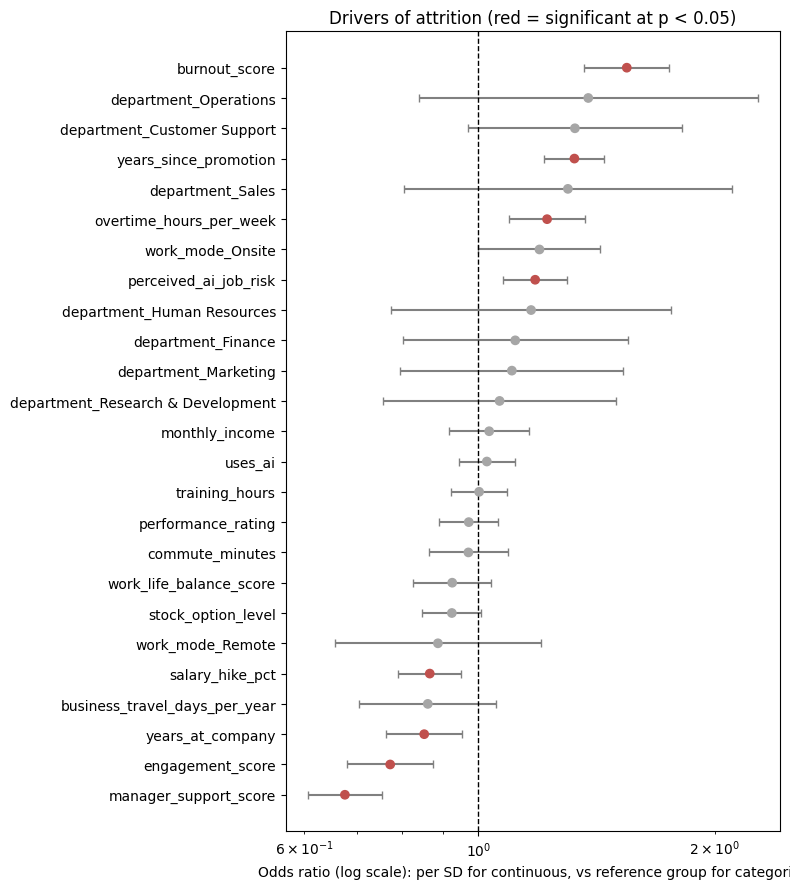

In [ ]:
m_drivers, _ = fit_model(model_df, continuous=num_features, categorical=cat_features, ref=ref)
driver_or = or_table_mixed(m_drivers, model_df, continuous=num_features)
driver_or['significant'] = np.where(driver_or['p_value'] < 0.05, 'Yes', 'No')
driver_or['category'] = [controllability.get(c, controllability.get(c.split('_')[0] + '_' + c.split('_')[1]
                                                                    if c.startswith('work_mode') else 'department'))
                         for c in driver_or.index]
driver_or = driver_or.sort_values('p_value')
display(driver_or)

# Forest plot: odds ratio per SD (continuous) or vs reference group (dummies), with 95% CI
plot_df = driver_or.sort_values('odds_ratio (per SD)')
colors = np.where(plot_df['significant'] == 'Yes', '#C0504D', '#A6A6A6')
plt.figure(figsize=(8, 9))
plt.errorbar(plot_df['odds_ratio (per SD)'], range(len(plot_df)),
             xerr=[plot_df['odds_ratio (per SD)'] - plot_df['ci_low'], plot_df['ci_high'] - plot_df['odds_ratio (per SD)']],
             fmt='none', ecolor='grey', capsize=3)
plt.scatter(plot_df['odds_ratio (per SD)'], range(len(plot_df)), color=colors, zorder=3)
plt.axvline(1, color='black', linestyle='--', linewidth=1)
plt.yticks(range(len(plot_df)), plot_df.index)
plt.xscale('log')
plt.xlabel('Odds ratio (log scale): per SD for continuous, vs reference group for categories')
plt.title('Drivers of attrition (red = significant at p < 0.05)')
plt.tight_layout()
plt.show()

**Finding:**

Eight factors independently drive attrition, led by burnout, manager support and promotion timing

Holding all other factors constant, eight factors have a significant effect on the odds of leaving (all p < 0.01):
- **Burnout:** each additional point raises the odds by 32.6% (OR 1.54 per SD).
- **Manager support:** each additional point lowers the odds by 19.2% (OR 0.68 per SD).
- **Years since promotion:** each additional year raises the odds by 18.8% (OR 1.32 per SD).
- **Engagement:** each additional point lowers the odds by 15.8% (OR 0.77 per SD).
- **Perceived AI risk:** each additional point raises the odds by 9.5% (OR 1.18 per SD).
- **Overtime:** each additional weekly hour raises the odds by 4.6% (OR 1.22 per SD).
- **Salary increase:** each additional percentage point lowers the odds by 4.1% (OR 0.87 per SD).
- **Years at company:** each additional year lowers the odds by 4.4% (OR 0.85 per SD).

Once these are taken into account, work mode (onsite p = 0.051), department (Customer Support p = 0.078), stock options (p = 0.079), work-life balance, travel, commute, income, training hours, performance rating and AI tool use have no significant independent effect.

**Which factors does the model rely on most? (permutation importance)**

,importance_mean,importance_std,category
burnout_score,0.0408,0.0092,Influenceable
manager_support_score,0.0374,0.0063,Influenceable
engagement_score,0.0236,0.0060,Influenceable
years_since_promotion,0.0192,0.0044,Directly changeable
overtime_hours_per_week,0.0078,0.0039,Directly changeable
perceived_ai_job_risk,0.0073,0.0027,Influenceable
business_travel_days_per_year,0.0056,0.0033,Directly changeable
years_at_company,0.0048,0.0036,Not changeable
salary_hike_pct,0.0036,0.0023,Directly changeable
department,0.0026,0.0020,Not changeable


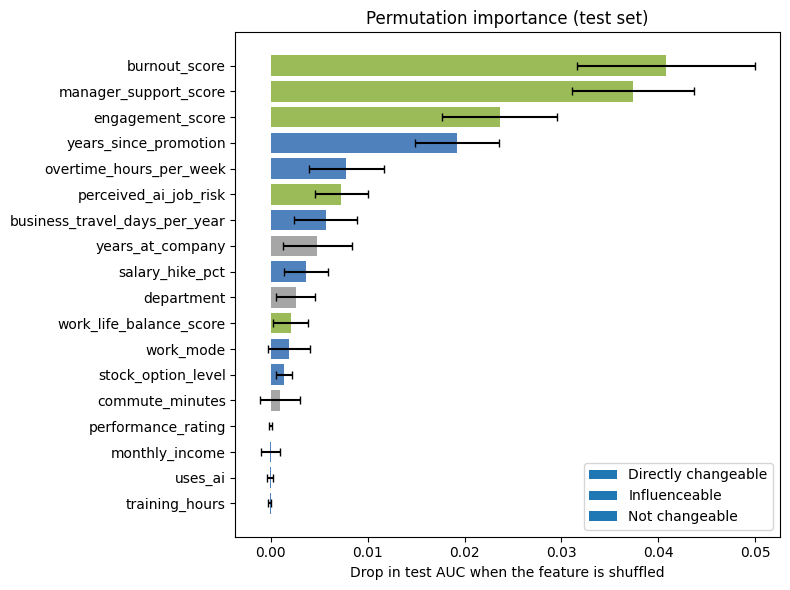

In [ ]:
perm = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=42)
perm_imp = pd.DataFrame({'importance_mean': perm.importances_mean,
                         'importance_std': perm.importances_std},
                        index=num_features + cat_features).sort_values('importance_mean', ascending=False)
perm_imp['category'] = perm_imp.index.map(controllability)
display(perm_imp.round(4))

palette = {'Directly changeable': '#4F81BD', 'Influenceable': '#9BBB59', 'Not changeable': '#A6A6A6'}
plt.figure(figsize=(8, 6))
plot_p = perm_imp.sort_values('importance_mean')
plt.barh(plot_p.index, plot_p['importance_mean'], xerr=plot_p['importance_std'],
         color=plot_p['category'].map(palette), capsize=3)
for cat_name, col in palette.items():
    plt.barh([], [], color=col, label=cat_name)
plt.xlabel('Drop in test AUC when the feature is shuffled')
plt.title('Permutation importance (test set)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Finding:**

The model relies most on burnout, manager support and engagement.

Permutation importance shows how much the model's accuracy drops when each feature is scrambled. Burnout has the largest impact (AUC drop 0.0408), followed by manager support (0.0374), engagement (0.0236) and years since promotion (0.0192). Overtime (0.0078) and perceived AI risk (0.0073) contribute less, and every other feature reduces AUC by less than 0.006. Performance rating, income, AI tool use and training hours contribute essentially nothing.

Business travel ranks seventh (0.0056) but is not significant in the full model (p = 0.145, from the previous analysis) and has a large standard deviation (0.0033), so it is not treated as a reliable driver.

**Combine both views and summarise by controllability**

*This part combines the result from the two previous analysis to determine which features are important and whether they can be controlled*

In [ ]:
# Map dummy columns back to their original feature so both tables line up
def base_feature(name):
    if name.startswith('department_'): return 'department'
    if name.startswith('work_mode_'): return 'work_mode'
    return name

or_by_feature = (driver_or.assign(feature=driver_or.index.map(base_feature))
                 .sort_values('p_value').groupby('feature').first())   # strongest level for categories
combined = perm_imp.join(or_by_feature[['odds_ratio (per SD)', 'p_value', 'pct_change_per_unit']], how='left')
combined['key_driver'] = np.where(combined['p_value'] < 0.05, 'Yes', 'No')
display(combined[['category', 'importance_mean', 'odds_ratio (per SD)', 'pct_change_per_unit',
                  'p_value', 'key_driver']].round(4))

# Summary by controllability category
print("="*30 , 'Summary by controllability category' , "="*30)
summary_cat = combined.groupby('category').agg(
    features=('importance_mean', 'size'),
    key_drivers=('key_driver', lambda s: (s == 'Yes').sum()),
    total_importance=('importance_mean', lambda s: s.clip(lower=0).sum()))
summary_cat['share_of_total_importance'] = summary_cat['total_importance'] / summary_cat['total_importance'].sum()
display(summary_cat.style.format({'total_importance': '{:.4f}', 'share_of_total_importance': '{:.1%}'}))

print("Key drivers by category:")
for cat_name, g in combined[combined['key_driver'] == 'Yes'].groupby('category'):
    print(f"  {cat_name}: {', '.join(g.index)}")


# Share of total importance from the key drivers, grouped by whether the company can act on them
print("="*30 , 'Share of total importance from the key drivers, grouped by whether the company can act on them' , "="*30)
imp_pos = combined['importance_mean'].clip(lower=0)
total_imp = imp_pos.sum()
key = combined['key_driver'] == 'Yes'
changeable = combined['category'].isin(['Directly changeable', 'Influenceable'])

key_share = pd.DataFrame({
    'features': [int((key & changeable).sum()), int((key & ~changeable).sum()), int(key.sum()),
                 int(changeable.sum())],
    'share_of_total_importance': [imp_pos[key & changeable].sum() / total_imp,
                                  imp_pos[key & ~changeable].sum() / total_imp,
                                  imp_pos[key].sum() / total_imp,
                                  imp_pos[changeable].sum() / total_imp]},
    index=['Key drivers the company can change or influence',
           'Key drivers the company cannot change',
           'All key drivers',
           'All changeable or influenceable features (incl. non-significant)'])
display(key_share.style.format({'share_of_total_importance': '{:.1%}'}))

,category,importance_mean,odds_ratio (per SD),pct_change_per_unit,p_value,key_driver
burnout_score,Influenceable,0.0408,1.545,32.6,0.0000,Yes
manager_support_score,Influenceable,0.0374,0.676,-19.2,0.0000,Yes
engagement_score,Influenceable,0.0236,0.772,-15.8,0.0001,Yes
years_since_promotion,Directly changeable,0.0192,1.325,18.8,0.0000,Yes
overtime_hours_per_week,Directly changeable,0.0078,1.223,4.6,0.0003,Yes
perceived_ai_job_risk,Influenceable,0.0073,1.181,9.5,0.0005,Yes
business_travel_days_per_year,Directly changeable,0.0056,0.862,-1.8,0.1450,No
years_at_company,Not changeable,0.0048,0.853,-4.4,0.0054,Yes
salary_hike_pct,Directly changeable,0.0036,0.867,-4.1,0.0023,Yes
department,Not changeable,0.0026,1.327,32.7,0.0778,No


============================== Summary by controllability category ==============================


,features,key_drivers,total_importance,share_of_total_importance
category,,,,
Directly changeable,9,3,0.0395,24.9%
Influenceable,5,4,0.1112,69.9%
Not changeable,4,1,0.0083,5.2%


Key drivers by category:
  Directly changeable: years_since_promotion, overtime_hours_per_week, salary_hike_pct
  Influenceable: burnout_score, manager_support_score, engagement_score, perceived_ai_job_risk
  Not changeable: years_at_company
============================== Share of total importance from the key drivers, grouped by whether the company can act on them ==============================


,features,share_of_total_importance
Key drivers the company can change or influence,7,87.9%
Key drivers the company cannot change,1,3.0%
All key drivers,8,90.9%
All changeable or influenceable features (incl. non-significant),14,94.8%


**Finding:**

Seven of the eight key drivers are factors the company can change or influence.

Of the eight significant drivers, four are influenceable (burnout, manager support, engagement and perceived AI risk), three are directly changeable (years since promotion, overtime and salary increase), and only one is not changeable (years at company).

Influenceable factors account for about 69.9% of the model's total permutation importance, directly changeable factors for 24.9%, and non-changeable factors for only 5.2%.

The seven changeable or influenceable key drivers alone account for 87.9% of total importance, compared with 3.0% for tenure. Because correlated features share importance, these shares are approximate, but they show that the model's predictive power comes overwhelmingly from factors within the company's reach.

**How much does each group of factors contribute?**

In [ ]:
def build_pipe(num_cols, cat_cols):
    return Pipeline([('pre', ColumnTransformer([
                        ('num', StandardScaler(), num_cols),
                        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])),
                     ('clf', LogisticRegression(max_iter=2000))])

feature_groups = {
    'Wellbeing': ['burnout_score', 'engagement_score', 'manager_support_score',
                  'work_life_balance_score', 'overtime_hours_per_week'],
    'Pay & career': ['years_since_promotion', 'salary_hike_pct', 'stock_option_level',
                     'monthly_income', 'training_hours'],
    'AI': ['perceived_ai_job_risk', 'uses_ai'],
    'Work arrangements': ['commute_minutes', 'business_travel_days_per_year', 'work_mode'],
    'Structural / tenure': ['department', 'years_at_company', 'performance_rating'],
}

full_cv_auc = cross_val_score(build_pipe(num_features, cat_features), X, y, cv=cv, scoring='roc_auc').mean()
rows = []
for group, cols in feature_groups.items():
    n_without = [c for c in num_features if c not in cols]
    c_without = [c for c in cat_features if c not in cols]
    auc_without = cross_val_score(build_pipe(n_without, c_without), X[n_without + c_without], y,
                                  cv=cv, scoring='roc_auc').mean()
    n_only = [c for c in num_features if c in cols]
    c_only = [c for c in cat_features if c in cols]
    auc_alone = cross_val_score(build_pipe(n_only, c_only), X[n_only + c_only], y,
                                cv=cv, scoring='roc_auc').mean()
    rows.append({'group': group, 'features': len(cols), 'CV AUC: group alone': auc_alone,
                 'CV AUC: all except this group': auc_without,
                 'AUC lost without this group': full_cv_auc - auc_without})

group_table = pd.DataFrame(rows).set_index('group').sort_values('AUC lost without this group', ascending=False)
print(f"CV AUC with all features: {full_cv_auc:.4f}")
display(group_table.round(4))

CV AUC with all features: 0.7772


,features,CV AUC: group alone,CV AUC: all except this group,AUC lost without this group
group,,,,
Wellbeing,5,0.7619,0.6585,0.1186
Pay & career,5,0.6182,0.7634,0.0138
AI,2,0.5671,0.7766,0.0006
Work arrangements,3,0.5475,0.7773,-0.0001
Structural / tenure,3,0.6103,0.7777,-0.0006


**Finding:**

Wellbeing is by far the most important group of factors, with pay and career adding a smaller distinct contribution.

Using only the five wellbeing factors, the model achieves a cross-validated AUC of 0.762, almost matching the full model (0.777). Removing wellbeing reduces AUC to 0.659, a loss of 0.119 that no other group can make up.

Pay and career factors are much weaker on their own (AUC 0.618) but add a genuine unique contribution: removing them reduces AUC by 0.014. AI factors (0.001), work arrangements (0.000) and structural factors (−0.001) add almost nothing beyond what the other groups already capture.

**Do the factors the company can’t change (age, marital status) matter?**

In [ ]:
model_df['age_group'] = pd.cut(model_df['age'], [0, 29, 39, 49, 100], labels=['<30', '30–39', '40–49', '50+'])

# 1. Attrition by personal characteristic, with chi-square tests
personal = ['age_group', 'marital_status', 'gender', 'education_level']
test_rows = []
for col in personal:
    ct = pd.crosstab(model_df[col], model_df['left'])
    chi2_stat, p_val, dof, _ = chi2_contingency(ct)
    print("="*30,f"Attrition by {col}","="*30)
    display(model_df.groupby(col, observed=True)['left'].agg(employees='count', attrition_rate='mean')
            .style.format({'attrition_rate': '{:.1%}'}))
    test_rows.append({'characteristic': col, 'chi2': round(chi2_stat, 2), 'dof': dof, 'p_value': round(p_val, 4),
                      'significant': 'Yes' if p_val < 0.05 else 'No'})
print("="*30,f"Attrition rate difference test by group","="*30)
display(pd.DataFrame(test_rows).set_index('characteristic'))

# 2. Would adding them improve the model?
m_base, _ = fit_model(model_df, continuous=num_features, categorical=cat_features, ref=ref)
add_rows = []
for label, extra_num, extra_cat in [('+ age', ['age'], []),
                                    ('+ marital status', [], ['marital_status']),
                                    ('+ age, marital status, gender, education', ['age'],
                                     ['marital_status', 'gender', 'education_level'])]:
    m_ext, _ = fit_model(model_df, continuous=num_features + extra_num,
                         categorical=cat_features + extra_cat, ref=ref)
    lr_stat = 2 * (m_ext.llf - m_base.llf)
    added = len(m_ext.params) - len(m_base.params)
    cv_auc = cross_val_score(build_pipe(num_features + extra_num, cat_features + extra_cat),
                             model_df[num_features + extra_num + cat_features + extra_cat], y,
                             cv=cv, scoring='roc_auc').mean()
    add_rows.append({'model': label, 'LR chi2': round(lr_stat, 2), 'added parameters': added,
                     'LR p_value': round(chi2.sf(lr_stat, added), 4), 'CV AUC': round(cv_auc, 4),
                     'CV AUC (final model)': round(full_cv_auc, 4)})
print("="*30,f"Likelihood Ratio Test (Models Comparison)","="*30)
display(pd.DataFrame(add_rows).set_index('model'))

============================== Attrition by age_group ==============================


,employees,attrition_rate
age_group,,
<30,924,19.4%
30–39,2143,18.2%
40–49,1523,17.4%
50+,351,14.8%


============================== Attrition by marital_status ==============================


,employees,attrition_rate
marital_status,,
Divorced,538,18.6%
Married,2357,18.0%
Single,2046,17.6%


============================== Attrition by gender ==============================


...

,employees,attrition_rate
education_level,,
Bachelors,2526,18.6%
High School,507,18.5%
Masters,1518,16.7%
PhD,390,17.9%


============================== Attrition rate difference test by group ==============================


,chi2,dof,p_value,significant
characteristic,,,,
age_group,4.02,3,0.2597,No
marital_status,0.29,2,0.8659,No
gender,1.59,3,0.6620,No
education_level,2.47,3,0.4805,No


============================== Likelihood Ratio Test (Models Comparison) ==============================


,LR chi2,added parameters,LR p_value,CV AUC,CV AUC (final model)
model,,,,,
+ age,0.02,1,0.8861,0.7767,0.7772
+ marital status,0.29,2,0.8644,0.7764,0.7772
"+ age, marital status, gender, education",6.41,9,0.6980,0.7746,0.7772


**Finding:**

Personal characteristics the company cannot change are not linked to attrition.

None of the personal characteristics show a significant relationship with attrition: age group (14.8% for employees aged 50+ to 19.4% for those under 30; p = 0.26), marital status (17.6%–18.6%; p = 0.87), gender (13.3%–18.2%; p = 0.66) and education (16.7%–18.6%; p = 0.48).

Adding them to the model does not improve it: likelihood-ratio tests show no improvement for age (p = 0.89), marital status (p = 0.86) or all four together (p = 0.70), and cross-validated AUC slightly decreases (0.775–0.777 vs 0.777). Excluding them from the model therefore costs no predictive accuracy while avoiding risk scores based on personal characteristics.

**Conclusion - Objective 6:**

- Eight factors independently drive attrition. The strongest are burnout (+32.6% odds per point), manager support (−19.2% per point), years since promotion (+18.8% per year) and engagement (−15.8% per point), followed by perceived AI risk, overtime, salary increase and tenure.

- The model relies most heavily on burnout, manager support and engagement; together with years since promotion, these four features account for most of its predictive power.

- Seven of the eight key drivers are within the company's control: four are influenceable (burnout, manager support, engagement, perceived AI risk) and three are directly changeable (years since promotion, overtime, salary increase). These account for about 95% of the model's predictive power; tenure is the only non-changeable driver.

- Wellbeing is the dominant group of factors: on its own it nearly matches the full model (CV AUC 0.762 vs 0.777). Pay and career factors add a smaller but distinct contribution (0.014 AUC).

- Factors the company cannot change, such as age and marital status, are not linked to attrition and add nothing to the model. Excluding them costs no accuracy.

**Business implications**
1. **Focus retention efforts on wellbeing.** Reducing burnout and strengthening engagement and manager support offer the largest potential impact, since they are both the strongest drivers and the largest source of the model's predictive power.
2. **Invest in managers.** Manager support is the strongest protective factor (−19.2% odds per point). Manager training, regular one-to-ones and including team wellbeing in manager performance goals are practical ways to act on it.
3. **Review promotion timing and workload as direct levers.** Years since promotion and overtime are the strongest drivers the company controls directly. Flagging employees approaching long promotion gaps, and monitoring sustained overtime, gives HR concrete actions.
4. **Address AI-related job anxiety** through clear communication about how roles will change and reskilling opportunities.
5. **Keep personal characteristics out of attrition models.** They are not linked to attrition here, so excluding them is both fairer and costs nothing.

**Limitations**
- The data is a single snapshot, so these are associations, not proven causes. Reducing a driver will not necessarily reduce attrition by the amount the odds ratio suggests.
- The controllability classification is a judgement-based framework. Some factors (e.g. manager support, perceived AI risk) could reasonably be placed in a different category.
- Permutation importance shares are approximate, because correlated features (e.g. burnout and engagement) share predictive power.
- Several key drivers are self-reported, and employees already planning to leave may rate their experience more negatively.
- Personal characteristics showing no link with attrition does not guarantee the model is equally accurate across these groups; this is tested in B8.

## Business impact - What is the cost of attrition, and what would an intervention save?

**Initial setup (Set out the cost assumptions)**

In [ ]:
model_df['annual_salary'] = model_df['monthly_income'] * 12

replacement_scenarios = {'Low (30%)': 0.30, 'Base (50%)': 0.50, 'High (100%)': 1.00}
BASE_RATE = replacement_scenarios['Base (50%)']

assumptions = pd.DataFrame({
    'value': ['Salaries treated as AUD (no currency in dataset)',
              'monthly_income × 12',
              'Low 30% / Base 50% / High 100% of annual salary',
              'One observation period (assumed 12 months, as in 1st part of analysis)',
              f"{len(model_df):,} employees (59 impossible-tenure rows excluded, as in B5)"]},
    index=['Currency', 'Annual salary', 'Replacement cost per leaver', 'Time period', 'Population'])
display(assumptions)

salary_summary = pd.DataFrame({
    'employees': [len(model_df), int(model_df['left'].sum())],
    'mean_annual_salary': [model_df['annual_salary'].mean(),
                           model_df.loc[model_df['left'] == 1, 'annual_salary'].mean()],
    'total_annual_salary': [model_df['annual_salary'].sum(),
                            model_df.loc[model_df['left'] == 1, 'annual_salary'].sum()]},
    index=['All employees', 'Leavers'])
display(salary_summary.style.format({'mean_annual_salary': '${:,.0f}', 'total_annual_salary': '${:,.0f}'}))

,value
Currency,Salaries treated as AUD (no currency in dataset)
Annual salary,monthly_income × 12
Replacement cost per leaver,Low 30% / Base 50% / High 100% of annual salary
Time period,"One observation period (assumed 12 months, as ..."
Population,"4,941 employees (59 impossible-tenure rows exc..."


,employees,mean_annual_salary,total_annual_salary
All employees,4941,"$84,002","$415,053,192"
Leavers,886,"$80,050","$70,924,356"


**Finding:**

Cost estimates rely on two key assumptions: salary currency and replacement cost.

The analysis covers 4,941 employees, of whom 886 left. Average annual salary is 84,000 dollar across all employees and 80,000 dollar among leavers, with a total payroll of $415.1 million.

Because the dataset has no currency, salaries are treated as AUD. Replacing a leaver is assumed to cost 50% of their annual salary in the base case, a conservative assumption within commonly cited practitioner ranges, with 30% and 100% scenarios used to test sensitivity.

**The current cost of attrition**

============================== Total cost under each replacement-cost scenario ==============================


,total_cost,cost_per_leaver,pct_of_payroll
scenario,,,
Low (30%),"$21,277,307","$24,015",5.13%
Base (50%),"$35,462,178","$40,025",8.54%
High (100%),"$70,924,356","$80,050",17.09%


============================== Cost by department (base case) ==============================


,employees,leavers,attrition_rate,mean_salary,attrition_cost,share_of_cost,cost_per_employee
department,,,,,,,
Engineering,1323,194,14.7%,"$97,632","$9,349,776",26.4%,"$7,067"
Sales,822,162,19.7%,"$82,104","$6,282,420",17.7%,"$7,643"
Customer Support,630,152,24.1%,"$66,465","$4,981,746",14.0%,"$7,908"
Operations,654,111,17.0%,"$79,517","$4,311,150",12.2%,"$6,592"
Finance,433,79,18.2%,"$83,759","$3,294,354",9.3%,"$7,608"
Marketing,436,83,19.0%,"$79,295","$3,174,486",9.0%,"$7,281"
Research & Development,401,61,15.2%,"$89,998","$2,539,626",7.2%,"$6,333"
Human Resources,242,44,18.2%,"$72,684","$1,528,620",4.3%,"$6,317"


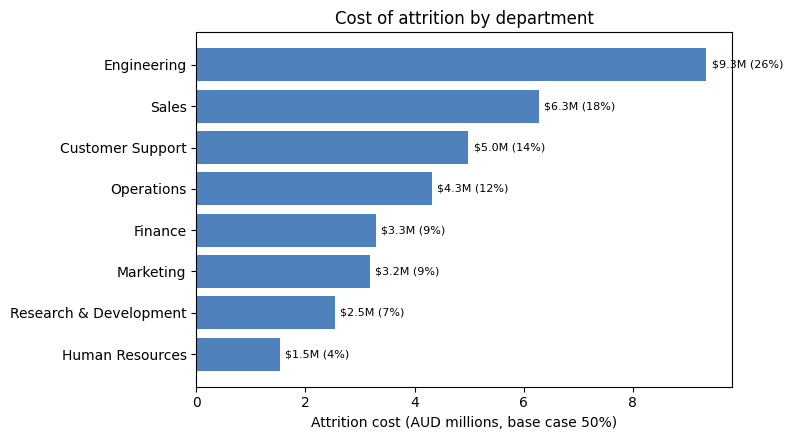

In [ ]:
leavers = model_df[model_df['left'] == 1]
payroll = model_df['annual_salary'].sum()

# 1. Total cost under each replacement-cost scenario
print("="*30,f"Total cost under each replacement-cost scenario","="*30)
cost_rows = []
for name, rate in replacement_scenarios.items():
    total = (leavers['annual_salary'] * rate).sum()
    cost_rows.append({'scenario': name, 'total_cost': total, 'cost_per_leaver': total / len(leavers),
                      'pct_of_payroll': total / payroll})
cost_table = pd.DataFrame(cost_rows).set_index('scenario')
display(cost_table.style.format({'total_cost': '${:,.0f}', 'cost_per_leaver': '${:,.0f}',
                                 'pct_of_payroll': '{:.2%}'}))

# 2. Cost by department (base case)
print("="*30,f"Cost by department (base case)","="*30)
dept_cost = model_df.groupby('department').agg(employees=('left', 'size'), leavers=('left', 'sum'),
                                               attrition_rate=('left', 'mean'),
                                               mean_salary=('annual_salary', 'mean'))
dept_cost['attrition_cost'] = leavers.groupby('department')['annual_salary'].sum() * BASE_RATE
dept_cost['share_of_cost'] = dept_cost['attrition_cost'] / dept_cost['attrition_cost'].sum()
dept_cost['cost_per_employee'] = dept_cost['attrition_cost'] / dept_cost['employees']
dept_cost = dept_cost.sort_values('attrition_cost', ascending=False)
display(dept_cost.style.format({'attrition_rate': '{:.1%}', 'mean_salary': '${:,.0f}',
                                'attrition_cost': '${:,.0f}', 'share_of_cost': '{:.1%}',
                                'cost_per_employee': '${:,.0f}'}))

plt.figure(figsize=(8, 4.5))
plt.barh(dept_cost.index[::-1], dept_cost['attrition_cost'][::-1] / 1e6, color='#4F81BD')
for i, (v, s) in enumerate(zip(dept_cost['attrition_cost'][::-1] / 1e6, dept_cost['share_of_cost'][::-1])):
    plt.text(v + 0.1, i, f'${v:.1f}M ({s:.0%})', va='center', fontsize=8)
plt.xlabel('Attrition cost (AUD millions, base case 50%)')
plt.title('Cost of attrition by department')
plt.tight_layout()
plt.show()

**Finding:**

Attrition costs an estimated \$35.5 million per year, about 8.5% of payroll.

Under the base-case assumption, attrition costs an estimated `$35.5` million over the observation period, or `$40,025` per leaver, equivalent to 8.54% of total payroll. The estimate ranges from `$21.3` million (5.13% of payroll) if replacement costs are 30% of salary to `$70.9` million (17.09%) if they are 100%.

Engineering has the highest total attrition cost (`$9.35` million, 26.4% of the total) despite the lowest attrition rate (14.7%), because it is the largest and best-paid department (1,323 employees, average salary `$97,632`). Sales (`$6.28` million, 17.7%) and Customer Support (`$4.98` million, 14.0%) follow. Customer Support has the highest cost relative to its size (`$7,908` per employee), reflecting its high attrition rate (24.1%).

**Where is the expected cost concentrated? (by risk tier)**

,employees,expected_leavers,actual_leavers,expected_cost,share_of_employees,share_of_expected_cost
risk_tier,,,,,,
Low (<10%),"1,977",107.5,97,"$4,689,144",40.0%,13.2%
Moderate (10–25%),"1,795",290.1,311,"$11,979,877",36.3%,33.8%
High (25–40%),657,207.0,216,"$8,255,448",13.3%,23.3%
Very high (≥40%),512,282.0,262,"$10,541,833",10.4%,29.7%
High + Very high,"1,169",489.0,478,"$18,797,281",23.7%,53.0%


Total expected leavers: 886.7 (actual: 886)
Total expected cost (base case): $35,466,302


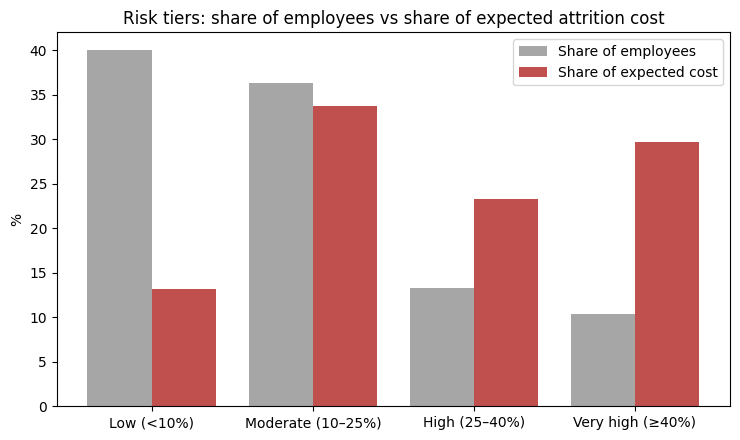

In [ ]:
# Expected cost for each employee = probability of leaving × annual salary × replacement %
model_df['expected_cost'] = model_df['risk_score'] * model_df['annual_salary'] * BASE_RATE

tier_cost = model_df.groupby('risk_tier', observed=True).agg(employees=('left', 'size'),
                                                             expected_leavers=('risk_score', 'sum'),
                                                             actual_leavers=('left', 'sum'),
                                                             expected_cost=('expected_cost', 'sum'))
tier_cost['share_of_employees'] = tier_cost['employees'] / len(model_df)
tier_cost['share_of_expected_cost'] = tier_cost['expected_cost'] / tier_cost['expected_cost'].sum()

high_rows = tier_cost.loc[['High (25–40%)', 'Very high (≥40%)']]
tier_cost.loc['High + Very high'] = [high_rows['employees'].sum(), high_rows['expected_leavers'].sum(),
                                     high_rows['actual_leavers'].sum(), high_rows['expected_cost'].sum(),
                                     high_rows['share_of_employees'].sum(), high_rows['share_of_expected_cost'].sum()]
display(tier_cost.style.format({'employees': '{:,.0f}', 'expected_leavers': '{:,.1f}', 'actual_leavers': '{:,.0f}',
                                'expected_cost': '${:,.0f}', 'share_of_employees': '{:.1%}',
                                'share_of_expected_cost': '{:.1%}'}))
print(f"Total expected leavers: {model_df['risk_score'].sum():,.1f} (actual: {int(model_df['left'].sum())})")
print(f"Total expected cost (base case): ${model_df['expected_cost'].sum():,.0f}")

# Share of employees vs share of expected cost
plot_t = tier_cost.drop(index='High + Very high')
x = np.arange(len(plot_t))
plt.figure(figsize=(7.5, 4.5))
plt.bar(x - 0.2, plot_t['share_of_employees'] * 100, width=0.4, label='Share of employees', color='#A6A6A6')
plt.bar(x + 0.2, plot_t['share_of_expected_cost'] * 100, width=0.4, label='Share of expected cost', color='#C0504D')
plt.xticks(x, plot_t.index)
plt.ylabel('%')
plt.title('Risk tiers: share of employees vs share of expected attrition cost')
plt.legend()
plt.tight_layout()
plt.show()

**Finding:**

About a quarter of employees account for over half of expected attrition cost.

Using each employee's predicted probability of leaving, the model expects 886.7 leavers (vs 886 actual) and an expected cost of $35.47 million, matching the actual cost estimate and confirming the risk scores are well calibrated.

Expected cost is heavily concentrated. Employees in the High and Very high risk tiers make up 23.7% of the workforce but account for 53.0% of expected attrition cost ($18.8 million). The Very high tier alone (10.4% of employees) accounts for 29.7%, while the Low tier (40.0% of employees) accounts for only 13.2% share of expected cost.

**What would interventions save? (scenario simulation)**

Baseline expected leavers (simulation model): 886.2; in High + Very high tiers: 486.2


,scenario,scope,employees_in_scope,employees_changed,leavers_avoided,savings_base_case,break_even_cost_per_employee
0,Burnout −1 point,High + Very high risk,1169,1169,70.8,"$2,747,860","$2,351"
1,Burnout −1 point,Everyone,4941,4830,155.8,"$6,318,181","$1,279"
2,Manager support +1 point,High + Very high risk,1169,1165,53.6,"$2,081,601","$1,781"
3,Manager support +1 point,Everyone,4941,4753,117.9,"$4,785,575",$969
4,Engagement +1 point,High + Very high risk,1169,1169,44.0,"$1,707,149","$1,460"
5,Engagement +1 point,Everyone,4941,4897,99.0,"$4,017,184",$813
6,Overtime capped at 10 hrs/week,High + Very high risk,1169,483,23.8,"$932,648",$798
7,Overtime capped at 10 hrs/week,Everyone,4941,970,31.0,"$1,253,274",$254
8,Promotion gap capped at 3 years,High + Very high risk,1169,393,26.4,"$1,183,431","$1,012"
9,Promotion gap capped at 3 years,Everyone,4941,1020,40.0,"$1,822,625",$369


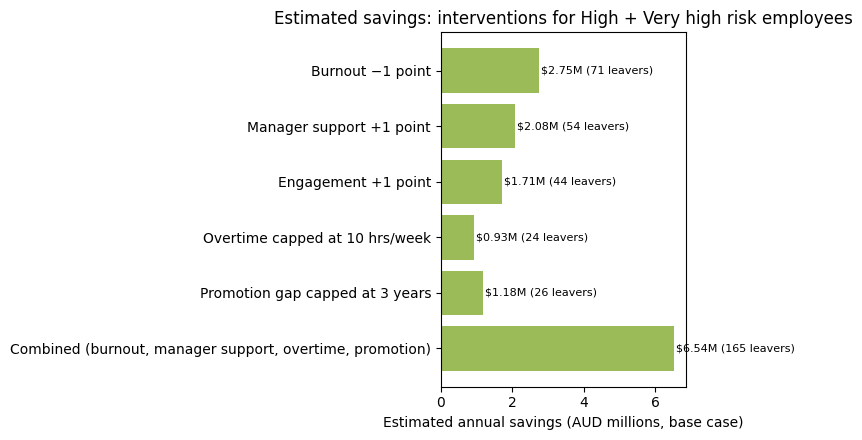

In [ ]:
# Model refitted on all employees, used to simulate "what if" changes
sim_model = build_pipe(num_features, cat_features).fit(X, y)
p_base = sim_model.predict_proba(X)[:, 1]
salary = model_df['annual_salary'].values
target_mask = model_df['high_risk'].values                 # High + Very high tiers from B5
everyone_mask = np.ones(len(model_df), dtype=bool)

def burnout_down(x):   x = x.copy(); x['burnout_score'] = (x['burnout_score'] - 1).clip(lower=1); return x
def manager_up(x):     x = x.copy(); x['manager_support_score'] = (x['manager_support_score'] + 1).clip(upper=10); return x
def engagement_up(x):  x = x.copy(); x['engagement_score'] = (x['engagement_score'] + 1).clip(upper=10); return x
def overtime_cap(x):   x = x.copy(); x['overtime_hours_per_week'] = x['overtime_hours_per_week'].clip(upper=10); return x
def promotion_cap(x):  x = x.copy(); x['years_since_promotion'] = x['years_since_promotion'].clip(upper=3); return x
def combined(x):       return promotion_cap(overtime_cap(manager_up(burnout_down(x))))

scenarios = {
    'Burnout −1 point': burnout_down,
    'Manager support +1 point': manager_up,
    'Engagement +1 point': engagement_up,
    'Overtime capped at 10 hrs/week': overtime_cap,
    'Promotion gap capped at 3 years': promotion_cap,
    'Combined (burnout, manager support, overtime, promotion)': combined,
}

def run_scenario(change_fn, mask):
    X_new = X.copy()
    X_new.loc[mask] = change_fn(X_new.loc[mask])
    p_new = sim_model.predict_proba(X_new)[:, 1]
    avoided = (p_base - p_new)[mask]
    changed = int((X_new.loc[mask] != X.loc[mask]).any(axis=1).sum())
    return changed, avoided.sum(), (avoided * salary[mask]).sum() * BASE_RATE

rows = []
for name, fn in scenarios.items():
    for scope, mask in [('High + Very high risk', target_mask), ('Everyone', everyone_mask)]:
        changed, avoided, savings = run_scenario(fn, mask)
        rows.append({'scenario': name, 'scope': scope, 'employees_in_scope': int(mask.sum()),
                     'employees_changed': changed, 'leavers_avoided': avoided,
                     'savings_base_case': savings, 'break_even_cost_per_employee': savings / mask.sum()})
scenario_table = pd.DataFrame(rows)
print(f"Baseline expected leavers (simulation model): {p_base.sum():,.1f}; "
      f"in High + Very high tiers: {p_base[target_mask].sum():,.1f}")
display(scenario_table.style.format({'leavers_avoided': '{:.1f}', 'savings_base_case': '${:,.0f}',
                                     'break_even_cost_per_employee': '${:,.0f}'}))

# Chart: savings per scenario, targeted group
plot_s = scenario_table[scenario_table['scope'] == 'High + Very high risk'].set_index('scenario')
plt.figure(figsize=(8, 4.5))
plt.barh(plot_s.index[::-1], plot_s['savings_base_case'][::-1] / 1e6, color='#9BBB59')
for i, (v, l) in enumerate(zip(plot_s['savings_base_case'][::-1] / 1e6, plot_s['leavers_avoided'][::-1])):
    plt.text(v + 0.05, i, f'${v:.2f}M ({l:.0f} leavers)', va='center', fontsize=8)
plt.xlabel('Estimated annual savings (AUD millions, base case)')
plt.title('Estimated savings: interventions for High + Very high risk employees')
plt.tight_layout()
plt.show()

**Finding:**

Modest improvements in key drivers for high-risk employees could save millions per year.

Simulating changes to the key drivers identified in previous analysis for the 1,169 employees in the High and Very high risk tiers shows (base case 50%):

- **Reducing burnout by 1 point** would avoid about 70.8 leavers and save $2.75 million per year.

- **Increasing manager support by 1 point** would avoid 53.6 leavers ($2.08 million).

- **Increasing engagement by 1 point** would avoid 44.0 leavers ($1.71 million).

- **Capping the promotion gap at 3 years** (affecting 393 employees) would avoid 26.4 leavers ($1.18 million).

- **Capping overtime at 10 hours per week** (affecting 483 employees) would avoid 23.8 leavers ($0.93 million).

A combined package (burnout, manager support, overtime and promotion) would avoid about 165.3 leavers, roughly a third of the 486.2 expected among this group, and save `$6.54` million per year. It would pay for itself at a cost of up to $5,595 per employee. These estimates assume the drivers affect attrition by the amount the model predicts.

**Is targeting worth it? (Targeted vs company-wide)**

In [ ]:
targeting = scenario_table[scenario_table['scenario'].str.startswith('Combined')].set_index('scope')
targeting['share_of_employees'] = targeting['employees_in_scope'] / len(model_df)
targeting['share_of_company_wide_savings'] = (targeting['savings_base_case']
                                              / targeting.loc['Everyone', 'savings_base_case'])
targeting['leavers_avoided_per_100_treated'] = targeting['leavers_avoided'] / targeting['employees_in_scope'] * 100
display(targeting[['employees_in_scope', 'share_of_employees', 'leavers_avoided', 'savings_base_case',
                   'share_of_company_wide_savings', 'leavers_avoided_per_100_treated',
                   'break_even_cost_per_employee']]
        .style.format({'share_of_employees': '{:.1%}', 'leavers_avoided': '{:.1f}',
                       'savings_base_case': '${:,.0f}', 'share_of_company_wide_savings': '{:.1%}',
                       'leavers_avoided_per_100_treated': '{:.1f}',
                       'break_even_cost_per_employee': '${:,.0f}'}))

,employees_in_scope,share_of_employees,leavers_avoided,savings_base_case,share_of_company_wide_savings,leavers_avoided_per_100_treated,break_even_cost_per_employee
scope,,,,,,,
High + Very high risk,1169,23.7%,165.3,"$6,540,695",50.4%,14.1,"$5,595"
Everyone,4941,100.0%,317.0,"$12,971,288",100.0%,6.4,"$2,625"


**Finding:**

Targeting high-risk employees delivers half the savings at a quarter of the scale.

Applying the combined package only to High and Very high risk employees (1,169 employees, 23.7% of the workforce) would deliver 50.4% of the savings from applying it to everyone (`$6.54` million vs `$12.97` million). Targeting is more than twice as efficient: it avoids 14.1 leavers per 100 employees treated, compared with 6.4 for a company-wide programme, and can justify spending up to `$5,595` per employee compared with $2,625.

**Sensitivity analysis - how much do the assumptions matter?**

,replacement_cost,effect_achieved,leavers_avoided,annual_savings,break_even_cost_per_employee
0,Low (30%),50% of model estimate,82.7,"$1,962,208","$1,679"
1,Low (30%),100% of model estimate,165.3,"$3,924,417","$3,357"
2,Base (50%),50% of model estimate,82.7,"$3,270,347","$2,798"
3,Base (50%),100% of model estimate,165.3,"$6,540,695","$5,595"
4,High (100%),50% of model estimate,82.7,"$6,540,695","$5,595"
5,High (100%),100% of model estimate,165.3,"$13,081,389","$11,190"


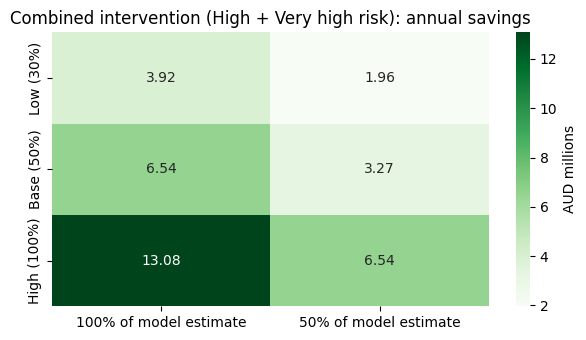

In [ ]:
_, avoided_c, savings_c_base = run_scenario(combined, target_mask)
savings_c_raw = savings_c_base / BASE_RATE        # savings before applying a replacement %

sens_rows = []
for name, rate in replacement_scenarios.items():
    for effect in [0.5, 1.0]:
        savings = savings_c_raw * rate * effect
        sens_rows.append({'replacement_cost': name,
                          'effect_achieved': f'{effect:.0%} of model estimate',
                          'leavers_avoided': avoided_c * effect,
                          'annual_savings': savings,
                          'break_even_cost_per_employee': savings / target_mask.sum()})
sens_table = pd.DataFrame(sens_rows)
display(sens_table.style.format({'leavers_avoided': '{:.1f}', 'annual_savings': '${:,.0f}',
                                 'break_even_cost_per_employee': '${:,.0f}'}))

pivot = sens_table.pivot(index='replacement_cost', columns='effect_achieved', values='annual_savings') / 1e6
pivot = pivot.loc[list(replacement_scenarios.keys())]
plt.figure(figsize=(6, 3.5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='Greens', cbar_kws={'label': 'AUD millions'})
plt.title('Combined intervention (High + Very high risk): annual savings')
plt.xlabel(''); plt.ylabel('')
plt.tight_layout()
plt.show()

**Finding:**

The business case holds even under cautious assumptions.

The savings from the combined targeted package depend on the replacement cost and how much of the predicted effect is achieved. In the most cautious scenario (replacement cost of 30% of salary, half of the predicted effect), the package would still avoid about 82.7 leavers and save `$1.96` million per year, paying for itself at up to `$1,679` per employee. Under the base-case replacement cost, savings range from `$3.27` million (half the effect) to `$6.54` million (full effect), and they reach $13.08 million in the most optimistic scenario (100% replacement cost, full effect).

**Conclusion - Objective 7:**

- Attrition costs an estimated `$35.5` million per year in the base case (50% of salary per leaver), equivalent to 8.54% of payroll, with a plausible range of `$21.3` million to `$70.9` million depending on replacement cost.

- Engineering carries the highest total cost (`$9.35` million) because of its size and salary levels, while Customer Support has the highest cost relative to its size ($7,908 per employee) because of its high attrition rate.

- Expected cost is concentrated in a small group: employees in the High and Very high risk tiers (23.7% of the workforce) account for 53.0% of expected attrition cost.

- Improving the key drivers for these employees could deliver substantial savings. Reducing burnout by 1 point alone would save an estimated `$2.75` million per year, and a combined package (burnout, manager support, overtime and promotion) would save $6.54 million and avoid about 165 leavers.

- Targeting is more than twice as efficient as a company-wide approach: it delivers 50.4% of company-wide savings while treating 23.7% of employees, and justifies up to `$5,595` per employee vs $2,625.

- The business case holds under cautious assumptions: even with a 30% replacement cost and only half the predicted effect, the targeted package would save $1.96 million per year.

**Business implications**
1. **Treat attrition as a significant financial cost.** At about 8.5% of payroll in the base case, attrition is a material business expense that justifies dedicated retention investment.
2. **Prioritise a targeted retention programme for High and Very high risk employees.** This delivers half the potential savings while involving fewer than a quarter of employees, making it the most cost-effective option.
3. **Lead with burnout reduction and manager support.** These offer the largest estimated savings per scenario (`$2.75` million and `$2.08` million) and can be addressed through workload management, manager training and regular check-ins.

4. **Use the break-even figures to evaluate programmes.** Any retention initiative for the high-risk group costing less than about `$1,679` – `$5,595` per employee (depending on assumptions) would be expected
to pay for itself.

5. **Look beyond attrition rates when allocating budget.** Engineering has the lowest attrition rate but the highest total cost, so retention spending should consider both risk and the cost of losing each employee.

**Limitations**
- Replacement cost is an assumption based on secondary, mostly US practitioner estimates; actual costs vary by role and should ideally be measured using the company's own recruitment and onboarding data.
- Salaries are treated as AUD because the dataset has no currency.
- The savings simulations assume the drivers affect attrition by the amount the model predicts, i.e. that the relationships are causal. Since the data is a single snapshot, real-world effects may be smaller; the 50%-effect scenarios provide a more cautious estimate.
- The simulations show the effect of improving drivers, not the cost or feasibility of achieving those improvements. Break-even figures show the maximum worthwhile spend, not what a programme would actually cost.
- The analysis assumes a single observation period of about 12 months, as the dataset has no dates.

## Does the model work equally well across gender and age groups?

**Initial setup (Set up groups and check sample sizes)**

In [ ]:
model_df['age_group'] = pd.cut(model_df['age'], [0, 29, 39, 49, 100], labels=['<30', '30–39', '40–49', '50+'])
model_df['flagged'] = (model_df['risk_score'] >= chosen_t).astype(int)

fair_groups = ['gender', 'age_group']
MIN_LEAVERS = 30   # groups with fewer leavers give unreliable estimates

for g in fair_groups:
    t = model_df.groupby(g, observed=True).agg(employees=('left', 'size'), leavers=('left', 'sum'),
                                               attrition_rate=('left', 'mean'))
    t['reliable_sample'] = np.where(t['leavers'] >= MIN_LEAVERS, 'Yes', 'No (small)')
    print("="*30,f"Group sizes by {g}","="*30)
    display(t.style.format({'attrition_rate': '{:.1%}'}))

============================== Group sizes by gender ==============================


,employees,leavers,attrition_rate,reliable_sample
gender,,,,
Female,2280,415,18.2%,Yes
Male,2465,441,17.9%,Yes
Non-binary,98,13,13.3%,No (small)
Prefer not to say,98,17,17.3%,No (small)


============================== Group sizes by age_group ==============================


,employees,leavers,attrition_rate,reliable_sample
age_group,,,,
<30,924,179,19.4%,Yes
30–39,2143,390,18.2%,Yes
40–49,1523,265,17.4%,Yes
50+,351,52,14.8%,Yes


**Finding:**

Most groups are large enough for reliable fairness checks, except two small gender categories.

Female (2,280 employees, 415 leavers) and male (2,465 employees, 441 leavers) employees, and all four age groups, have at least 30 leavers and are large enough for reliable comparisons. Employees aged 50+ form the smallest age group (351 employees, 52 leavers). The non-binary (98 employees, 13 leavers) and "prefer not to say" (98 employees, 17 leavers) groups are too small for reliable conclusions, so their results are treated as indicative only.

**Does the model rank risk equally well for each group? (AUC)**

In [ ]:
def bootstrap_auc(y_true, scores, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    n, aucs = len(y_true), []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].min() == y_true[idx].max():
            continue
        aucs.append(roc_auc_score(y_true[idx], scores[idx]))
    return np.percentile(aucs, [2.5, 97.5])

overall_auc = roc_auc_score(model_df['left'], model_df['risk_score'])
ov_lo, ov_hi = bootstrap_auc(model_df['left'], model_df['risk_score'])
print(f"Overall AUC: {overall_auc:.3f} (95% CI {ov_lo:.3f}–{ov_hi:.3f})")

auc_tables = {}
for g in fair_groups:
    rows = []
    for level, s in model_df.groupby(g, observed=True):
        lo, hi = bootstrap_auc(s['left'], s['risk_score'])
        rows.append({'group': level, 'leavers': int(s['left'].sum()),
                     'AUC': roc_auc_score(s['left'], s['risk_score']), 'ci_low': lo, 'ci_high': hi})
    auc_tables[g] = pd.DataFrame(rows).set_index('group')
    print("="*30, f"AUC by {g}","="*30)
    display(auc_tables[g].round(3))

# Is the gap between two groups larger than chance? (bootstrap the difference)
def bootstrap_auc_diff(df_a, df_b, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    a_y, a_p = df_a['left'].values, df_a['risk_score'].values
    b_y, b_p = df_b['left'].values, df_b['risk_score'].values
    diffs = []
    for _ in range(n_boot):
        ia, ib = rng.integers(0, len(a_y), len(a_y)), rng.integers(0, len(b_y), len(b_y))
        diffs.append(roc_auc_score(a_y[ia], a_p[ia]) - roc_auc_score(b_y[ib], b_p[ib]))
    return np.percentile(diffs, [2.5, 97.5])

comparisons = {
    'Female vs Male': (model_df[model_df['gender'] == 'Female'], model_df[model_df['gender'] == 'Male']),
    '50+ vs under 50': (model_df[model_df['age_group'] == '50+'], model_df[model_df['age_group'] != '50+']),
}
diff_rows = []
for name, (a, b) in comparisons.items():
    d = roc_auc_score(a['left'], a['risk_score']) - roc_auc_score(b['left'], b['risk_score'])
    lo, hi = bootstrap_auc_diff(a, b)
    diff_rows.append({'comparison': name, 'AUC difference': d, 'ci_low': lo, 'ci_high': hi,
                      'significant': 'Yes' if (lo > 0 or hi < 0) else 'No (CI includes 0)'})
display(pd.DataFrame(diff_rows).set_index('comparison').round(3))

Overall AUC: 0.777 (95% CI 0.760–0.792)
============================== AUC by gender ==============================


,leavers,AUC,ci_low,ci_high
group,,,,
Female,415,0.779,0.756,0.802
Male,441,0.772,0.748,0.796
Non-binary,13,0.795,0.632,0.924
Prefer not to say,17,0.813,0.689,0.917


============================== AUC by age_group ==============================


,leavers,AUC,ci_low,ci_high
group,,,,
<30,179,0.770,0.735,0.806
30–39,390,0.776,0.750,0.802
40–49,265,0.793,0.764,0.819
50+,52,0.724,0.662,0.788


,AUC difference,ci_low,ci_high,significant
comparison,,,,
Female vs Male,0.007,-0.027,0.041,No (CI includes 0)
50+ vs under 50,-0.056,-0.121,0.010,No (CI includes 0)


**Finding:**

The model ranks risk equally well for women and men, but less well for employees aged 50+.

The model's overall AUC is 0.777 (95% CI 0.760–0.792). Performance is almost identical for female (0.779) and male (0.772) employees; the difference (0.007, 95% CI −0.027 to 0.041) is consistent with chance.

Across age groups, AUC is similar for employees under 30 (0.770), aged 30–39 (0.776) and aged 40–49 (0.793), but lower for employees aged 50+ (0.724, 95% CI 0.662–0.788). The gap compared with employees under 50 (−0.056, 95% CI −0.121 to 0.010) is not quite statistically significant, but it is large enough to warrant attention. Results for the non-binary (0.795) and "prefer not to say" (0.813) groups have very wide confidence intervals because of their small size.

**Are the predicted probabilities accurate for each group? (calibration)**

============================== Calibration by gender ==============================


,employees,actual_attrition,mean_predicted_risk,predicted_to_actual_ratio,difference_pp
gender,,,,,
Female,2280,18.2%,18.2%,1.00,-0.0
Male,2465,17.9%,17.7%,0.99,-0.2
Non-binary,98,13.3%,17.8%,1.34,+4.5
Prefer not to say,98,17.3%,19.4%,1.12,+2.0


============================== Calibration by age_group ==============================


,employees,actual_attrition,mean_predicted_risk,predicted_to_actual_ratio,difference_pp
age_group,,,,,
<30,924,19.4%,19.0%,0.98,-0.3
30–39,2143,18.2%,18.5%,1.02,+0.3
40–49,1523,17.4%,16.9%,0.97,-0.5
50+,351,14.8%,16.0%,1.08,+1.2


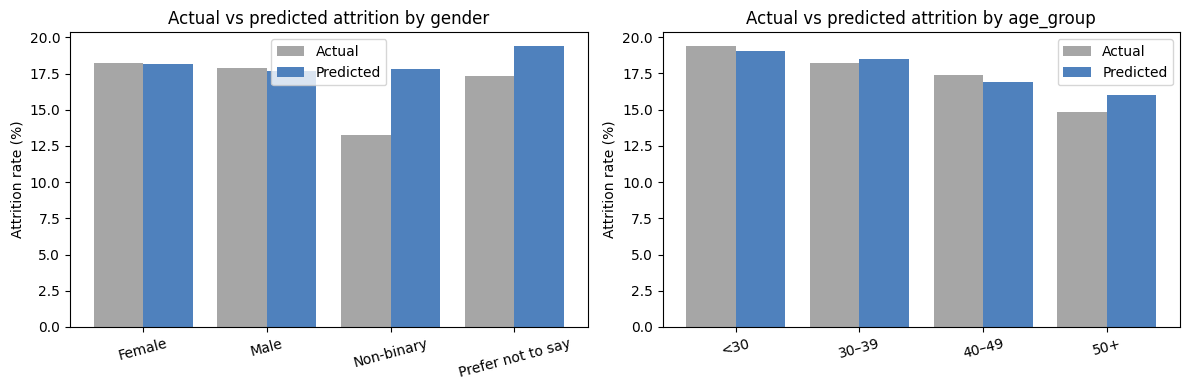

In [ ]:
calib_tables = {}
for g in fair_groups:
    c = model_df.groupby(g, observed=True).agg(employees=('left', 'size'), actual_attrition=('left', 'mean'),
                                               mean_predicted_risk=('risk_score', 'mean'))
    c['predicted_to_actual_ratio'] = c['mean_predicted_risk'] / c['actual_attrition']
    c['difference_pp'] = (c['mean_predicted_risk'] - c['actual_attrition']) * 100
    calib_tables[g] = c
    print("="*30,f"Calibration by {g}","="*30)
    display(c.style.format({'actual_attrition': '{:.1%}', 'mean_predicted_risk': '{:.1%}',
                            'predicted_to_actual_ratio': '{:.2f}', 'difference_pp': '{:+.1f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, fair_groups):
    c = calib_tables[g]
    x = np.arange(len(c))
    ax.bar(x - 0.2, c['actual_attrition'] * 100, width=0.4, label='Actual', color='#A6A6A6')
    ax.bar(x + 0.2, c['mean_predicted_risk'] * 100, width=0.4, label='Predicted', color='#4F81BD')
    ax.set_xticks(x); ax.set_xticklabels(c.index.astype(str), rotation=15)
    ax.set_ylabel('Attrition rate (%)'); ax.set_title(f'Actual vs predicted attrition by {g}')
    ax.legend()
plt.tight_layout()
plt.show()

**Finding:**

Predicted risk is accurate for women, men and all age groups, but overestimated for non-binary employees.

For female and male employees, average predicted risk matches actual attrition almost exactly (18.2% vs 18.2% and 17.7% vs 17.9%; ratios 1.00 and 0.99). Across age groups, predictions are also close, with predicted-to-actual ratios between 0.97 and 1.08; risk for employees aged 50+ is slightly overestimated (16.0% vs 14.8%).

Risk is overestimated for non-binary employees (17.8% predicted vs 13.3% actual, ratio 1.34), which means they may be flagged more often than their actual risk justifies. However, this is based on only 13 leavers and should be interpreted with caution.

**Does the 25% threshold treat groups equally? (flag and error rates)**

Overall (threshold 25%)


,employees,flag_rate,recall (TPR),false_positive_rate,precision
overall,"4,941",23.7%,54.0%,17.0%,40.9%


============================== Threshold outcomes by gender ==============================


/tmp/ipykernel_1835/604354109.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = model_df.groupby(g, observed=True).apply(threshold_rates)


,employees,flag_rate,recall (TPR),false_positive_rate,precision,flag_rate_ratio
gender,,,,,,
Female,"2,280",23.9%,54.5%,17.2%,41.4%,0.84
Male,"2,465",23.2%,53.1%,16.7%,40.9%,0.81
Non-binary,98,23.5%,53.8%,18.8%,30.4%,0.82
Prefer not to say,98,28.6%,64.7%,21.0%,39.3%,1.00


============================== Threshold outcomes by age_group ==============================


/tmp/ipykernel_1835/604354109.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = model_df.groupby(g, observed=True).apply(threshold_rates)


,employees,flag_rate,recall (TPR),false_positive_rate,precision,flag_rate_ratio
age_group,,,,,,
<30,924,25.3%,53.6%,18.5%,41.0%,1.00
30–39,"2,143",24.9%,57.7%,17.6%,42.1%,0.98
40–49,"1,523",22.0%,51.7%,15.7%,40.9%,0.87
50+,351,18.8%,38.5%,15.4%,30.3%,0.74


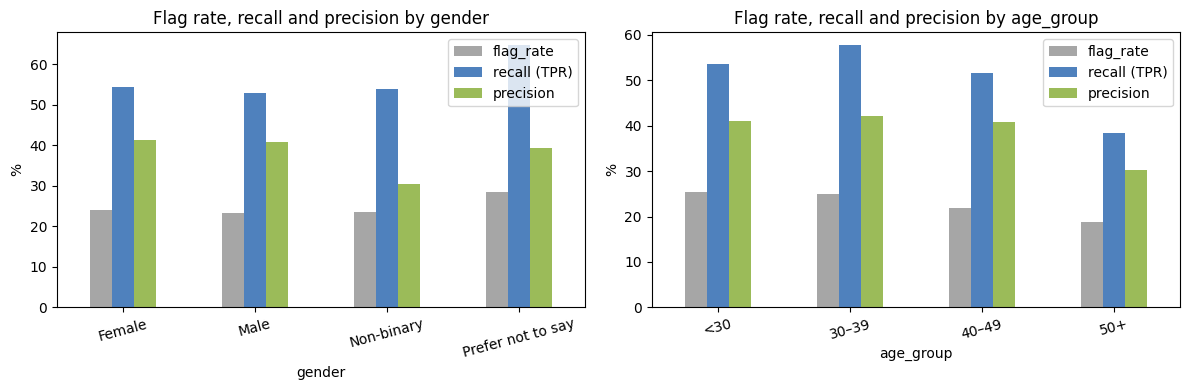

In [ ]:
def threshold_rates(s):
    y_true, flag = s['left'], s['flagged']
    return pd.Series({
        'employees': len(s),
        'flag_rate': flag.mean(),
        'recall (TPR)': recall_score(y_true, flag),
        'false_positive_rate': ((flag == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
        'precision': precision_score(y_true, flag)})

overall_rates = threshold_rates(model_df)
print("Overall (threshold 25%)")
display(overall_rates.to_frame('overall').T.style.format({'employees': '{:,.0f}', 'flag_rate': '{:.1%}',
        'recall (TPR)': '{:.1%}', 'false_positive_rate': '{:.1%}', 'precision': '{:.1%}'}))

rate_tables = {}
for g in fair_groups:
    t = model_df.groupby(g, observed=True).apply(threshold_rates)
    t['flag_rate_ratio'] = t['flag_rate'] / t['flag_rate'].max()
    rate_tables[g] = t
    print("="*30,f"Threshold outcomes by {g}","="*30)
    display(t.style.format({'employees': '{:,.0f}', 'flag_rate': '{:.1%}', 'recall (TPR)': '{:.1%}',
                            'false_positive_rate': '{:.1%}', 'precision': '{:.1%}', 'flag_rate_ratio': '{:.2f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, fair_groups):
    t = rate_tables[g][['flag_rate', 'recall (TPR)', 'precision']] * 100
    t.plot(kind='bar', ax=ax, rot=15, color=['#A6A6A6', '#4F81BD', '#9BBB59'])
    ax.set_ylabel('%'); ax.set_title(f'Flag rate, recall and precision by {g}')
plt.tight_layout()
plt.show()

**Finding:**

At the 25% threshold, women and men are treated alike, but older leavers are much less likely to be identified.

Overall, the threshold flags 23.7% of employees, catches 54.0% of leavers (recall) and has a precision of 40.9%. Female and male employees have very similar outcomes: flag rates of 23.9% vs 23.2%, recall of 54.5% vs 53.1% and precision of 41.4% vs 40.9%.

Employees aged 50+ are treated less equally. Only 18.8% are flagged, compared with 22.0%–25.3% for other age groups, giving a flag rate ratio of 0.74, below the commonly used 0.80 guideline. More importantly, the model identifies only 38.5% of leavers aged 50+, compared with 51.7%–57.7% for other age groups, and only 30.3% of flagged employees aged 50+ actually left (vs 40.9%–42.1%). Because a flag leads to supportive outreach, older employees at risk of leaving are less likely to receive it. Non-binary employees also show lower precision (30.4%), though this group is small.

**Summary of fairness gaps**

In [ ]:
gap_rows = []
for g in fair_groups:
    reliable = model_df.groupby(g, observed=True)['left'].sum() >= MIN_LEAVERS
    t = rate_tables[g][reliable.values]
    a = auc_tables[g][reliable.values]
    c = calib_tables[g][reliable.values]
    gap_rows.append({'characteristic': g,
                     'groups compared': ', '.join(map(str, t.index)),
                     'AUC gap': a['AUC'].max() - a['AUC'].min(),
                     'calibration gap (pp)': c['difference_pp'].max() - c['difference_pp'].min(),
                     'flag rate gap': t['flag_rate'].max() - t['flag_rate'].min(),
                     'recall gap': t['recall (TPR)'].max() - t['recall (TPR)'].min(),
                     'false positive rate gap': t['false_positive_rate'].max() - t['false_positive_rate'].min(),
                     'precision gap': t['precision'].max() - t['precision'].min(),
                     'lowest flag rate ratio': t['flag_rate_ratio'].min() / t['flag_rate_ratio'].max()})
gap_table = pd.DataFrame(gap_rows).set_index('characteristic')
print(f"Gaps between groups with at least {MIN_LEAVERS} leavers (largest minus smallest value)")
display(gap_table.style.format({'AUC gap': '{:.3f}', 'calibration gap (pp)': '{:.1f}', 'flag rate gap': '{:.1%}',
                                'recall gap': '{:.1%}', 'false positive rate gap': '{:.1%}',
                                'precision gap': '{:.1%}', 'lowest flag rate ratio': '{:.2f}'}))

Gaps between groups with at least 30 leavers (largest minus smallest value)


,groups compared,AUC gap,calibration gap (pp),flag rate gap,recall gap,false positive rate gap,precision gap,lowest flag rate ratio
characteristic,,,,,,,,
gender,"Female, Male",0.007,0.2,0.7%,1.4%,0.5%,0.5%,0.97
age_group,"<30, 30–39, 40–49, 50+",0.069,1.7,6.5%,19.2%,3.1%,11.8%,0.74


**Finding:**

Gender gaps are negligible; age gaps are substantial and driven by the 50+ group.

Among groups with enough leavers for reliable comparison, gender gaps are negligible on every measure: 0.007 in AUC, 0.2 percentage points in calibration, 1.4% in recall, 0.5% in false positive rate and 0.5% in precision, with a lowest flag rate ratio of 0.97.

Age gaps are considerably larger: 0.069 in AUC, 19.2% in recall, 11.8% in precision and 6.5% in flag rate, with a lowest flag rate ratio of 0.74. These gaps are mainly driven by employees aged 50+.

**Why is the model weaker for employees aged 50+?**

In [ ]:
# 1. How well does the model separate leavers from stayers in each age group?
sep = model_df.groupby(['age_group', 'left'], observed=True)['risk_score'].mean().unstack()
sep.columns = ['mean_risk_stayers', 'mean_risk_leavers']
sep['gap'] = sep['mean_risk_leavers'] - sep['mean_risk_stayers']
print("="*30,"Average predicted risk of stayers and leavers, by age group","="*30)
display(sep.style.format('{:.1%}'))

# 2. How do leavers aged 50+ differ from younger leavers?
model_df['age_50plus'] = np.where(model_df['age_group'] == '50+', '50+', 'Under 50')
profile_cols = ['risk_score', 'burnout_score', 'engagement_score', 'manager_support_score',
                'years_since_promotion', 'overtime_hours_per_week', 'years_at_company']
leaver_profile = model_df[model_df['left'] == 1].groupby('age_50plus')[profile_cols].mean()
leaver_profile['leavers'] = model_df[model_df['left'] == 1].groupby('age_50plus').size()
print("="*30,"Profile of leavers: 50+ vs under 50","="*30)
display(leaver_profile.round(2))

============================== Average predicted risk of stayers and leavers, by age group ==============================


,mean_risk_stayers,mean_risk_leavers,gap
age_group,,,
<30,15.9%,32.2%,16.3%
30–39,15.4%,32.3%,16.9%
40–49,13.9%,31.4%,17.5%
50+,14.5%,24.5%,10.0%


============================== Profile of leavers: 50+ vs under 50 ==============================


,risk_score,burnout_score,engagement_score,manager_support_score,years_since_promotion,overtime_hours_per_week,years_at_company,leavers
age_50plus,,,,,,,,
50+,0.25,4.75,5.70,5.77,2.54,7.94,9.33,52
Under 50,0.32,5.08,5.52,5.69,2.34,8.81,6.27,834


**Finding:**

Older leavers show fewer of the warning signs the model relies on.

The model separates leavers from stayers less clearly for employees aged 50+: their leavers have an average predicted risk of 24.5% vs 14.5% for their stayers, a gap of 10.0 percentage points compared with 16.3–17.5 points for other age groups. Stayers aged 50+ receive similar risk scores to other ages; it is their leavers who are scored lower.

Compared with leavers under 50, leavers aged 50+ report lower burnout (4.75 vs 5.08), slightly higher engagement (5.70 vs 5.52) and less overtime (7.94 vs 8.81 hours per week), and have much longer tenure (9.33 vs 6.27 years), which the model treats as protective. As a result, they appear lower-risk (average predicted risk 25% vs 32%) even though they left. Older employees may leave for reasons not captured in the data, such as retirement, health or caring responsibilities, but this cannot be confirmed without exit-reason data.

**Conclusion - Objective 8:**

- The model performs equally well for women and men: AUC (0.779 vs 0.772), calibration, flag rates, recall and precision are almost identical, with all gender gaps below 1.5 percentage points.

- The model is less effective for employees aged 50+. Its AUC is lower (0.724 vs 0.770–0.793 for other ages), it identifies only 38.5% of older leavers (vs 51.7%–57.7%), and their flag rate ratio (0.74) falls below the commonly used 0.80 guideline.

- This gap does not come from the model using age, which was excluded, but from older leavers showing fewer of the warning signs it relies on: lower burnout, less overtime and longer tenure, which the model treats as protective.

- Predicted risk is accurate across gender and age groups (ratios 0.97–1.08), except for non-binary employees, whose risk is overestimated (ratio 1.34); this group, like "prefer not to say", is too small for reliable conclusions.

**Business implications**
1. **The model can be used for women and men without adjustment.** There is no evidence of gender-based differences in how it identifies or flags employees.
2. **Do not rely on the risk score alone for employees aged 50+.** Because the model misses more older leavers, HR should supplement it for this group, for example through regular career and retirement-planning conversations, flexible work options and stay interviews, rather than waiting for a flag.
3. **Collect exit reasons.** Recording why employees leave (e.g. retirement, health, caring responsibilities, better offer) would help explain the 50+ gap and could improve the model for older employees.
4. **Monitor fairness regularly.** Fairness checks should be repeated whenever the model is retrained or the workforce changes, with particular attention to the 50+ group and to small groups as more data becomes available.
5. **Use flags only for supportive outreach.** Since flagging leads to retention support, groups that are flagged less (such as employees aged 50+) risk missing out; flags should never be used for performance or employment decisions.

**Limitations**
- The non-binary and "prefer not to say" groups have too few leavers (13 and 17) for reliable conclusions, and the 50+ group (52 leavers) is the smallest age band, so its estimates are less precise.
- The 50+ AUC gap is close to but not quite statistically significant (95% CI −0.121 to 0.010), so it should be confirmed with more data.
- The explanation for the 50+ gap (reasons for leaving not captured in the data) is a hypothesis; the dataset has no exit reasons to test it.
- Only gender and age were checked. Other characteristics, such as ethnicity or disability, could not be assessed because they are not in the dataset.
- The four-fifths (0.80) guideline comes from US employment selection practice and is used here as a reference point, not a legal standard for this context.

# Summary of findings and recommendations

## Key findings

**1. Attrition is concentrated in specific groups, but group membership alone explains little**
Overall attrition is 17.9%. It is highest in Customer Support (24.1%), among onsite employees (21.2%) and among employees with lower performance ratings (28.7% at rating 2), and lowest in Engineering (14.5%), among remote employees (14.7%) and among top performers (7.5% at rating 5). All these associations are weak on their own (Cramér's V below 0.15), job role differences are explained by department, and job level has no reliable effect.

**2. Wellbeing is the strongest driver of attrition**
Burnout, engagement and manager support have much larger effects than any group factor. Low-burnout employees (score 1–3) leave at 4.6%, compared with 51.5% for those scoring 7–8.5. Wellbeing factors alone nearly match the full risk model (CV AUC 0.762 vs 0.777). Overtime affects attrition mainly by increasing burnout: about 91% of its effect runs through burnout.

**3. Stalled careers matter more than pay level**
Employees are more likely to leave when they receive small salary increases or wait long for promotion. Attrition rises from 14.2% for employees promoted within the last year to 35.5% for those waiting more than 6 years. Pay relative to peers has no independent effect. Salary increases barely reflect performance, and well-rated employees on low raises leave at nearly twice the rate of those on high raises (rating 4: 20.4% vs 11.0%).

**4. AI-related job anxiety is a distinct driver; work arrangements are not**
Employees who feel their job is at risk from AI are more likely to leave (about +11% odds per point), even compared with colleagues in the same department with similar wellbeing. Using AI tools does not reduce this effect. The higher attrition of onsite employees is largely explained by their higher burnout, and commute and business travel have no independent effect.

**5. A simple model can identify most at-risk employees**
A logistic regression identifies at-risk employees well (test AUC 0.769; PR-AUC 0.424 vs 0.180 for random guessing). The riskiest 20% of employees contain 45.5% of leavers, and attrition ranges from 4.9% in the Low risk tier to 51.2% in the Very high tier. High-risk employees are most concentrated in Customer Support (39.4%) and among onsite employees (29.5%).

**6. Most key drivers are within the company's control**
Eight factors independently drive attrition, led by burnout (+32.6% odds per point), manager support (−19.2%), years since promotion (+18.8% per year) and engagement (−15.8%). Seven of the eight are factors the company can change or influence, accounting for 87.9% of the model's predictive power. Personal characteristics such as age and marital status are not linked to attrition.

**7. Attrition is costly, and targeted action offers strong returns**
Attrition costs an estimated $35.5 million per year in the base case (8.54% of payroll; range $21.3–70.9 million). Employees in the High and Very high risk tiers (23.7% of the workforce) account for 53.0% of expected cost. A targeted package improving burnout, manager support, overtime and promotion timing for this group could avoid about 165 leavers and save $6.54 million per year, delivering half the savings of a company-wide programme while treating fewer than a quarter of employees.

**8. The model is fair across gender but less effective for employees aged 50+**
The model performs almost identically for women and men (AUC 0.779 vs 0.772). It is less effective for employees aged 50+ (AUC 0.724) and identifies only 38.5% of older leavers, compared with 51.7%–57.7% for other ages, because older leavers show fewer of the warning signs the model relies on.

## Recommendations (in priority order)

**1. Launch a targeted retention programme for High and Very high risk employees**
Use the risk tiers to prioritise the 23.7% of employees who account for 53.0% of expected attrition cost. Starting with Customer Support and onsite teams, where high-risk employees are most concentrated, this approach delivers half the potential savings of a company-wide programme. Any programme costing less than about `$1,679`–`$5,595` per employee (depending on assumptions) would be expected to pay for itself.

**2. Make burnout reduction the first priority**
Burnout is the strongest driver of attrition and the largest source of the model's predictive power. Reducing it by 1 point among high-risk employees could save an estimated $2.75 million per year. Monitor burnout through regular pulse surveys, manage sustained overtime (the main route through which workload affects attrition), and rebalance workloads in teams where burnout is rising.

**3. Invest in managers**
Manager support is the strongest protective factor (−19.2% odds per point) and is largely independent of workload. Provide manager training, set expectations for regular one-to-ones, and include team wellbeing and retention in manager performance goals.

**4. Fix career progression before pay levels**
Review employees approaching 3 years without promotion, offering a promotion, stretch role or clear career-path discussion. Link salary increases more closely to performance, so that strong performers are visibly rewarded. Targeted raises and promotions are likely to be more effective than broad pay adjustments, since pay relative to peers does not independently predict exits.

**5. Address AI-related job anxiety**
Communicate clearly how AI will change roles and offer reskilling paths, particularly in Customer Support, where perceived AI risk is highest. Rolling out AI tools alone does not reduce this effect.

**6. Use the risk model responsibly and supplement it where it is weaker**
Use risk scores only to start supportive conversations, never for performance or employment decisions; around 6 in 10 flagged employees do not leave. For employees aged 50+, whom the model identifies less well, supplement the score with regular career, flexible-work and retirement-planning conversations. Repeat fairness checks whenever the model is retrained.

**7. Improve the data for future analysis**
Collect exit reasons, record dates (hire, exit and survey dates), and measure actual replacement costs from recruitment and onboarding records. This would allow true turnover trends, earlier-warning predictions, more accurate cost estimates and a better understanding of why older employees leave.

## Data limitations

- **Single snapshot with no dates:** attrition cannot be measured over time, turnover trends cannot be calculated, and the model shows who is at risk at one point in time rather than how far in advance an exit can be predicted.
- **Associations, not causes:** all findings are associations. Some may reflect reverse effects; for example, employees already planning to leave may report lower engagement or receive smaller raises. Savings estimates assume causal effects and may overstate real-world results; a 50%-effect scenario is provided as a more cautious estimate.
- **Self-reported measures:** burnout, engagement, manager support, work-life balance and perceived AI risk are self-reported and may be influenced by employees' intentions to leave.
- **Data quality issues:** 1,358 employees (27.2%) have at least one data-quality flag, including 59 with impossible tenure values, inconsistent work-history fields and job role/level mismatches. Affected fields were excluded or treated with caution, and key results were confirmed without flagged rows.
- **No exit reasons:** the dataset does not record why employees leave, so voluntary and involuntary exits cannot be separated, and causes such as retirement or relocation cannot be identified. This likely explains part of the model's weaker performance for employees aged 50+.
- **Missing financial context:** salaries have no currency (treated as AUD), and there is no market salary data, so pay can only be compared within the company. Replacement costs are based on secondary, mostly US estimates rather than the company's own data.
- **Small groups:** non-binary employees (13 leavers) and employees who preferred not to state their gender (17 leavers) are too small for reliable conclusions, and the 50+ group (52 leavers) gives less precise estimates.
- **Limited fairness scope:** only gender and age could be checked; other characteristics, such as ethnicity or disability, are not in the dataset.
- **Synthetic data:** the dataset appears to be synthetic, so patterns may be cleaner or more consistent than in real HR data, and findings demonstrate the analytical approach rather than describing a real organisation.